<a href="https://colab.research.google.com/github/Khamdanfakhryza/PROJECT-MRI/blob/main/MRI_penelitian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q roboflow ultralytics

In [ ]:
import os
from getpass import getpass
from roboflow import Roboflow

# Masukkan API Key secara tersembunyi
os.environ["ROBOFLOW_API_KEY"] = getpass(
    "3WBYVkip2y9ZNtEmYVTG"
)

# Inisialisasi Roboflow
rf = Roboflow(
    api_key=os.environ["ROBOFLOW_API_KEY"]
)

# Mengakses project
project = (
    rf.workspace("ali-rostami")
      .project("labeled-mri-brain-tumor-dataset")
)

# Mengambil dataset version 1
version = project.version(1)

# Download format YOLOv8
dataset = version.download("yolov8")

DATASET_PATH = dataset.location

print("Dataset berhasil diunduh!")
print("Lokasi:", DATASET_PATH)

3WBYVkip2y9ZNtEmYVTG··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Labeled-MRI-Brain-Tumor-Dataset-1 in yolov8:: 100%|██████████| 4898/4898 [00:00<00:00, 8913.31it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset berhasil diunduh!
Lokasi: /content/Labeled-MRI-Brain-Tumor-Dataset-1


In [ ]:
from pathlib import Path

root = Path(DATASET_PATH)

print("Struktur dataset:")

for item in root.iterdir():
    print(item.name)

Struktur dataset:
README.roboflow.txt
train
data.yaml
valid
README.dataset.txt
test


In [ ]:
import yaml

yaml_path = root / "data.yaml"

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("Dataset Configuration:")
print(data_config)

Dataset Configuration:
{'names': ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary'], 'nc': 4, 'roboflow': {'license': 'CC BY 4.0', 'project': 'labeled-mri-brain-tumor-dataset', 'url': 'https://universe.roboflow.com/ali-rostami/labeled-mri-brain-tumor-dataset/dataset/1', 'version': 1, 'workspace': 'ali-rostami'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [ ]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/Labeled-MRI-Brain-Tumor-Dataset-1")

splits = ["train", "valid", "test"]

print("=" * 55)
print("CLEAR-MRI: DATASET STATISTICS")
print("=" * 55)

total_images = 0
total_labels = 0

for split in splits:

    image_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    images = [
        f for f in image_dir.iterdir()
        if f.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]

    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Labels :", len(labels))

    total_images += len(images)
    total_labels += len(labels)

print("\n" + "=" * 55)
print("TOTAL DATASET")
print("=" * 55)

print("Total Images :", total_images)
print("Total Labels :", total_labels)

CLEAR-MRI: DATASET STATISTICS

TRAIN
Images : 1695
Labels : 1695

VALID
Images : 502
Labels : 502

TEST
Images : 246
Labels : 246

TOTAL DATASET
Total Images : 2443
Total Labels : 2443


In [ ]:
from collections import Counter
import yaml

with open(ROOT / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

class_names = config["names"]

class_counter = Counter()
image_class_counter = Counter()

empty_labels = 0
missing_labels = 0
invalid_labels = 0

for split in ["train", "valid", "test"]:

    image_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    for image in image_dir.iterdir():

        if image.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        ]:
            continue

        label_file = label_dir / (image.stem + ".txt")

        if not label_file.exists():
            missing_labels += 1
            continue

        lines = label_file.read_text().strip().splitlines()

        if not lines:
            empty_labels += 1
            continue

        image_classes = set()

        for line in lines:

            values = line.split()

            if len(values) != 5:
                invalid_labels += 1
                continue

            try:
                cls = int(float(values[0]))
                bbox = list(map(float, values[1:]))

                if cls < 0 or cls >= len(class_names):
                    invalid_labels += 1
                    continue

                if not all(0 <= x <= 1 for x in bbox):
                    invalid_labels += 1
                    continue

                if bbox[2] <= 0 or bbox[3] <= 0:
                    invalid_labels += 1
                    continue

                class_counter[cls] += 1
                image_classes.add(cls)

            except ValueError:
                invalid_labels += 1

        for cls in image_classes:
            image_class_counter[cls] += 1

print("CLASS DISTRIBUTION")
print("=" * 45)

for cls, name in enumerate(class_names):

    print(
        f"{name:15s} | "
        f"Annotations: {class_counter[cls]:5d} | "
        f"Images: {image_class_counter[cls]:5d}"
    )

print("\nLABEL VALIDATION")
print("Empty labels   :", empty_labels)
print("Missing labels :", missing_labels)
print("Invalid labels :", invalid_labels)

CLASS DISTRIBUTION
Glioma          | Annotations:   830 | Images:   805
Meningioma      | Annotations:   547 | Images:   545
No Tumor        | Annotations:   483 | Images:   483
Pituitary       | Annotations:   612 | Images:   610

LABEL VALIDATION
Empty labels   : 0
Missing labels : 0
Invalid labels : 0


In [ ]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for split in ["train", "valid", "test"]:

    image_dir = ROOT / split / "images"

    for image in image_dir.iterdir():

        if image.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        ]:
            continue

        with open(image, "rb") as f:
            image_hash = hashlib.sha256(f.read()).hexdigest()

        hash_groups[image_hash].append(
            (split, image.name)
        )

duplicates = {
    h: files
    for h, files in hash_groups.items()
    if len(files) > 1
}

print("TOTAL UNIQUE IMAGE HASH:", len(hash_groups))
print("DUPLICATE GROUPS:", len(duplicates))

for h, files in list(duplicates.items())[:10]:
    print(files)

TOTAL UNIQUE IMAGE HASH: 2443
DUPLICATE GROUPS: 0


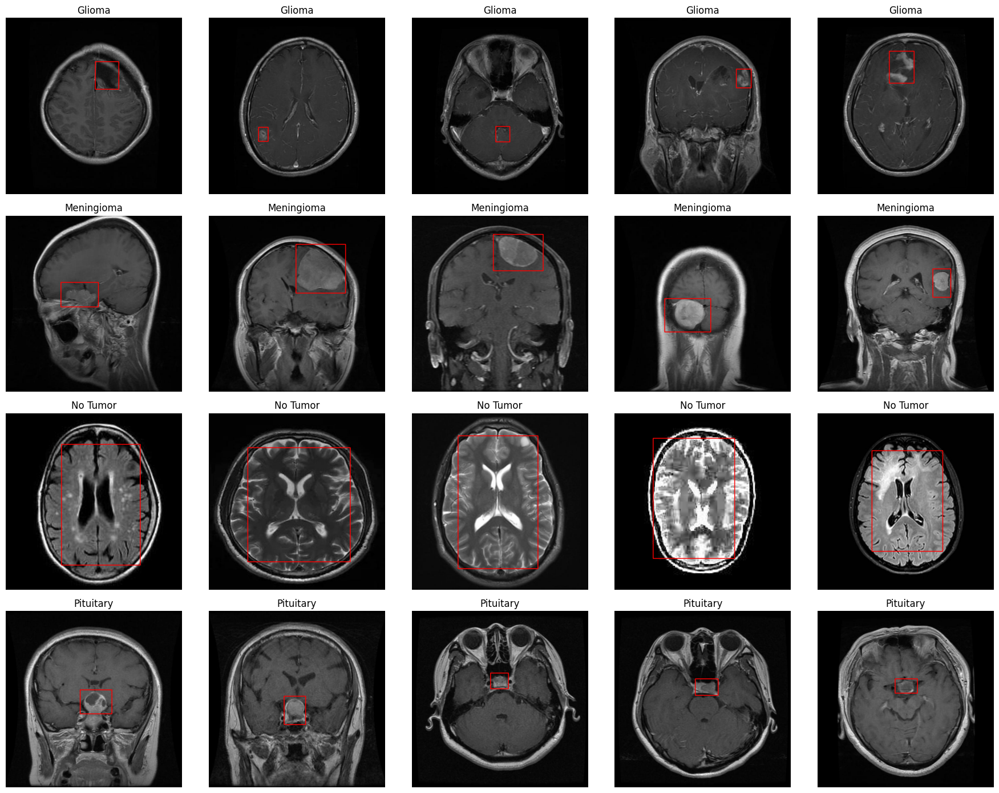

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/Labeled-MRI-Brain-Tumor-Dataset-1")

class_names = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

random.seed(42)

fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for class_id, class_name in enumerate(class_names):

    image_dir = ROOT / "train" / "images"
    label_dir = ROOT / "train" / "labels"

    samples = []

    for image_path in image_dir.iterdir():

        label_path = label_dir / (image_path.stem + ".txt")

        if not label_path.exists():
            continue

        lines = label_path.read_text().strip().splitlines()

        for line in lines:

            values = line.split()

            if len(values) == 5 and int(float(values[0])) == class_id:
                samples.append(image_path)
                break

    selected = random.sample(
        samples,
        min(5, len(samples))
    )

    for col, image_path in enumerate(selected):

        img = cv2.imread(str(image_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        h, w = img.shape[:2]

        label_path = label_dir / (image_path.stem + ".txt")

        for line in label_path.read_text().strip().splitlines():

            values = line.split()

            if len(values) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, values)

            if int(cls) != class_id:
                continue

            x1 = int((xc - bw/2) * w)
            y1 = int((yc - bh/2) * h)
            x2 = int((xc + bw/2) * w)
            y2 = int((yc + bh/2) * h)

            cv2.rectangle(
                img,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

        ax = axes[class_id, col]
        ax.imshow(img)
        ax.set_title(class_name)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI"
)

folders = [
    "01_DATASET/Original",
    "01_DATASET/Audited",
    "01_DATASET/External_Dataset",
    "02_NOTEBOOK",
    "03_MODEL/YOLOv8",
    "03_MODEL/YOLO26",
    "03_MODEL/CLEAR_MRI",
    "04_EXPERIMENT/Training_Results",
    "04_EXPERIMENT/Validation",
    "04_EXPERIMENT/Ablation_Study",
    "04_EXPERIMENT/External_Testing",
    "05_VISUALIZATION",
    "06_ANALYSIS",
    "07_PUBLICATION"
]

for folder in folders:
    (BASE_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Struktur CLEAR-MRI berhasil dibuat!")

Struktur CLEAR-MRI berhasil dibuat!


In [ ]:
import shutil

SOURCE = Path(
    "/content/Labeled-MRI-Brain-Tumor-Dataset-1"
)

DESTINATION = (
    BASE_DIR / "01_DATASET/Original"
    / "Labeled-MRI-Brain-Tumor-Dataset-1"
)

if not DESTINATION.exists():
    shutil.copytree(SOURCE, DESTINATION)

print("Dataset berhasil disimpan di Google Drive.")

Dataset berhasil disimpan di Google Drive.


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

results = model.train(
    data=str(DESTINATION / "data.yaml"),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    project=str(
        BASE_DIR / "04_EXPERIMENT/Training_Results"
    ),
    name="YOLOv8s_Baseline",
    exist_ok=True,
    save=True,
    save_period=5,
    seed=42
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.

ulihkan lingkungan Google Colab

In [ ]:
!pip install -q ultralytics roboflow

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA Available: True
GPU: Tesla T4


In [ ]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI"
)

MODEL_PATH = (
    BASE_DIR /
    "04_EXPERIMENT/Training_Results/"
    "YOLOv8s_Baseline/weights/best.pt"
)

print("Model exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    print("Model size:", round(
        MODEL_PATH.stat().st_size / (1024**2), 2
    ), "MB")

Model exists: True
Model size: 21.48 MB


In [ ]:
DATASET_PATH = (
    BASE_DIR /
    "01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1"
)

print("Dataset exists:", DATASET_PATH.exists())

Dataset exists: True


In [ ]:
from ultralytics import YOLO

model = YOLO(str(MODEL_PATH))

test_results = model.val(
    data=str(DATASET_PATH / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    project=str(
        BASE_DIR / "04_EXPERIMENT/Validation"
    ),
    name="YOLOv8s_Test_Evaluation",
    exist_ok=True
)

print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 133.1±294.9 ms, read: 2.2±4.8 MB/s, size: 25.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test/labels... 246 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 246/246 2.3it/s 1:45
val: New cache created: /content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.4it/s 4.7s
                   all        246        250      0.945      0.945      0.957      0.616
                Glioma         80         84      0.975   

In [ ]:
!pip install -q ultralytics

oke sampai sini

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd
import os

# Google Drive
BASE_DIR = Path("/content/drive/MyDrive/CLEAR-MRI")

# Dataset
DATASET_PATH = (
    BASE_DIR /
    "01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1"
)

# Model baseline
MODEL_PATH = (
    BASE_DIR /
    "04_EXPERIMENT/Training_Results/"
    "YOLOv8s_Baseline/weights/best.pt"
)

# Folder hasil analisis
ANALYSIS_DIR = (
    BASE_DIR /
    "06_ANALYSIS/Baseline_Experiment_02"
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))

print("Model berhasil dimuat.")
print("Dataset:", DATASET_PATH.exists())
print("Model:", MODEL_PATH.exists())

Model berhasil dimuat.
Dataset: True
Model: True


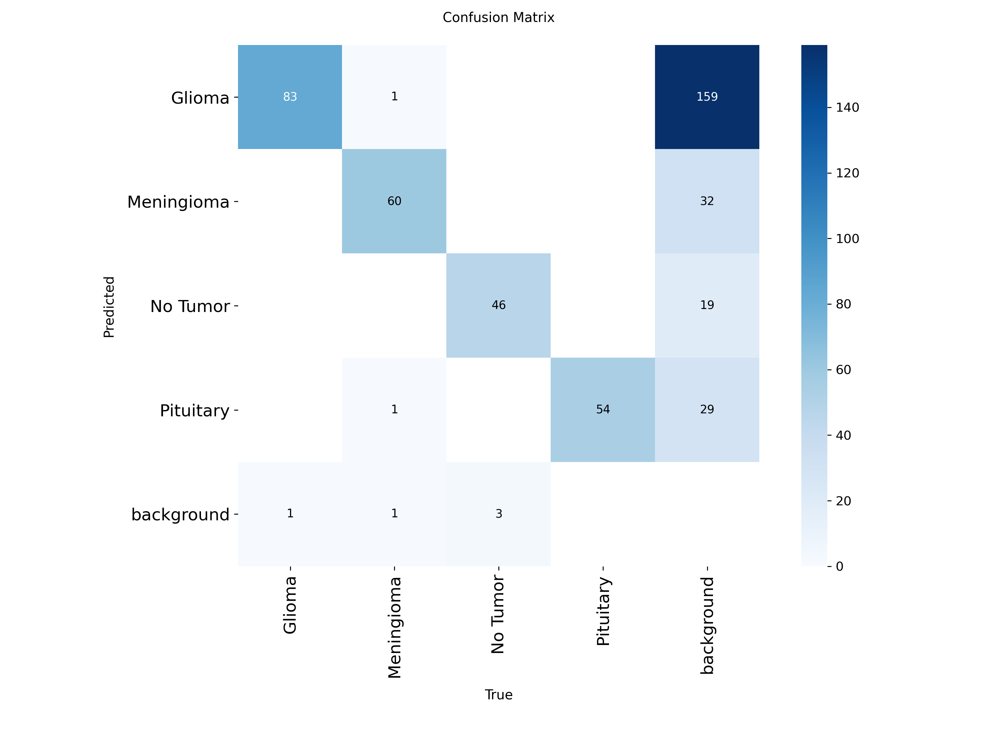

In [ ]:
from IPython.display import display, Image

CM_PATH = (
    BASE_DIR /
    "04_EXPERIMENT/Validation/"
    "YOLOv8s_Test_Evaluation/"
    "confusion_matrix.png"
)

CM_NORMALIZED_PATH = (
    BASE_DIR /
    "04_EXPERIMENT/Validation/"
    "YOLOv8s_Test_Evaluation/"
    "confusion_matrix_normalized.png"
)

if CM_PATH.exists():

    display(Image(filename=str(CM_PATH)))

else:
    print("Confusion matrix belum ditemukan.")

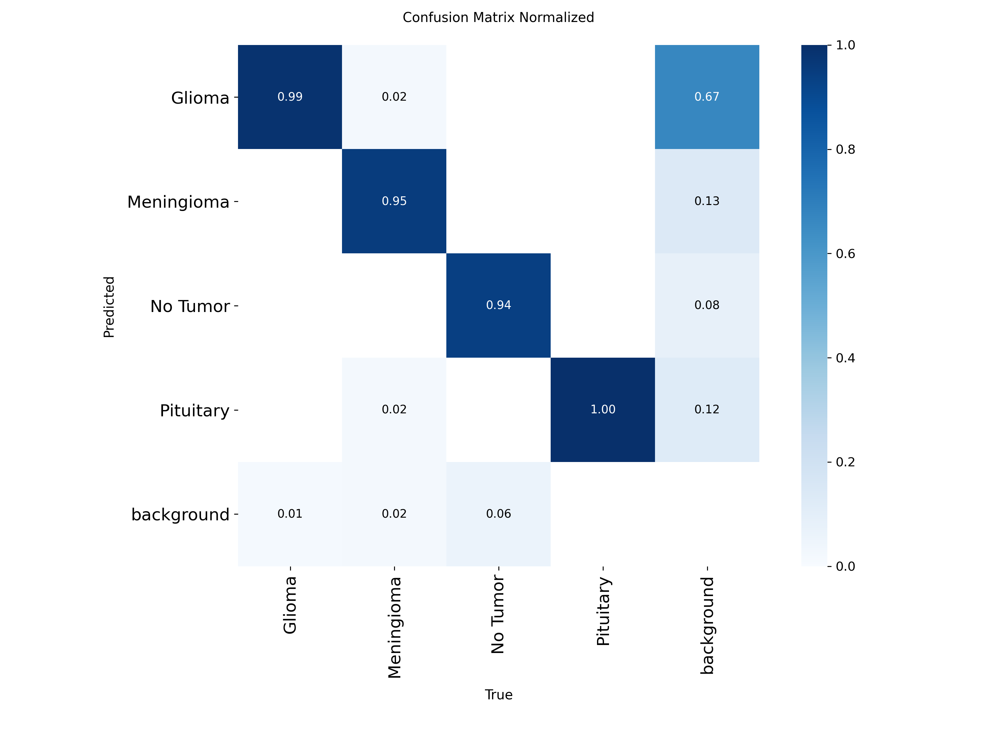

In [ ]:
if CM_NORMALIZED_PATH.exists():

    display(Image(filename=str(CM_NORMALIZED_PATH)))

else:
    print("Normalized confusion matrix belum ditemukan.")

In [ ]:
import random

TEST_DIR = DATASET_PATH / "test/images"

VIS_DIR = ANALYSIS_DIR / "Prediction_Visualization"
VIS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(42)

image_files = []

for ext in ["*.jpg", "*.jpeg", "*.png"]:
    image_files.extend(TEST_DIR.glob(ext))

selected_images = random.sample(
    image_files,
    min(20, len(image_files))
)

results = model.predict(
    source=[str(x) for x in selected_images],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(VIS_DIR),
    name="YOLOv8s_Test_Predictions",
    exist_ok=True
)

print("Jumlah gambar diperiksa:", len(results))
print("Hasil tersimpan:", VIS_DIR)


0: 640x640 2 Gliomas, 10.2ms
1: 640x640 2 Gliomas, 10.2ms
2: 640x640 1 Pituitary, 10.2ms
3: 640x640 1 Glioma, 10.2ms
4: 640x640 2 Gliomas, 10.2ms
5: 640x640 1 Pituitary, 10.2ms
6: 640x640 1 No Tumor, 10.2ms
7: 640x640 1 Meningioma, 10.2ms
8: 640x640 1 Pituitary, 10.2ms
9: 640x640 1 Meningioma, 10.2ms
10: 640x640 1 Glioma, 1 Meningioma, 10.2ms
11: 640x640 1 Meningioma, 10.2ms
12: 640x640 1 Glioma, 10.2ms
13: 640x640 1 Meningioma, 10.2ms
14: 640x640 1 Pituitary, 10.2ms
15: 640x640 1 Meningioma, 1 No Tumor, 10.2ms
16: 640x640 1 Meningioma, 10.2ms
17: 640x640 1 Meningioma, 10.2ms
18: 640x640 1 Glioma, 10.2ms
19: 640x640 1 Meningioma, 10.2ms
Speed: 2.7ms preprocess, 10.2ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Baseline_Experiment_02/Prediction_Visualization/YOLOv8s_Test_Predictions
Jumlah gambar diperiksa: 20
Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Baseline_Experiment_02/Predictio

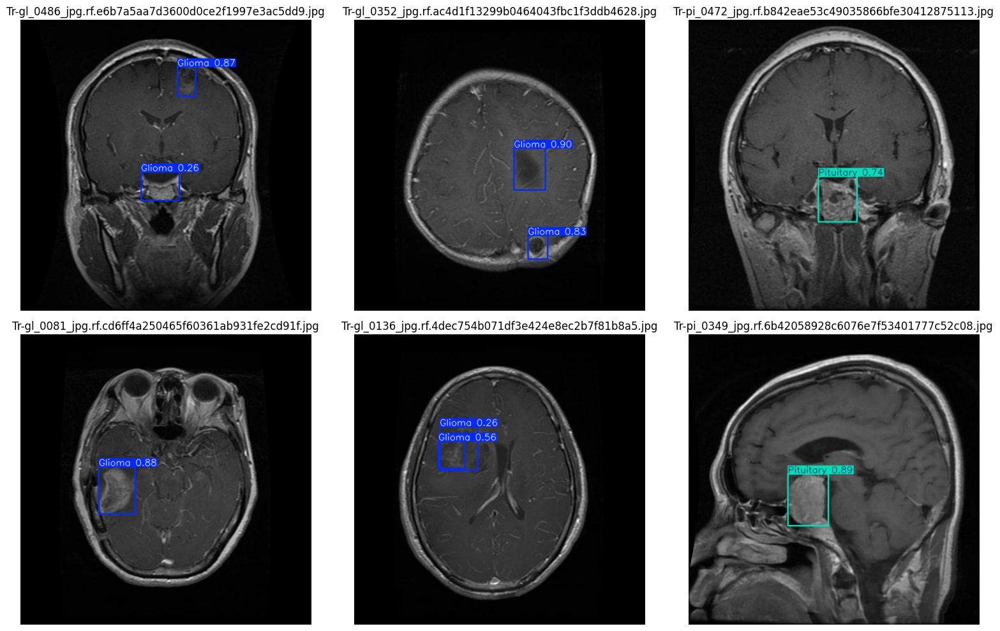

In [ ]:
prediction_files = list(
    (VIS_DIR / "YOLOv8s_Test_Predictions").glob("*")
)

prediction_files = [
    x for x in prediction_files
    if x.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, image_path in zip(axes.flat, prediction_files[:6]):

    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    ANALYSIS_DIR / "Prediction_Samples.png",
    dpi=300
)

plt.show()

In [ ]:
from ultralytics.utils.metrics import box_iou

IOU_DIR = ANALYSIS_DIR / "Localization_Analysis"
IOU_DIR.mkdir(parents=True, exist_ok=True)

test_images = sorted([
    x for x in TEST_DIR.iterdir()
    if x.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

iou_records = []

for image_path in test_images:

    label_path = (
        DATASET_PATH / "test/labels"
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():
        continue

    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]

    # Ground truth
    gt = []

    for line in label_path.read_text().splitlines():

        values = list(map(float, line.split()))

        cls, xc, yc, bw, bh = values

        x1 = (xc - bw/2) * w
        y1 = (yc - bh/2) * h
        x2 = (xc + bw/2) * w
        y2 = (yc + bh/2) * h

        gt.append([int(cls), x1, y1, x2, y2])

    # Prediction
    pred_result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    pred = []

    if pred_result.boxes is not None:

        for box in pred_result.boxes:

            cls = int(box.cls.item())
            confidence = float(box.conf.item())

            xyxy = box.xyxy[0].cpu().numpy()

            pred.append([
                cls,
                *xyxy,
                confidence
            ])

    # Matching berdasarkan kelas dan IoU
    for cls in range(4):

        gt_cls = [x for x in gt if x[0] == cls]
        pred_cls = [x for x in pred if x[0] == cls]

        if not gt_cls:
            continue

        if not pred_cls:

            for _ in gt_cls:
                iou_records.append({
                    "image": image_path.name,
                    "class_id": cls,
                    "class_name": model.names[cls],
                    "IoU": 0.0,
                    "matched": False
                })

            continue

        gt_boxes = np.array(
            [x[1:5] for x in gt_cls]
        )

        pred_boxes = np.array(
            [x[1:5] for x in pred_cls]
        )

        ious = box_iou(
            torch.tensor(gt_boxes, dtype=torch.float32),
            torch.tensor(pred_boxes, dtype=torch.float32)
        ).numpy()

        from scipy.optimize import linear_sum_assignment

        rows, cols = linear_sum_assignment(-ious)

        matched_gt = set()

        for r, c in zip(rows, cols):

            value = float(ious[r, c])

            iou_records.append({
                "image": image_path.name,
                "class_id": cls,
                "class_name": model.names[cls],
                "IoU": value,
                "matched": True
            })

            matched_gt.add(r)

        # Ground truth yang tidak memperoleh pasangan
        for idx in range(len(gt_cls)):

            if idx not in matched_gt:

                iou_records.append({
                    "image": image_path.name,
                    "class_id": cls,
                    "class_name": model.names[cls],
                    "IoU": 0.0,
                    "matched": False
                })

iou_df = pd.DataFrame(iou_records)

iou_df.to_csv(
    IOU_DIR / "Localization_IoU_Results.csv",
    index=False
)

print("Localization analysis selesai.")
display(iou_df.head())

Localization analysis selesai.


,image,class_id,class_name,IoU,matched
0,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,0,Glioma,0.873254,True
1,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a6...,0,Glioma,0.804352,True
2,Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c4504...,0,Glioma,0.924549,True
3,Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad...,0,Glioma,0.899660,True
4,Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf42a0c86b97f8...,0,Glioma,0.967162,True


In [ ]:
iou_summary = (
    iou_df.groupby("class_name")
    .agg(
        Mean_IoU=("IoU", "mean"),
        Median_IoU=("IoU", "median"),
        Matched=("matched", "sum"),
        Total=("matched", "count")
    )
)

iou_summary["Match_Rate"] = (
    iou_summary["Matched"] /
    iou_summary["Total"]
)

display(iou_summary)

iou_summary.to_csv(
    IOU_DIR / "Localization_Summary.csv"
)

,Mean_IoU,Median_IoU,Matched,Total,Match_Rate
class_name,,,,,
Glioma,0.836135,0.904111,80,84,0.952381
Meningioma,0.763669,0.812454,60,63,0.952381
No Tumor,0.758801,0.869328,44,49,0.897959
Pituitary,0.750879,0.776656,54,54,1.000000


In [ ]:
import json

baseline_report = {
    "experiment": "CLEAR-MRI Baseline Experiment 02",
    "model": "YOLOv8s",
    "dataset_version": 1,
    "test_images": 246,
    "test_instances": 250,
    "precision": 0.9451346,
    "recall": 0.9445918,
    "mAP50": 0.9571572,
    "mAP50_95": 0.6156693,
    "gpu": "NVIDIA Tesla T4",
    "framework": "Ultralytics 8.4.203"
}

with open(
    ANALYSIS_DIR / "Baseline_Report.json",
    "w"
) as f:

    json.dump(
        baseline_report,
        f,
        indent=4
    )

print("Dokumentasi eksperimen berhasil disimpan.")

Dokumentasi eksperimen berhasil disimpan.


In [ ]:
import torch
import numpy as np
import pandas as pd
import cv2

from pathlib import Path
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO

IOU_THRESHOLD = 0.50
CONF_THRESHOLD = 0.25

records = []

for image_path in test_images:

    label_path = (
        DATASET_PATH / "test/labels"
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():
        continue

    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]

    gt = []

    for line in label_path.read_text().splitlines():

        values = list(map(float, line.split()))

        cls, xc, yc, bw, bh = values

        gt.append([
            int(cls),
            (xc-bw/2)*w,
            (yc-bh/2)*h,
            (xc+bw/2)*w,
            (yc+bh/2)*h
        ])

    result = model.predict(
        str(image_path),
        imgsz=640,
        conf=CONF_THRESHOLD,
        device=0,
        verbose=False
    )[0]

    pred = []

    if result.boxes is not None:

        for box in result.boxes:

            pred.append([
                int(box.cls.item()),
                *box.xyxy[0].cpu().numpy().tolist(),
                float(box.conf.item())
            ])

    for cls in range(4):

        gt_cls = [x for x in gt if x[0] == cls]
        pred_cls = [x for x in pred if x[0] == cls]

        if len(gt_cls) == 0 and len(pred_cls) == 0:
            continue

        if len(gt_cls) == 0:

            for p in pred_cls:
                records.append({
                    "image": image_path.name,
                    "class_name": model.names[cls],
                    "IoU": 0,
                    "status": "FP"
                })

            continue

        if len(pred_cls) == 0:

            for g in gt_cls:
                records.append({
                    "image": image_path.name,
                    "class_name": model.names[cls],
                    "IoU": 0,
                    "status": "FN"
                })

            continue

        gt_boxes = np.array([x[1:5] for x in gt_cls])
        pred_boxes = np.array([x[1:5] for x in pred_cls])

        iou_matrix = box_iou(
            torch.tensor(gt_boxes, dtype=torch.float32),
            torch.tensor(pred_boxes, dtype=torch.float32)
        ).numpy()

        rows, cols = linear_sum_assignment(-iou_matrix)

        matched_gt = set()
        matched_pred = set()

        for r, c in zip(rows, cols):

            iou = float(iou_matrix[r, c])

            if iou >= IOU_THRESHOLD:

                matched_gt.add(r)
                matched_pred.add(c)

                status = "TP"

            else:
                continue

            records.append({
                "image": image_path.name,
                "class_name": model.names[cls],
                "IoU": iou,
                "status": status
            })

        for i in range(len(gt_cls)):

            if i not in matched_gt:

                records.append({
                    "image": image_path.name,
                    "class_name": model.names[cls],
                    "IoU": 0,
                    "status": "FN"
                })

        for i in range(len(pred_cls)):

            if i not in matched_pred:

                records.append({
                    "image": image_path.name,
                    "class_name": model.names[cls],
                    "IoU": 0,
                    "status": "FP"
                })

corrected_df = pd.DataFrame(records)

corrected_df.to_csv(
    IOU_DIR / "Localization_Threshold_050.csv",
    index=False
)

summary = corrected_df.groupby("class_name").agg(
    TP=("status", lambda x: (x == "TP").sum()),
    FP=("status", lambda x: (x == "FP").sum()),
    FN=("status", lambda x: (x == "FN").sum())
)

summary["Precision"] = (
    summary["TP"] /
    (summary["TP"] + summary["FP"]).replace(0, np.nan)
)

summary["Recall"] = (
    summary["TP"] /
    (summary["TP"] + summary["FN"]).replace(0, np.nan)
)

display(summary)

summary.to_csv(
    IOU_DIR / "Localization_Threshold_050_Summary.csv"
)

,TP,FP,FN,Precision,Recall
class_name,,,,,
Glioma,79,8,5,0.908046,0.940476
Meningioma,59,3,4,0.951613,0.936508
No Tumor,43,5,6,0.895833,0.877551
Pituitary,52,5,2,0.912281,0.962963


In [ ]:
from ultralytics.utils.metrics import box_iou

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

MODEL_PATH = (
    BASE_DIR /
    "04_EXPERIMENT/Training_Results/"
    "YOLOv8s_Baseline/weights/best.pt"
)

VAL_DIR = DATASET_PATH / "valid/images"
VAL_LABEL_DIR = DATASET_PATH / "valid/labels"

CAL_DIR = (
    BASE_DIR /
    "06_ANALYSIS/Confidence_Calibration"
)

CAL_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))

print("Model:", MODEL_PATH.exists())
print("Validation images:", len(list(VAL_DIR.glob("*"))))

Model: True
Validation images: 502


In [ ]:
from scipy.optimize import linear_sum_assignment

CONF_MIN = 0.001
IOU_THRESHOLD = 0.50

calibration_records = []

image_files = sorted([
    p for p in VAL_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

for image_path in image_files:

    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue

    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]

    gt = []

    for line in label_path.read_text().splitlines():

        values = list(map(float, line.split()))

        cls, xc, yc, bw, bh = values

        gt.append([
            int(cls),
            (xc-bw/2)*w,
            (yc-bh/2)*h,
            (xc+bw/2)*w,
            (yc+bh/2)*h
        ])

    result = model.predict(
        str(image_path),
        imgsz=640,
        conf=CONF_MIN,
        device=0,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is not None:

        for box in result.boxes:

            predictions.append({
                "class_id": int(box.cls.item()),
                "confidence": float(box.conf.item()),
                "xyxy": box.xyxy[0].cpu().numpy()
            })

    for cls in range(4):

        gt_cls = [x for x in gt if x[0] == cls]

        pred_cls = [
            x for x in predictions
            if x["class_id"] == cls
        ]

        # Urutkan berdasarkan confidence tertinggi
        pred_cls.sort(
            key=lambda x: x["confidence"],
            reverse=True
        )

        matched_gt = set()

        for pred in pred_cls:

            best_iou = 0
            best_gt = None

            for idx, gt_box in enumerate(gt_cls):

                if idx in matched_gt:
                    continue

                pred_box = torch.tensor(
                    pred["xyxy"],
                    dtype=torch.float32
                ).reshape(1, 4)

                gt_tensor = torch.tensor(
                    gt_box[1:5],
                    dtype=torch.float32
                ).reshape(1, 4)

                iou = float(
                    box_iou(gt_tensor, pred_box)[0, 0]
                )

                if iou > best_iou:

                    best_iou = iou
                    best_gt = idx

            is_correct = (
                best_gt is not None
                and best_iou >= IOU_THRESHOLD
            )

            if is_correct:
                matched_gt.add(best_gt)

            calibration_records.append({
                "image": image_path.name,
                "class_name": model.names[cls],
                "confidence": pred["confidence"],
                "correct": int(is_correct),
                "IoU": best_iou
            })

cal_df = pd.DataFrame(calibration_records)

cal_df.to_csv(
    CAL_DIR / "Validation_Calibration_Raw.csv",
    index=False
)

print("Total prediksi:", len(cal_df))
display(cal_df.head())

Total prediksi: 1019


,image,class_name,confidence,correct,IoU
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.775953,1,0.865742
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.003739,0,0.000000
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,Glioma,0.839568,1,0.929962
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.841803,1,0.939502
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.002380,0,0.000000


In [ ]:
from sklearn.metrics import log_loss

def calculate_ece(confidence, correctness, bins=10):

    confidence = np.asarray(confidence)
    correctness = np.asarray(correctness)

    edges = np.linspace(0, 1, bins + 1)

    ece = 0
    bin_results = []

    for i in range(bins):

        mask = (
            (confidence >= edges[i]) &
            (confidence < edges[i+1])
        )

        if i == bins - 1:
            mask = (
                (confidence >= edges[i]) &
                (confidence <= edges[i+1])
            )

        if mask.sum() == 0:
            continue

        avg_conf = confidence[mask].mean()
        avg_acc = correctness[mask].mean()

        ece += (
            mask.sum() / len(confidence)
        ) * abs(avg_acc - avg_conf)

        bin_results.append({
            "bin": f"{edges[i]:.1f}-{edges[i+1]:.1f}",
            "count": int(mask.sum()),
            "mean_confidence": avg_conf,
            "accuracy": avg_acc
        })

    return ece, pd.DataFrame(bin_results)


confidence = cal_df["confidence"].values
correctness = cal_df["correct"].values

epsilon = 1e-7

confidence_safe = np.clip(
    confidence,
    epsilon,
    1-epsilon
)

ece, bin_df = calculate_ece(
    confidence,
    correctness,
    bins=10
)

brier = np.mean(
    (confidence - correctness)**2
)

nll = log_loss(
    correctness,
    confidence_safe,
    labels=[0, 1]
)

print("ECE:", round(ece, 6))
print("Brier Score:", round(brier, 6))
print("NLL:", round(nll, 6))

display(bin_df)

bin_df.to_csv(
    CAL_DIR / "Calibration_Bins.csv",
    index=False
)

ECE: 0.058786
Brier Score: 0.043253
NLL: 0.170679


,bin,count,mean_confidence,accuracy
0,0.0-0.1,468,0.008529,0.012821
1,0.1-0.2,14,0.158035,0.071429
2,0.2-0.3,9,0.240201,0.333333
3,0.3-0.4,11,0.339389,0.363636
4,0.4-0.5,14,0.441464,0.357143
5,0.5-0.6,15,0.558657,0.400000
6,0.6-0.7,16,0.648079,0.625000
7,0.7-0.8,60,0.762664,0.850000
8,0.8-0.9,370,0.860153,0.978378
9,0.9-1.0,42,0.912769,0.976190


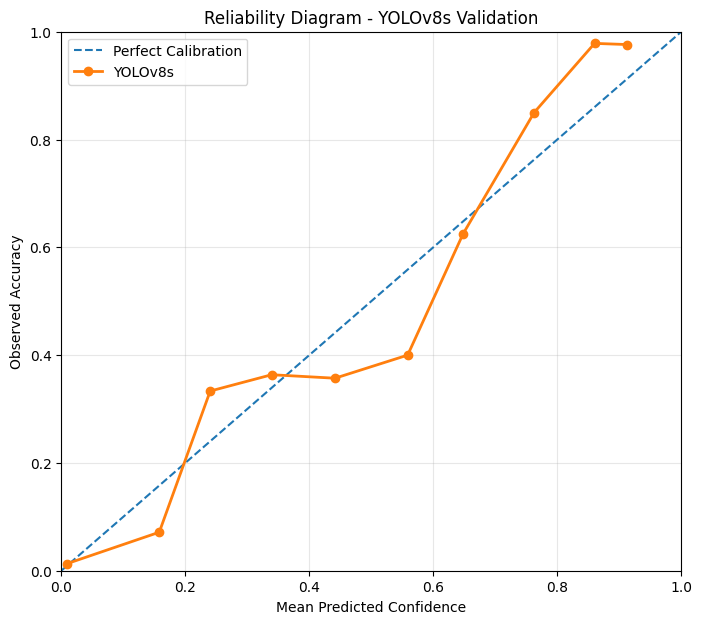

In [ ]:
plt.figure(figsize=(8, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    bin_df["mean_confidence"],
    bin_df["accuracy"],
    marker="o",
    linewidth=2,
    label="YOLOv8s"
)

plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Observed Accuracy")

plt.title("Reliability Diagram - YOLOv8s Validation")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    CAL_DIR / "Reliability_Diagram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss

def calibration_metrics(data, bins=10):

    p = data["confidence"].values
    y = data["correct"].values

    eps = 1e-7
    p_safe = np.clip(p, eps, 1-eps)

    ece, bin_data = calculate_ece(
        p, y, bins=bins
    )

    brier = np.mean((p-y)**2)

    nll = log_loss(
        y, p_safe, labels=[0, 1]
    )

    return {
        "N": len(data),
        "ECE": ece,
        "Brier": brier,
        "NLL": nll
    }

thresholds = [0.001, 0.05, 0.10, 0.25, 0.50]

threshold_results = []

for threshold in thresholds:

    subset = cal_df[
        cal_df["confidence"] >= threshold
    ]

    metrics = calibration_metrics(subset)

    metrics["Confidence_Threshold"] = threshold

    threshold_results.append(metrics)

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

threshold_df.to_csv(
    CAL_DIR / "Calibration_Threshold_Analysis.csv",
    index=False
)

,N,ECE,Brier,NLL,Confidence_Threshold
0,1019,0.058786,0.043253,0.170679,0.001
1,566,0.105634,0.072653,0.278498,0.050
2,551,0.105071,0.069876,0.270423,0.100
3,531,0.105452,0.068053,0.265872,0.250
4,503,0.108144,0.059117,0.244502,0.500


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from scipy.special import logit
import numpy as np
import pandas as pd

# Gunakan data prediksi validasi sebelumnya
df = cal_df.copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

fit_idx, eval_idx = next(
    splitter.split(
        df,
        groups=df["image"]
    )
)

fit_df = df.iloc[fit_idx].copy()
eval_df = df.iloc[eval_idx].copy()

print("Calibration-fit:", len(fit_df))
print("Calibration-evaluation:", len(eval_df))
print("Gambar fit:", fit_df["image"].nunique())
print("Gambar evaluation:", eval_df["image"].nunique())

Calibration-fit: 516
Calibration-evaluation: 503
Gambar fit: 251
Gambar evaluation: 251


In [ ]:
EPS = 1e-7

def make_logit_feature(conf):
    conf = np.clip(
        np.asarray(conf),
        EPS,
        1-EPS
    )
    return logit(conf).reshape(-1, 1)

X_fit = make_logit_feature(
    fit_df["confidence"]
)

y_fit = fit_df["correct"].values

platt_model = LogisticRegression(
    solver="lbfgs",
    random_state=42
)

platt_model.fit(X_fit, y_fit)

# Terapkan pada data evaluation
X_eval = make_logit_feature(
    eval_df["confidence"]
)

eval_df["calibrated_confidence"] = (
    platt_model.predict_proba(X_eval)[:, 1]
)

print("Platt Scaling selesai.")
print("Koefisien:", platt_model.coef_)
print("Intercept:", platt_model.intercept_)

Platt Scaling selesai.
Koefisien: [[     1.2153]]
Intercept: [    0.69183]


In [ ]:
def evaluate_calibration(y, probabilities, bins=10):

    y = np.asarray(y)
    p = np.clip(
        np.asarray(probabilities),
        EPS,
        1-EPS
    )

    ece, bin_df = calculate_ece(
        p,
        y,
        bins=bins
    )

    brier = np.mean((p-y)**2)

    nll = -np.mean(
        y*np.log(p) +
        (1-y)*np.log(1-p)
    )

    return {
        "N": len(y),
        "ECE": ece,
        "Brier": brier,
        "NLL": nll
    }, bin_df


y_eval = eval_df["correct"].values

before_metrics, before_bins = evaluate_calibration(
    y_eval,
    eval_df["confidence"]
)

after_metrics, after_bins = evaluate_calibration(
    y_eval,
    eval_df["calibrated_confidence"]
)

comparison = pd.DataFrame([
    {
        "Model": "YOLOv8s Baseline",
        **before_metrics
    },
    {
        "Model": "YOLOv8s + Platt Scaling",
        **after_metrics
    }
])

display(comparison)

comparison.to_csv(
    CAL_DIR / "Platt_Scaling_Comparison.csv",
    index=False
)

eval_df.to_csv(
    CAL_DIR / "Platt_Scaling_Evaluation.csv",
    index=False
)

,Model,N,ECE,Brier,NLL
0,YOLOv8s Baseline,503,0.073885,0.040834,0.158103
1,YOLOv8s + Platt Scaling,503,0.042860,0.039419,0.133842


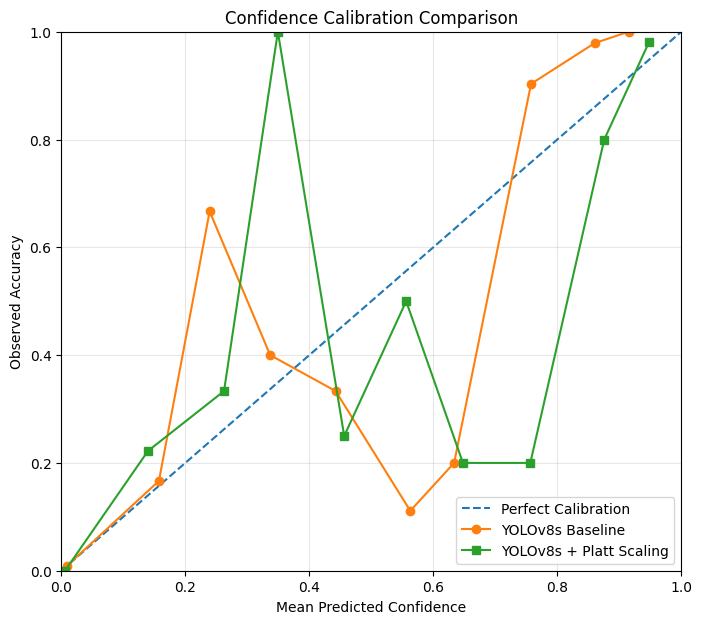

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect Calibration"
)

plt.plot(
    before_bins["mean_confidence"],
    before_bins["accuracy"],
    marker="o",
    label="YOLOv8s Baseline"
)

plt.plot(
    after_bins["mean_confidence"],
    after_bins["accuracy"],
    marker="s",
    label="YOLOv8s + Platt Scaling"
)

plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Observed Accuracy")

plt.title(
    "Confidence Calibration Comparison"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    CAL_DIR / "Platt_Scaling_Reliability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
improvement = pd.DataFrame({
    "Metric": ["ECE", "Brier", "NLL"],
    "Before": [
        before_metrics["ECE"],
        before_metrics["Brier"],
        before_metrics["NLL"]
    ],
    "After": [
        after_metrics["ECE"],
        after_metrics["Brier"],
        after_metrics["NLL"]
    ]
})

improvement["Improvement (%)"] = (
    (improvement["Before"] - improvement["After"])
    / improvement["Before"] * 100
)

display(improvement)

improvement.to_csv(
    CAL_DIR / "Platt_Scaling_Improvement.csv",
    index=False
)

,Metric,Before,After,Improvement (%)
0,ECE,0.073885,0.042860,41.990543
1,Brier,0.040834,0.039419,3.463887
2,NLL,0.158103,0.133842,15.345033


In [ ]:
from sklearn.linear_model import LogisticRegression
from scipy.special import logit
import numpy as np
import pandas as pd

classwise_results = []

for cls in sorted(eval_df["class_name"].unique()):

    fit_class = fit_df[
        fit_df["class_name"] == cls
    ].copy()

    eval_class = eval_df[
        eval_df["class_name"] == cls
    ].copy()

    if (
        len(fit_class) < 30
        or fit_class["correct"].nunique() < 2
    ):
        print("Data belum mencukupi:", cls)
        continue

    calibrator = LogisticRegression(
        solver="lbfgs",
        random_state=42
    )

    X_fit_class = logit(
        np.clip(
            fit_class["confidence"].values,
            1e-7,
            1-1e-7
        )
    ).reshape(-1, 1)

    calibrator.fit(
        X_fit_class,
        fit_class["correct"].values
    )

    X_eval_class = logit(
        np.clip(
            eval_class["confidence"].values,
            1e-7,
            1-1e-7
        )
    ).reshape(-1, 1)

    calibrated = calibrator.predict_proba(
        X_eval_class
    )[:, 1]

    metrics, _ = evaluate_calibration(
        eval_class["correct"].values,
        calibrated
    )

    classwise_results.append({
        "Class": cls,
        "N_Fit": len(fit_class),
        "N_Evaluation": len(eval_class),
        "ECE": metrics["ECE"],
        "Brier": metrics["Brier"],
        "NLL": metrics["NLL"],
        "Coefficient": calibrator.coef_[0, 0],
        "Intercept": calibrator.intercept_[0]
    })

classwise_df = pd.DataFrame(classwise_results)

display(classwise_df)

classwise_df.to_csv(
    CAL_DIR / "Classwise_Platt_Scaling.csv",
    index=False
)

,Class,N_Fit,N_Evaluation,ECE,Brier,NLL,Coefficient,Intercept
0,Glioma,203,213,0.034135,0.036569,0.119752,1.441655,0.697439
1,Meningioma,90,84,0.060307,0.050300,0.183144,0.781551,1.342168
2,No Tumor,131,119,0.061615,0.038081,0.134633,1.510045,-0.157266
3,Pituitary,92,87,0.055675,0.035691,0.127674,1.381508,0.549023


In [ ]:
from scipy.special import logit
import numpy as np

EPS = 1e-7

def transform_confidence(values):
    values = np.asarray(values, dtype=float)

    values = np.clip(
        values,
        EPS,
        1-EPS
    )

    return logit(values).reshape(-1, 1)

In [ ]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# Global Platt Scaling
global_model = LogisticRegression(
    solver="lbfgs",
    random_state=42
)

global_model.fit(
    transform_confidence(fit_df["confidence"]),
    fit_df["correct"].values
)

comparison_df = eval_df.copy()

comparison_df["global_calibrated"] = (
    global_model.predict_proba(
        transform_confidence(
            comparison_df["confidence"]
        )
    )[:, 1]
)

# Class-wise Platt Scaling
comparison_df["classwise_calibrated"] = np.nan

for cls in sorted(fit_df["class_name"].unique()):

    fit_class = fit_df[
        fit_df["class_name"] == cls
    ]

    eval_mask = (
        comparison_df["class_name"] == cls
    )

    eval_class = comparison_df.loc[eval_mask]

    if fit_class["correct"].nunique() < 2:
        continue

    model_class = LogisticRegression(
        solver="lbfgs",
        random_state=42
    )

    model_class.fit(
        transform_confidence(
            fit_class["confidence"]
        ),
        fit_class["correct"].values
    )

    comparison_df.loc[
        eval_mask,
        "classwise_calibrated"
    ] = model_class.predict_proba(
        transform_confidence(
            eval_class["confidence"]
        )
    )[:, 1]

print("Global dan Class-wise calibration selesai.")

Global dan Class-wise calibration selesai.


In [ ]:
y = comparison_df["correct"].values

global_metrics, _ = evaluate_calibration(
    y,
    comparison_df["global_calibrated"].values
)

classwise_metrics, _ = evaluate_calibration(
    y,
    comparison_df["classwise_calibrated"].values
)

final_comparison = pd.DataFrame([
    {
        "Method": "Global Platt Scaling",
        **global_metrics
    },
    {
        "Method": "Class-wise Platt Scaling",
        **classwise_metrics
    }
])

display(final_comparison)

,Method,N,ECE,Brier,NLL
0,Global Platt Scaling,503,0.042860,0.039419,0.133842
1,Class-wise Platt Scaling,503,0.028614,0.039068,0.135229


In [ ]:
final_comparison.to_csv(
    CAL_DIR / "Global_vs_Classwise_Comparison.csv",
    index=False
)

In [ ]:
import numpy as np
import pandas as pd

def calculate_metrics_simple(y, p, bins=10):

    y = np.asarray(y)
    p = np.clip(np.asarray(p), 1e-7, 1-1e-7)

    ece, _ = calculate_ece(p, y, bins)

    brier = np.mean((p-y)**2)

    nll = -np.mean(
        y*np.log(p) + (1-y)*np.log(1-p)
    )

    return np.array([ece, brier, nll])


# Bootstrap berdasarkan gambar
rng = np.random.default_rng(42)

groups = comparison_df["image"].unique()

bootstrap_results = []

for i in range(1000):

    sampled_groups = rng.choice(
        groups,
        size=len(groups),
        replace=True
    )

    samples = pd.concat([
        comparison_df[
            comparison_df["image"] == g
        ]
        for g in sampled_groups
    ], ignore_index=True)

    y = samples["correct"].values

    global_values = calculate_metrics_simple(
        y,
        samples["global_calibrated"].values
    )

    classwise_values = calculate_metrics_simple(
        y,
        samples["classwise_calibrated"].values
    )

    # Positif berarti class-wise lebih baik
    difference = global_values - classwise_values

    bootstrap_results.append(difference)


bootstrap_results = np.array(bootstrap_results)

metric_names = ["ECE", "Brier", "NLL"]

bootstrap_summary = []

for i, metric in enumerate(metric_names):

    lower = np.percentile(
        bootstrap_results[:, i], 2.5
    )

    upper = np.percentile(
        bootstrap_results[:, i], 97.5
    )

    bootstrap_summary.append({
        "Metric": metric,
        "Difference_Global_minus_Classwise":
            np.mean(bootstrap_results[:, i]),
        "CI_95_Lower": lower,
        "CI_95_Upper": upper
    })

bootstrap_df = pd.DataFrame(bootstrap_summary)

display(bootstrap_df)

bootstrap_df.to_csv(
    CAL_DIR / "Bootstrap_Calibration_Comparison.csv",
    index=False
)

,Metric,Difference_Global_minus_Classwise,CI_95_Lower,CI_95_Upper
0,ECE,0.013741,0.002712,0.026480
1,Brier,0.000442,-0.002778,0.003603
2,NLL,-0.001199,-0.010855,0.007900


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from scipy.special import logit

EPS = 1e-7

def transform_confidence(values):
    values = np.asarray(values, dtype=float)
    values = np.clip(values, EPS, 1-EPS)
    return logit(values).reshape(-1, 1)

print("Jumlah prediksi:", len(cal_df))
print("Jumlah gambar:", cal_df["image"].nunique())
print("Jumlah kelas:", cal_df["class_name"].nunique())

Jumlah prediksi: 1019
Jumlah gambar: 502
Jumlah kelas: 4


In [ ]:
def get_metrics(y, p):

    y = np.asarray(y)
    p = np.clip(np.asarray(p), EPS, 1-EPS)

    ece, _ = calculate_ece(p, y, bins=10)

    brier = np.mean((p-y)**2)

    nll = -np.mean(
        y*np.log(p) +
        (1-y)*np.log(1-p)
    )

    return {
        "ECE": ece,
        "Brier": brier,
        "NLL": nll
    }

In [ ]:
from sklearn.model_selection import GroupKFold

REPETITIONS = 3
N_SPLITS = 5

cv_results = []

for repetition in range(REPETITIONS):

    # Urutan gambar diacak, tetapi semua prediksi
    # dari satu gambar tetap berada dalam kelompok sama.
    rng = np.random.default_rng(42 + repetition)

    unique_images = cal_df["image"].unique()
    shuffled_images = rng.permutation(unique_images)

    shuffled_df = cal_df.set_index("image").loc[
        np.repeat(shuffled_images, 1)
    ].reset_index()

    groups = shuffled_df["image"].values

    splitter = GroupKFold(n_splits=N_SPLITS)

    for fold, (train_idx, test_idx) in enumerate(
        splitter.split(shuffled_df, groups=groups)
    ):

        fit = shuffled_df.iloc[train_idx].copy()
        evaluation = shuffled_df.iloc[test_idx].copy()

        y_eval = evaluation["correct"].values

        # Global Platt
        global_model = LogisticRegression(
            solver="lbfgs",
            random_state=42
        )

        global_model.fit(
            transform_confidence(fit["confidence"]),
            fit["correct"].values
        )

        global_pred = global_model.predict_proba(
            transform_confidence(evaluation["confidence"])
        )[:, 1]

        global_metrics = get_metrics(
            y_eval,
            global_pred
        )

        cv_results.append({
            "Repetition": repetition + 1,
            "Fold": fold + 1,
            "Method": "Global Platt",
            "N": len(evaluation),
            **global_metrics
        })

        # Class-wise Platt
        classwise_pred = np.zeros(len(evaluation))

        for cls in fit["class_name"].unique():

            fit_class = fit[
                fit["class_name"] == cls
            ]

            eval_mask = (
                evaluation["class_name"] == cls
            )

            eval_class = evaluation.loc[eval_mask]

            if (
                fit_class["correct"].nunique() < 2
                or len(fit_class) < 20
            ):
                raise ValueError(
                    f"Data tidak mencukupi untuk kelas {cls}"
                )

            class_model = LogisticRegression(
                solver="lbfgs",
                random_state=42
            )

            class_model.fit(
                transform_confidence(
                    fit_class["confidence"]
                ),
                fit_class["correct"].values
            )

            classwise_pred[np.where(eval_mask)[0]] = (
                class_model.predict_proba(
                    transform_confidence(
                        eval_class["confidence"]
                    )
                )[:, 1]
            )

        classwise_metrics = get_metrics(
            y_eval,
            classwise_pred
        )

        cv_results.append({
            "Repetition": repetition + 1,
            "Fold": fold + 1,
            "Method": "Class-wise Platt",
            "N": len(evaluation),
            **classwise_metrics
        })

cv_df = pd.DataFrame(cv_results)

display(cv_df)

,Repetition,Fold,Method,N,ECE,Brier,NLL
0,1,1,Global Platt,204,0.041758,0.044597,0.163320
1,1,1,Class-wise Platt,204,0.037405,0.042478,0.153279
2,1,2,Global Platt,204,0.047191,0.043017,0.146867
3,1,2,Class-wise Platt,204,0.041389,0.047131,0.155341
4,1,3,Global Platt,204,0.038266,0.029261,0.108625
5,1,3,Class-wise Platt,204,0.027713,0.028914,0.108788
6,1,4,Global Platt,204,0.039530,0.038982,0.134582
7,1,4,Class-wise Platt,204,0.035801,0.035336,0.131860
8,1,5,Global Platt,203,0.045397,0.050851,0.225271
9,1,5,Class-wise Platt,203,0.054640,0.051158,0.201051


In [ ]:
cv_summary = (
    cv_df.groupby("Method")
    .agg(
        ECE_Mean=("ECE", "mean"),
        ECE_STD=("ECE", "std"),
        Brier_Mean=("Brier", "mean"),
        Brier_STD=("Brier", "std"),
        NLL_Mean=("NLL", "mean"),
        NLL_STD=("NLL", "std")
    )
    .reset_index()
)

display(cv_summary)

cv_df.to_csv(
    CAL_DIR / "Repeated_Grouped_CV_Raw.csv",
    index=False
)

cv_summary.to_csv(
    CAL_DIR / "Repeated_Grouped_CV_Summary.csv",
    index=False
)

,Method,ECE_Mean,ECE_STD,Brier_Mean,Brier_STD,NLL_Mean,NLL_STD
0,Class-wise Platt,0.039390,0.009139,0.041003,0.008295,0.150064,0.031644
1,Global Platt,0.042428,0.003515,0.041341,0.007397,0.155733,0.040457


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

print("StratifiedGroupKFold tersedia.")

StratifiedGroupKFold tersedia.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

cv_results_new = []

for repetition, seed in enumerate([42, 123, 2026], start=1):

    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    X = cal_df["confidence"].values
    y = cal_df["correct"].values
    groups = cal_df["image"].values
    strata = cal_df["class_name"].astype(str) + "_" + cal_df["correct"].astype(str)

    for fold, (train_idx, eval_idx) in enumerate(
        splitter.split(X, strata, groups),
        start=1
    ):

        fit = cal_df.iloc[train_idx].copy()
        evaluation = cal_df.iloc[eval_idx].copy()

        y_eval = evaluation["correct"].values

        # Global Platt
        global_model = LogisticRegression(
            solver="lbfgs",
            random_state=42
        )

        global_model.fit(
            transform_confidence(fit["confidence"]),
            fit["correct"].values
        )

        global_pred = global_model.predict_proba(
            transform_confidence(evaluation["confidence"])
        )[:, 1]

        global_metrics = get_metrics(y_eval, global_pred)

        cv_results_new.append({
            "Repetition": repetition,
            "Seed": seed,
            "Fold": fold,
            "Method": "Global Platt",
            "N": len(evaluation),
            **global_metrics
        })

        # Class-wise Platt
        classwise_pred = np.zeros(len(evaluation))

        for cls in sorted(fit["class_name"].unique()):

            fit_class = fit[fit["class_name"] == cls]

            mask = evaluation["class_name"] == cls
            eval_class = evaluation.loc[mask]

            if (
                fit_class["correct"].nunique() < 2
                or len(fit_class) < 20
            ):
                raise ValueError(
                    f"Data tidak cukup untuk kelas {cls}"
                )

            class_model = LogisticRegression(
                solver="lbfgs",
                random_state=42
            )

            class_model.fit(
                transform_confidence(fit_class["confidence"]),
                fit_class["correct"].values
            )

            classwise_pred[np.where(mask)[0]] = (
                class_model.predict_proba(
                    transform_confidence(eval_class["confidence"])
                )[:, 1]
            )

        classwise_metrics = get_metrics(
            y_eval,
            classwise_pred
        )

        cv_results_new.append({
            "Repetition": repetition,
            "Seed": seed,
            "Fold": fold,
            "Method": "Class-wise Platt",
            "N": len(evaluation),
            **classwise_metrics
        })

cv_new_df = pd.DataFrame(cv_results_new)

display(cv_new_df)

,Repetition,Seed,Fold,Method,N,ECE,Brier,NLL
0,1,42,1,Global Platt,191,0.040735,0.056872,0.189826
1,1,42,1,Class-wise Platt,191,0.041305,0.059585,0.213551
2,1,42,2,Global Platt,196,0.037518,0.043432,0.154613
3,1,42,2,Class-wise Platt,196,0.018174,0.041341,0.150259
4,1,42,3,Global Platt,204,0.039127,0.038415,0.147827
5,1,42,3,Class-wise Platt,204,0.040451,0.040649,0.144613
6,1,42,4,Global Platt,213,0.024998,0.042261,0.165095
7,1,42,4,Class-wise Platt,213,0.028251,0.043359,0.154993
8,1,42,5,Global Platt,215,0.046514,0.023266,0.090108
9,1,42,5,Class-wise Platt,215,0.049528,0.021253,0.084498


In [ ]:
cv_new_summary = (
    cv_new_df.groupby("Method")
    .agg(
        ECE_Mean=("ECE", "mean"),
        ECE_STD=("ECE", "std"),
        Brier_Mean=("Brier", "mean"),
        Brier_STD=("Brier", "std"),
        NLL_Mean=("NLL", "mean"),
        NLL_STD=("NLL", "std")
    )
    .reset_index()
)

display(cv_new_summary)

cv_new_df.to_csv(
    CAL_DIR / "Repeated_Stratified_Grouped_CV_Raw.csv",
    index=False
)

cv_new_summary.to_csv(
    CAL_DIR / "Repeated_Stratified_Grouped_CV_Summary.csv",
    index=False
)

,Method,ECE_Mean,ECE_STD,Brier_Mean,Brier_STD,NLL_Mean,NLL_STD
0,Class-wise Platt,0.037552,0.010627,0.041250,0.013672,0.150576,0.043544
1,Global Platt,0.039896,0.007200,0.040741,0.012380,0.150553,0.041115


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from scipy.special import logit, expit
from sklearn.metrics import brier_score_loss, log_loss

# Salin data
df = cal_df.copy()

required = ['confidence', 'correct', 'class_name', 'image']
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Kolom tidak ditemukan: {missing}")

df = df.dropna(subset=required).copy()

df['confidence'] = df['confidence'].astype(float).clip(1e-6, 1-1e-6)
df['correct'] = df['correct'].astype(int)
df['class_name'] = df['class_name'].astype(str)
df['image'] = df['image'].astype(str)

print("Jumlah deteksi:", len(df))
print("Jumlah gambar:", df['image'].nunique())
print("\nDistribusi kelas:")
print(df['class_name'].value_counts())

print("\nDistribusi label:")
print(df['correct'].value_counts())

Jumlah deteksi: 1019
Jumlah gambar: 502

Distribusi kelas:
class_name
Glioma        416
No Tumor      250
Pituitary     179
Meningioma    174
Name: count, dtype: int64

Distribusi label:
correct
0    530
1    489
Name: count, dtype: int64


In [ ]:
def calculate_ece(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (probabilities >= bins[i]) & (probabilities <= bins[i+1])
        else:
            mask = (probabilities >= bins[i]) & (probabilities < bins[i+1])

        if np.any(mask):
            accuracy = np.mean(y_true[mask])
            confidence = np.mean(probabilities[mask])

            ece += np.sum(mask) / len(y_true) * abs(
                accuracy - confidence
            )

    return ece


def evaluate_calibration(y_true, probabilities):
    probabilities = np.clip(probabilities, 1e-7, 1-1e-7)

    return {
        'N': len(y_true),
        'ECE': calculate_ece(y_true, probabilities),
        'Brier': brier_score_loss(y_true, probabilities),
        'NLL': log_loss(y_true, probabilities, labels=[0, 1])
    }


def fit_platt(x, y):
    x_logit = logit(np.clip(x, 1e-6, 1-1e-6)).reshape(-1, 1)

    if len(np.unique(y)) < 2:
        raise ValueError("Data training hanya memiliki satu label.")

    model = LogisticRegression(
        C=1.0,
        solver='lbfgs',
        max_iter=1000
    )

    model.fit(x_logit, y)
    return model


def predict_platt(model, x):
    x_logit = logit(np.clip(x, 1e-6, 1-1e-6)).reshape(-1, 1)
    return model.predict_proba(x_logit)[:, 1]

In [ ]:
seeds = [42, 123, 2026]
n_splits = 5

oof_results = []

for repetition, seed in enumerate(seeds, start=1):

    strata = (
        df['class_name'].astype(str)
        + "_"
        + df['correct'].astype(str)
    )

    sgkf = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    for fold, (train_idx, test_idx) in enumerate(
        sgkf.split(df, strata, groups=df['image']),
        start=1
    ):

        train = df.iloc[train_idx].copy()
        test = df.iloc[test_idx].copy()

        # Pastikan tidak ada kebocoran gambar
        assert set(train['image']).isdisjoint(set(test['image']))

        x_train = train['confidence'].values
        y_train = train['correct'].values
        x_test = test['confidence'].values
        y_test = test['correct'].values

        # Global Platt
        global_model = fit_platt(x_train, y_train)
        global_pred = predict_platt(global_model, x_test)

        # Class-wise Platt
        classwise_pred = np.zeros(len(test))

        for class_name in test['class_name'].unique():

            train_mask = train['class_name'] == class_name
            test_mask = test['class_name'] == class_name

            train_class = train.loc[train_mask]
            test_class = test.loc[test_mask]

            if (
                len(train_class) >= 10
                and train_class['correct'].nunique() == 2
            ):
                class_model = fit_platt(
                    train_class['confidence'].values,
                    train_class['correct'].values
                )

                classwise_pred[test_mask.values] = predict_platt(
                    class_model,
                    test_class['confidence'].values
                )

            else:
                # Fallback global jika data kelas tidak mencukupi
                classwise_pred[test_mask.values] = predict_platt(
                    global_model,
                    test_class['confidence'].values
                )

        # Simpan prediksi berpasangan
        for i, (_, row) in enumerate(test.iterrows()):

            oof_results.append({
                'repetition': repetition,
                'seed': seed,
                'fold': fold,
                'image': row['image'],
                'class_name': row['class_name'],
                'correct': row['correct'],
                'confidence': row['confidence'],
                'global_pred': global_pred[i],
                'classwise_pred': classwise_pred[i]
            })

    print(f"Repetition {repetition} selesai.")

oof_df = pd.DataFrame(oof_results)

print("\nTotal prediksi OOF:", len(oof_df))
print("Jumlah gambar:", oof_df['image'].nunique())

Repetition 1 selesai.
Repetition 2 selesai.
Repetition 3 selesai.

Total prediksi OOF: 3057
Jumlah gambar: 502


In [ ]:
class_results = []

for class_name, group in oof_df.groupby('class_name'):

    y = group['correct'].values

    for method, column in [
        ('Global Platt', 'global_pred'),
        ('Class-wise Platt', 'classwise_pred')
    ]:

        metrics = evaluate_calibration(
            y,
            group[column].values
        )

        class_results.append({
            'Class': class_name,
            'Method': method,
            **metrics
        })

class_results_df = pd.DataFrame(class_results)

display(
    class_results_df.round(5)
)

,Class,Method,N,ECE,Brier,NLL
0,Glioma,Global Platt,1248,0.02527,0.03223,0.11392
1,Glioma,Class-wise Platt,1248,0.02045,0.03289,0.11548
2,Meningioma,Global Platt,522,0.06088,0.05655,0.24274
3,Meningioma,Class-wise Platt,522,0.03760,0.06384,0.24039
4,No Tumor,Global Platt,750,0.02597,0.04239,0.14394
5,No Tumor,Class-wise Platt,750,0.02539,0.04139,0.14837
6,Pituitary,Global Platt,537,0.04187,0.04061,0.14778
7,Pituitary,Class-wise Platt,537,0.02645,0.03619,0.13915


In [ ]:
def paired_image_bootstrap(data, n_bootstrap=2000, seed=42):

    rng = np.random.default_rng(seed)

    image_ids = data['image'].unique()
    differences = []

    for _ in range(n_bootstrap):

        sampled_images = rng.choice(
            image_ids,
            size=len(image_ids),
            replace=True
        )

        # Pertahankan semua deteksi dari gambar terpilih.
        # Duplikasi gambar saat bootstrap dipertahankan.
        samples = pd.concat(
            [data[data['image'] == img] for img in sampled_images],
            ignore_index=True
        )

        y = samples['correct'].values

        global_metrics = evaluate_calibration(
            y,
            samples['global_pred'].values
        )

        classwise_metrics = evaluate_calibration(
            y,
            samples['classwise_pred'].values
        )

        differences.append({
            'ECE': global_metrics['ECE'] - classwise_metrics['ECE'],
            'Brier': global_metrics['Brier'] - classwise_metrics['Brier'],
            'NLL': global_metrics['NLL'] - classwise_metrics['NLL']
        })

    boot_df = pd.DataFrame(differences)

    summary = []

    for metric in ['ECE', 'Brier', 'NLL']:

        values = boot_df[metric].values

        summary.append({
            'Metric': metric,
            'Difference_Mean': np.mean(values),
            'CI_Lower': np.percentile(values, 2.5),
            'CI_Upper': np.percentile(values, 97.5)
        })

    return pd.DataFrame(summary), boot_df


bootstrap_summary, bootstrap_raw = paired_image_bootstrap(
    oof_df,
    n_bootstrap=2000,
    seed=42
)

display(bootstrap_summary.round(6))

,Metric,Difference_Mean,CI_Lower,CI_Upper
0,ECE,0.006325,-0.002943,0.016659
1,Brier,-0.000479,-0.002785,0.001625
2,NLL,0.000290,-0.009006,0.010641


In [ ]:
def paired_image_bootstrap(data, n_bootstrap=2000, seed=42):

    rng = np.random.default_rng(seed)

    image_ids = data['image'].unique()
    differences = []

    for _ in range(n_bootstrap):

        sampled_images = rng.choice(
            image_ids,
            size=len(image_ids),
            replace=True
        )

        # Pertahankan semua deteksi dari gambar terpilih.
        # Duplikasi gambar saat bootstrap dipertahankan.
        samples = pd.concat(
            [data[data['image'] == img] for img in sampled_images],
            ignore_index=True
        )

        y = samples['correct'].values

        global_metrics = evaluate_calibration(
            y,
            samples['global_pred'].values
        )

        classwise_metrics = evaluate_calibration(
            y,
            samples['classwise_pred'].values
        )

        differences.append({
            'ECE': global_metrics['ECE'] - classwise_metrics['ECE'],
            'Brier': global_metrics['Brier'] - classwise_metrics['Brier'],
            'NLL': global_metrics['NLL'] - classwise_metrics['NLL']
        })

    boot_df = pd.DataFrame(differences)

    summary = []

    for metric in ['ECE', 'Brier', 'NLL']:

        values = boot_df[metric].values

        summary.append({
            'Metric': metric,
            'Difference_Mean': np.mean(values),
            'CI_Lower': np.percentile(values, 2.5),
            'CI_Upper': np.percentile(values, 97.5)
        })

    return pd.DataFrame(summary), boot_df


bootstrap_summary, bootstrap_raw = paired_image_bootstrap(
    oof_df,
    n_bootstrap=2000,
    seed=42
)

display(bootstrap_summary.round(6))

,Metric,Difference_Mean,CI_Lower,CI_Upper
0,ECE,0.006325,-0.002943,0.016659
1,Brier,-0.000479,-0.002785,0.001625
2,NLL,0.000290,-0.009006,0.010641


In [ ]:
output_path = '/content/drive/MyDrive/CLEAR-MRI/'

oof_df.to_csv(
    output_path + 'OOF_Calibration_Predictions.csv',
    index=False
)

class_results_df.to_csv(
    output_path + 'Calibration_Per_Class.csv',
    index=False
)

bootstrap_summary.to_csv(
    output_path + 'Paired_Bootstrap_Summary.csv',
    index=False
)

print("Seluruh hasil berhasil disimpan.")

Seluruh hasil berhasil disimpan.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_columns = [
    'image',
    'class_name',
    'correct',
    'confidence',
    'global_pred',
    'classwise_pred'
]

missing = [c for c in required_columns if c not in oof_df.columns]

if missing:
    raise ValueError(f"Kolom tidak ditemukan: {missing}")

data = oof_df.copy()

# Gabungkan prediksi berulang pada tiga repetition.
# Confidence dan label asli merupakan identitas deteksi.
group_columns = [
    'image',
    'class_name',
    'correct',
    'confidence'
]

reliability_df = (
    data.groupby(group_columns, as_index=False)
    .agg(
        global_pred=('global_pred', 'mean'),
        classwise_pred=('classwise_pred', 'mean'),
        repetitions=('seed', 'nunique')
    )
)

print("Jumlah deteksi setelah agregasi:", len(reliability_df))
print("Jumlah gambar:", reliability_df['image'].nunique())
print("\nDistribusi kelas:")
print(reliability_df['class_name'].value_counts())

Jumlah deteksi setelah agregasi: 1019
Jumlah gambar: 502

Distribusi kelas:
class_name
Glioma        416
No Tumor      250
Pituitary     179
Meningioma    174
Name: count, dtype: int64


In [ ]:
def reliability_bins(y_true, probabilities, n_bins=10):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    results = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i+1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i+1])
            )

        if np.sum(mask) == 0:
            continue

        results.append({
            'bin': i + 1,
            'mean_confidence': probabilities[mask].mean(),
            'accuracy': y_true[mask].mean(),
            'count': int(mask.sum())
        })

    return pd.DataFrame(results)

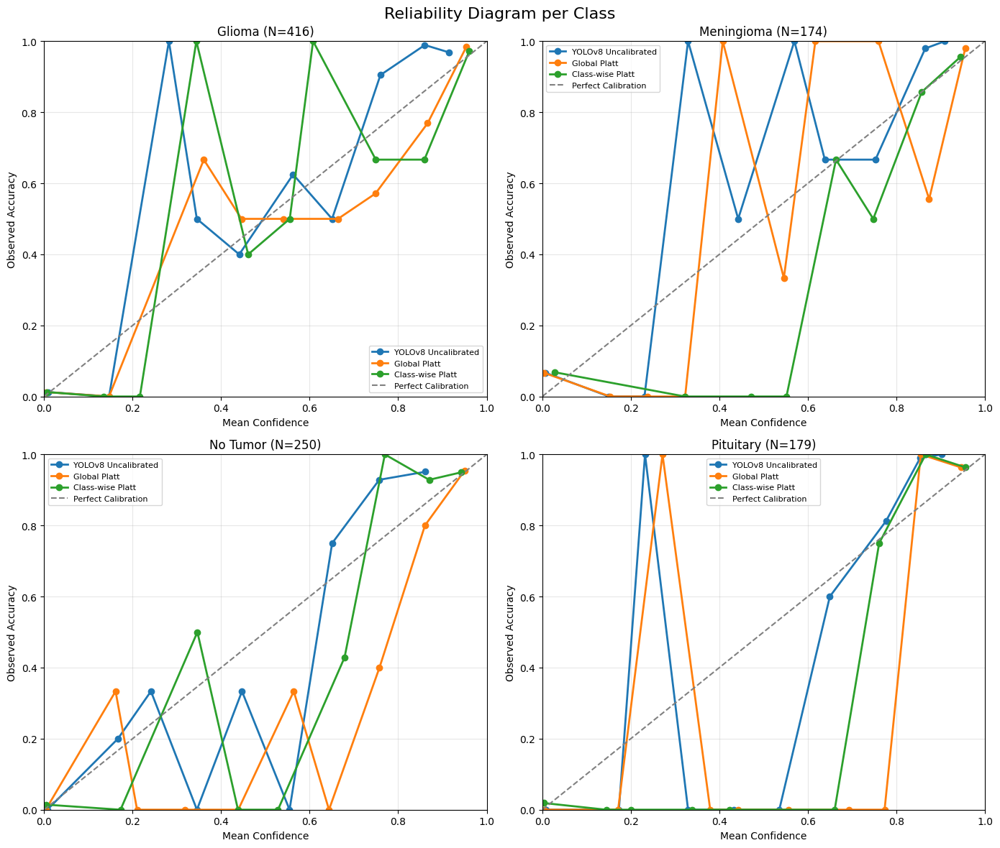

In [ ]:
classes = [
    'Glioma',
    'Meningioma',
    'No Tumor',
    'Pituitary'
]

methods = {
    'YOLOv8 Uncalibrated': 'confidence',
    'Global Platt': 'global_pred',
    'Class-wise Platt': 'classwise_pred'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes = axes.flatten()

for ax, class_name in zip(axes, classes):

    subset = reliability_df[
        reliability_df['class_name'] == class_name
    ]

    y_true = subset['correct'].values

    for method_name, column in methods.items():

        probabilities = subset[column].values

        bins = reliability_bins(
            y_true,
            probabilities,
            n_bins=10
        )

        ax.plot(
            bins['mean_confidence'],
            bins['accuracy'],
            marker='o',
            linewidth=2,
            label=method_name
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray',
        label='Perfect Calibration'
    )

    ax.set_title(
        f'{class_name} (N={len(subset)})'
    )

    ax.set_xlabel('Mean Confidence')
    ax.set_ylabel('Observed Accuracy')

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(
    'Reliability Diagram per Class',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
results = []

for class_name in classes:

    subset = reliability_df[
        reliability_df['class_name'] == class_name
    ]

    y_true = subset['correct'].values

    for method_name, column in methods.items():

        probabilities = subset[column].values

        bins = reliability_bins(
            y_true,
            probabilities,
            n_bins=10
        )

        ece = np.sum(
            bins['count'] / len(subset) *
            np.abs(
                bins['accuracy'] -
                bins['mean_confidence']
            )
        )

        results.append({
            'Class': class_name,
            'Method': method_name,
            'N': len(subset),
            'ECE': ece
        })

reliability_results = pd.DataFrame(results)

display(
    reliability_results.round(5)
)

,Class,Method,N,ECE
0,Glioma,YOLOv8 Uncalibrated,416,0.05139
1,Glioma,Global Platt,416,0.02665
2,Glioma,Class-wise Platt,416,0.01957
3,Meningioma,YOLOv8 Uncalibrated,174,0.10257
4,Meningioma,Global Platt,174,0.06863
5,Meningioma,Class-wise Platt,174,0.03737
6,No Tumor,YOLOv8 Uncalibrated,250,0.06003
7,No Tumor,Global Platt,250,0.02900
8,No Tumor,Class-wise Platt,250,0.03075
9,Pituitary,YOLOv8 Uncalibrated,179,0.10144


In [ ]:
bin_results = []

for class_name in classes:

    subset = reliability_df[
        reliability_df['class_name'] == class_name
    ]

    for method_name, column in methods.items():

        bins = reliability_bins(
            subset['correct'].values,
            subset[column].values,
            n_bins=10
        )

        bins['Class'] = class_name
        bins['Method'] = method_name

        bin_results.append(bins)

bin_distribution = pd.concat(
    bin_results,
    ignore_index=True
)

display(
    bin_distribution[
        ['Class', 'Method', 'bin',
         'count', 'mean_confidence', 'accuracy']
    ].round(5)
)

,Class,Method,bin,count,mean_confidence,accuracy
0,Glioma,YOLOv8 Uncalibrated,1,240,0.00933,0.01250
1,Glioma,YOLOv8 Uncalibrated,2,6,0.14685,0.00000
2,Glioma,YOLOv8 Uncalibrated,3,1,0.28203,1.00000
3,Glioma,YOLOv8 Uncalibrated,4,6,0.34508,0.50000
4,Glioma,YOLOv8 Uncalibrated,5,5,0.44094,0.40000
...,...,...,...,...,...,...
109,Pituitary,Class-wise Platt,5,2,0.42352,0.00000
110,Pituitary,Class-wise Platt,7,1,0.66062,0.00000
111,Pituitary,Class-wise Platt,8,4,0.76107,0.75000
112,Pituitary,Class-wise Platt,9,5,0.86623,1.00000


In [ ]:
output_path = '/content/drive/MyDrive/CLEAR-MRI/'

reliability_df.to_csv(
    output_path + 'Reliability_OOF_Data.csv',
    index=False
)

reliability_results.to_csv(
    output_path + 'Reliability_ECE_Per_Class.csv',
    index=False
)

bin_distribution.to_csv(
    output_path + 'Reliability_Bin_Distribution.csv',
    index=False
)

print("Hasil reliability diagram berhasil disimpan.")

Hasil reliability diagram berhasil disimpan.


In [ ]:
import numpy as np
import pandas as pd

def equal_frequency_bins(y_true, probabilities, n_bins=10):

    temp = pd.DataFrame({
        'confidence': probabilities,
        'correct': y_true
    }).sort_values('confidence').reset_index(drop=True)

    # Membagi data berdasarkan jumlah sampel
    temp['bin'] = pd.qcut(
        np.arange(len(temp)),
        q=min(n_bins, len(temp)),
        labels=False,
        duplicates='drop'
    )

    result = (
        temp.groupby('bin')
        .agg(
            count=('correct', 'size'),
            mean_confidence=('confidence', 'mean'),
            accuracy=('correct', 'mean')
        )
        .reset_index()
    )

    return result


classes = [
    'Glioma',
    'Meningioma',
    'No Tumor',
    'Pituitary'
]

methods = {
    'YOLOv8 Uncalibrated': 'confidence',
    'Global Platt': 'global_pred',
    'Class-wise Platt': 'classwise_pred'
}

adaptive_results = []

for class_name in classes:

    subset = reliability_df[
        reliability_df['class_name'] == class_name
    ]

    for method, column in methods.items():

        bins = equal_frequency_bins(
            subset['correct'].values,
            subset[column].values,
            n_bins=10
        )

        ece = np.sum(
            bins['count'] / len(subset) *
            np.abs(
                bins['accuracy'] -
                bins['mean_confidence']
            )
        )

        adaptive_results.append({
            'Class': class_name,
            'Method': method,
            'N': len(subset),
            'Number_of_Bins': len(bins),
            'Minimum_Bin_Count': bins['count'].min(),
            'Maximum_Bin_Count': bins['count'].max(),
            'ECE_Equal_Frequency': ece
        })

adaptive_results_df = pd.DataFrame(adaptive_results)

display(adaptive_results_df.round(5))

,Class,Method,N,Number_of_Bins,Minimum_Bin_Count,Maximum_Bin_Count,ECE_Equal_Frequency
0,Glioma,YOLOv8 Uncalibrated,416,10,41,42,0.04701
1,Glioma,Global Platt,416,10,41,42,0.02161
2,Glioma,Class-wise Platt,416,10,41,42,0.02169
3,Meningioma,YOLOv8 Uncalibrated,174,10,17,18,0.08413
4,Meningioma,Global Platt,174,10,17,18,0.05517
5,Meningioma,Class-wise Platt,174,10,17,18,0.05345
6,No Tumor,YOLOv8 Uncalibrated,250,10,25,25,0.05650
7,No Tumor,Global Platt,250,10,25,25,0.02760
8,No Tumor,Class-wise Platt,250,10,25,25,0.02381
9,Pituitary,YOLOv8 Uncalibrated,179,10,17,18,0.09339


In [ ]:
adaptive_results_df.to_csv(
    '/content/drive/MyDrive/CLEAR-MRI/'
    'Equal_Frequency_Calibration_Results.csv',
    index=False
)

In [ ]:
import pandas as pd

path = '/content/drive/MyDrive/CLEAR-MRI/OOF_Calibration_Predictions.csv'

oof_df = pd.read_csv(path)

print("Data berhasil dimuat:", oof_df.shape)
display(oof_df.head())

Data berhasil dimuat: (3057, 9)


,repetition,seed,fold,image,class_name,correct,confidence,global_pred,classwise_pred
0,1,42,1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,1,0.775953,0.901239,0.918706
1,1,42,1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0,0.003739,0.000429,0.000361
2,1,42,1,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,Glioma,1,0.905514,0.975789,0.981440
3,1,42,1,Tr-gl_0051_jpg.rf.b04f3a9b9f83a6167a021b5cc846...,Glioma,1,0.895204,0.971491,0.977982
4,1,42,1,Tr-gl_0057_jpg.rf.00db06a404574ba14346d9a5416f...,Glioma,1,0.754020,0.884211,0.903769


In [ ]:
import numpy as np
import pandas as pd

from scipy.special import logit
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import brier_score_loss, log_loss

# Muat data
path = '/content/drive/MyDrive/CLEAR-MRI/OOF_Calibration_Predictions.csv'

oof_df = pd.read_csv(path)

# Gunakan satu observasi per deteksi.
# Jangan menghitung tiga repetition sebagai tiga observasi independen.
group_cols = [
    'image',
    'class_name',
    'correct',
    'confidence'
]

df = (
    oof_df.groupby(group_cols, as_index=False)
    .agg(repetitions=('seed', 'nunique'))
)

df['correct'] = df['correct'].astype(int)
df['confidence'] = df['confidence'].clip(1e-6, 1-1e-6)

print("Jumlah deteksi unik:", len(df))
print("Jumlah gambar:", df['image'].nunique())
print(df['class_name'].value_counts())

Jumlah deteksi unik: 1019
Jumlah gambar: 502
class_name
Glioma        416
No Tumor      250
Pituitary     179
Meningioma    174
Name: count, dtype: int64


In [ ]:
def fit_platt_model(x, y):

    x_logit = logit(
        np.clip(np.asarray(x), 1e-6, 1-1e-6)
    ).reshape(-1, 1)

    y = np.asarray(y)

    if len(np.unique(y)) < 2:
        raise ValueError("Data hanya memiliki satu kelas label.")

    model = LogisticRegression(
        C=1.0,
        solver='lbfgs',
        max_iter=1000
    )

    model.fit(x_logit, y)

    return model


def predict_platt_model(model, x):

    x_logit = logit(
        np.clip(np.asarray(x), 1e-6, 1-1e-6)
    ).reshape(-1, 1)

    return model.predict_proba(x_logit)[:, 1]


def fit_calibrators(train):

    x = train['confidence'].values
    y = train['correct'].values

    global_model = fit_platt_model(x, y)

    class_models = {}

    for class_name in train['class_name'].unique():

        subset = train[
            train['class_name'] == class_name
        ]

        if (
            len(subset) >= 20
            and subset['correct'].nunique() == 2
        ):
            class_models[class_name] = fit_platt_model(
                subset['confidence'].values,
                subset['correct'].values
            )

    return global_model, class_models


def predict_calibrators(global_model, class_models, data):

    global_pred = predict_platt_model(
        global_model,
        data['confidence'].values
    )

    classwise_pred = global_pred.copy()

    for class_name, model in class_models.items():

        mask = (
            data['class_name'].values == class_name
        )

        if np.any(mask):
            classwise_pred[mask] = predict_platt_model(
                model,
                data.loc[mask, 'confidence'].values
            )

    return global_pred, classwise_pred

In [ ]:
def fit_platt_model(x, y):

    x_logit = logit(
        np.clip(np.asarray(x), 1e-6, 1-1e-6)
    ).reshape(-1, 1)

    y = np.asarray(y)

    if len(np.unique(y)) < 2:
        raise ValueError("Data hanya memiliki satu kelas label.")

    model = LogisticRegression(
        C=1.0,
        solver='lbfgs',
        max_iter=1000
    )

    model.fit(x_logit, y)

    return model


def predict_platt_model(model, x):

    x_logit = logit(
        np.clip(np.asarray(x), 1e-6, 1-1e-6)
    ).reshape(-1, 1)

    return model.predict_proba(x_logit)[:, 1]


def fit_calibrators(train):

    x = train['confidence'].values
    y = train['correct'].values

    global_model = fit_platt_model(x, y)

    class_models = {}

    for class_name in train['class_name'].unique():

        subset = train[
            train['class_name'] == class_name
        ]

        if (
            len(subset) >= 20
            and subset['correct'].nunique() == 2
        ):
            class_models[class_name] = fit_platt_model(
                subset['confidence'].values,
                subset['correct'].values
            )

    return global_model, class_models


def predict_calibrators(global_model, class_models, data):

    global_pred = predict_platt_model(
        global_model,
        data['confidence'].values
    )

    classwise_pred = global_pred.copy()

    for class_name, model in class_models.items():

        mask = (
            data['class_name'].values == class_name
        )

        if np.any(mask):
            classwise_pred[mask] = predict_platt_model(
                model,
                data.loc[mask, 'confidence'].values
            )

    return global_pred, classwise_pred

In [ ]:
def select_alpha(inner_predictions):

    alpha_grid = np.arange(0, 1.001, 0.05)

    selected_alpha = {}

    for class_name in inner_predictions['class_name'].unique():

        subset = inner_predictions[
            inner_predictions['class_name'] == class_name
        ]

        y = subset['correct'].values
        pg = subset['global_pred'].values
        pc = subset['classwise_pred'].values

        best_alpha = 0.0
        best_score = np.inf

        for alpha in alpha_grid:

            adaptive = (
                (1-alpha) * pg +
                alpha * pc
            )

            score = brier_score_loss(y, adaptive)

            if score < best_score:
                best_score = score
                best_alpha = alpha

        selected_alpha[class_name] = best_alpha

    return selected_alpha


def evaluate_nested_apc(df, seeds=[42, 123, 2026]):

    results = []

    for repetition, seed in enumerate(seeds, start=1):

        strata = (
            df['class_name'].astype(str)
            + "_"
            + df['correct'].astype(str)
        )

        outer_cv = StratifiedGroupKFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        )

        for outer_fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(df, strata, groups=df['image']),
            start=1
        ):

            outer_train = df.iloc[train_idx].copy()
            outer_test = df.iloc[test_idx].copy()

            assert set(outer_train['image']).isdisjoint(
                set(outer_test['image'])
            )

            # INNER CROSS-VALIDATION
            inner_predictions = []

            inner_strata = (
                outer_train['class_name'].astype(str)
                + "_"
                + outer_train['correct'].astype(str)
            )

            inner_cv = StratifiedGroupKFold(
                n_splits=4,
                shuffle=True,
                random_state=seed + outer_fold
            )

            for inner_train_idx, inner_val_idx in inner_cv.split(
                outer_train,
                inner_strata,
                groups=outer_train['image']
            ):

                inner_train = outer_train.iloc[
                    inner_train_idx
                ].copy()

                inner_val = outer_train.iloc[
                    inner_val_idx
                ].copy()

                global_model, class_models = fit_calibrators(
                    inner_train
                )

                pg, pc = predict_calibrators(
                    global_model,
                    class_models,
                    inner_val
                )

                temp = inner_val[
                    ['image', 'class_name', 'correct']
                ].copy()

                temp['global_pred'] = pg
                temp['classwise_pred'] = pc

                inner_predictions.append(temp)

            inner_oof = pd.concat(
                inner_predictions,
                ignore_index=True
            )

            # Pelajari alpha hanya dari inner OOF
            alpha_dict = select_alpha(inner_oof)

            # REFIT menggunakan seluruh outer training
            global_model, class_models = fit_calibrators(
                outer_train
            )

            pg, pc = predict_calibrators(
                global_model,
                class_models,
                outer_test
            )

            # Prediksi adaptive pada outer test
            adaptive = np.zeros(len(outer_test))

            for i, class_name in enumerate(
                outer_test['class_name'].values
            ):

                alpha = alpha_dict.get(class_name, 0.0)

                adaptive[i] = (
                    (1-alpha) * pg[i] +
                    alpha * pc[i]
                )

            # Simpan hasil outer test
            for i, (_, row) in enumerate(outer_test.iterrows()):

                results.append({
                    'repetition': repetition,
                    'seed': seed,
                    'fold': outer_fold,
                    'image': row['image'],
                    'class_name': row['class_name'],
                    'correct': row['correct'],
                    'confidence': row['confidence'],
                    'global_pred': pg[i],
                    'classwise_pred': pc[i],
                    'adaptive_pred': adaptive[i],
                    'alpha': alpha_dict.get(
                        row['class_name'], 0.0
                    )
                })

            print(
                f"Repetition {repetition}, "
                f"Fold {outer_fold} selesai."
            )

    return pd.DataFrame(results)


adaptive_oof = evaluate_nested_apc(df)

print("\nEksperimen selesai.")
print("Total prediksi:", len(adaptive_oof))
print("Jumlah gambar:", adaptive_oof['image'].nunique())

Repetition 1, Fold 1 selesai.
Repetition 1, Fold 2 selesai.
Repetition 1, Fold 3 selesai.
Repetition 1, Fold 4 selesai.
Repetition 1, Fold 5 selesai.
Repetition 2, Fold 1 selesai.
Repetition 2, Fold 2 selesai.
Repetition 2, Fold 3 selesai.
Repetition 2, Fold 4 selesai.
Repetition 2, Fold 5 selesai.
Repetition 3, Fold 1 selesai.
Repetition 3, Fold 2 selesai.
Repetition 3, Fold 3 selesai.
Repetition 3, Fold 4 selesai.
Repetition 3, Fold 5 selesai.

Eksperimen selesai.
Total prediksi: 3057
Jumlah gambar: 502


In [ ]:
def calculate_ece(y, p, n_bins=10):

    y = np.asarray(y)
    p = np.asarray(p)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (p >= edges[i]) & (p <= edges[i+1])
        else:
            mask = (p >= edges[i]) & (p < edges[i+1])

        if np.any(mask):

            ece += (
                np.sum(mask) / len(y)
            ) * abs(
                y[mask].mean() - p[mask].mean()
            )

    return ece


method_columns = {
    'Global Platt': 'global_pred',
    'Class-wise Platt': 'classwise_pred',
    'Adaptive Platt': 'adaptive_pred'
}

summary = []

for method, column in method_columns.items():

    y = adaptive_oof['correct'].values
    p = adaptive_oof[column].values

    summary.append({
        'Method': method,
        'N': len(y),
        'ECE': calculate_ece(y, p),
        'Brier': brier_score_loss(y, p),
        'NLL': log_loss(
            y,
            np.clip(p, 1e-7, 1-1e-7)
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df.round(6))

,Method,N,ECE,Brier,NLL
0,Global Platt,3057,0.026075,0.040348,0.149231
1,Class-wise Platt,3057,0.020136,0.040839,0.149038
2,Adaptive Platt,3057,0.026231,0.039997,0.149953


In [ ]:
import numpy as np
import pandas as pd

# Gabungkan prediksi untuk setiap deteksi unik
keys = [
    'image',
    'class_name',
    'correct',
    'confidence'
]

aggregated_apc = (
    adaptive_oof
    .groupby(keys, as_index=False)
    .agg(
        global_pred=('global_pred', 'mean'),
        classwise_pred=('classwise_pred', 'mean'),
        adaptive_pred=('adaptive_pred', 'mean'),
        alpha_mean=('alpha', 'mean'),
        alpha_std=('alpha', 'std'),
        repetitions=('seed', 'nunique')
    )
)

print("Jumlah deteksi unik:", len(aggregated_apc))
print("Jumlah gambar:", aggregated_apc['image'].nunique())

print("\nDistribusi repetition:")
print(aggregated_apc['repetitions'].value_counts())

Jumlah deteksi unik: 1019
Jumlah gambar: 502

Distribusi repetition:
repetitions
3    1019
Name: count, dtype: int64


In [ ]:
alpha_analysis = (
    aggregated_apc
    .groupby('class_name')
    .agg(
        Alpha_Mean=('alpha_mean', 'mean'),
        Alpha_STD=('alpha_mean', 'std'),
        Alpha_Min=('alpha_mean', 'min'),
        Alpha_Max=('alpha_mean', 'max')
    )
    .reset_index()
)

display(alpha_analysis.round(4))

,class_name,Alpha_Mean,Alpha_STD,Alpha_Min,Alpha_Max
0,Glioma,0.1065,0.1362,0.0000,0.4833
1,Meningioma,0.0132,0.0164,0.0000,0.0333
2,No Tumor,0.6565,0.2135,0.0000,1.0000
3,Pituitary,0.8129,0.1763,0.3167,1.0000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr

# Periksa keberadaan cal_df
if 'cal_df' not in globals():
    raise ValueError(
        "cal_df tidak tersedia. "
        "Muat kembali data prediksi validation yang memiliki IoU."
    )

loc_df = cal_df.copy()

required = [
    'confidence',
    'correct',
    'IoU',
    'class_name',
    'image'
]

missing = [c for c in required if c not in loc_df.columns]

if missing:
    raise ValueError(f"Kolom tidak ditemukan: {missing}")

print("Jumlah deteksi:", len(loc_df))
print("Jumlah gambar:", loc_df['image'].nunique())

display(loc_df.head())

Jumlah deteksi: 1019
Jumlah gambar: 502


,image,class_name,confidence,correct,IoU
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.775953,1,0.865742
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.003739,0,0.000000
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,Glioma,0.839568,1,0.929962
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.841803,1,0.939502
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.002380,0,0.000000


In [ ]:
print("Distribusi correct:")
print(loc_df['correct'].value_counts())

print("\nStatistik IoU:")
print(loc_df['IoU'].describe())

print("\nJumlah IoU kosong:")
print(loc_df['IoU'].isna().sum())

print("\nDistribusi kelas:")
print(loc_df['class_name'].value_counts())

Distribusi correct:
correct
0    530
1    489
Name: count, dtype: int64

Statistik IoU:
count    1019.000000
mean        0.396223
std         0.408024
min         0.000000
25%         0.000000
50%         0.041899
75%         0.829570
max         0.980210
Name: IoU, dtype: float64

Jumlah IoU kosong:
0

Distribusi kelas:
class_name
Glioma        416
No Tumor      250
Pituitary     179
Meningioma    174
Name: count, dtype: int64


In [ ]:
tp_df = loc_df[
    (loc_df['correct'] == 1) &
    (loc_df['IoU'].notna())
].copy()

tp_df = tp_df[
    (tp_df['IoU'] >= 0) &
    (tp_df['IoU'] <= 1)
]

print("Jumlah matched detections:", len(tp_df))

pearson_r, pearson_p = pearsonr(
    tp_df['confidence'],
    tp_df['IoU']
)

spearman_r, spearman_p = spearmanr(
    tp_df['confidence'],
    tp_df['IoU']
)

print("\nHubungan confidence dan IoU")
print(f"Pearson r   : {pearson_r:.5f}")
print(f"Pearson p   : {pearson_p:.6f}")
print(f"Spearman ρ  : {spearman_r:.5f}")
print(f"Spearman p  : {spearman_p:.6f}")

Jumlah matched detections: 489

Hubungan confidence dan IoU
Pearson r   : 0.31470
Pearson p   : 0.000000
Spearman ρ  : 0.37761
Spearman p  : 0.000000


In [ ]:
class_results = []

for class_name, group in tp_df.groupby('class_name'):

    if len(group) < 5:
        continue

    r, p = spearmanr(
        group['confidence'],
        group['IoU']
    )

    class_results.append({
        'Class': class_name,
        'N': len(group),
        'Mean_Confidence': group['confidence'].mean(),
        'Mean_IoU': group['IoU'].mean(),
        'Median_IoU': group['IoU'].median(),
        'Spearman_Rho': r,
        'P_Value': p
    })

localization_class_df = pd.DataFrame(class_results)

display(localization_class_df.round(5))

,Class,N,Mean_Confidence,Mean_IoU,Median_IoU,Spearman_Rho,P_Value
0,Glioma,158,0.81370,0.84516,0.87935,0.49636,0.00000
1,Meningioma,119,0.82435,0.78442,0.80545,0.45721,0.00000
2,No Tumor,97,0.82390,0.84623,0.87227,0.21987,0.03046
3,Pituitary,115,0.83540,0.75816,0.75781,0.33105,0.00030


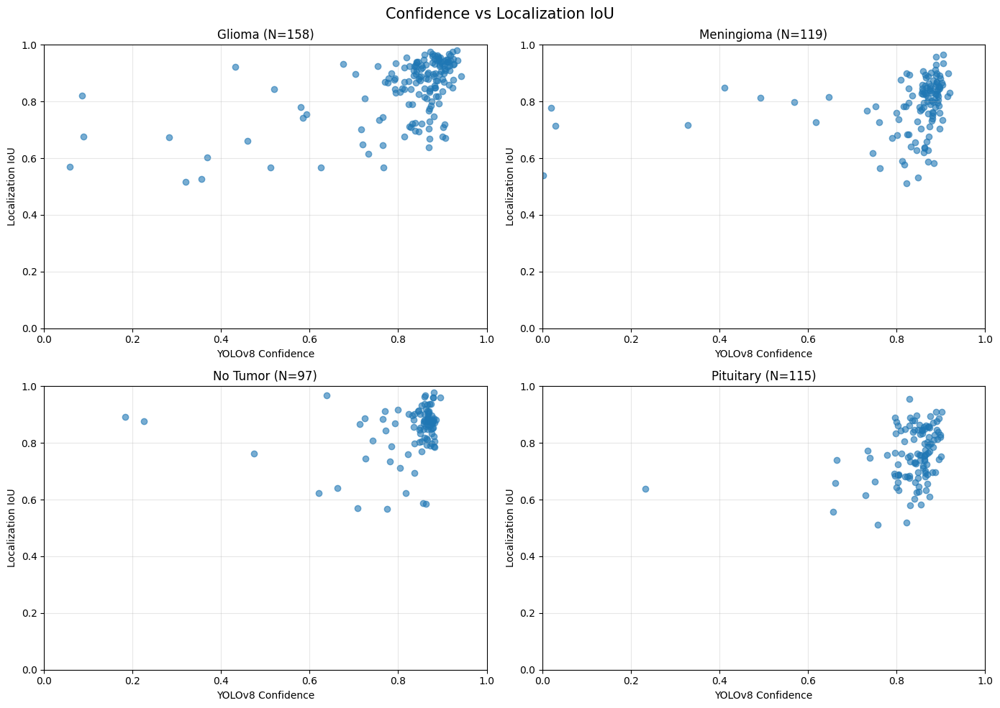

In [ ]:
classes = [
    'Glioma',
    'Meningioma',
    'No Tumor',
    'Pituitary'
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, class_name in zip(axes, classes):

    subset = tp_df[
        tp_df['class_name'] == class_name
    ]

    ax.scatter(
        subset['confidence'],
        subset['IoU'],
        alpha=0.6
    )

    ax.set_title(
        f'{class_name} (N={len(subset)})'
    )

    ax.set_xlabel('YOLOv8 Confidence')
    ax.set_ylabel('Localization IoU')

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.grid(alpha=0.3)

plt.suptitle(
    'Confidence vs Localization IoU',
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
tp_df['Confidence_Bin'] = pd.cut(
    tp_df['confidence'],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

confidence_iou_analysis = (
    tp_df.groupby(
        ['class_name', 'Confidence_Bin'],
        observed=True
    )
    .agg(
        N=('IoU', 'size'),
        Mean_Confidence=('confidence', 'mean'),
        Mean_IoU=('IoU', 'mean'),
        Median_IoU=('IoU', 'median'),
        IoU_STD=('IoU', 'std')
    )
    .reset_index()
)

display(
    confidence_iou_analysis.round(5)
)

,class_name,Confidence_Bin,N,Mean_Confidence,Mean_IoU,Median_IoU,IoU_STD
0,Glioma,"(-0.001, 0.1]",3,0.07755,0.68943,0.67668,0.12564
1,Glioma,"(0.2, 0.3]",1,0.28203,0.67461,0.67461,NaN
2,Glioma,"(0.3, 0.4]",3,0.34816,0.54889,0.52631,0.04670
3,Glioma,"(0.4, 0.5]",2,0.44585,0.79248,0.79248,0.18413
4,Glioma,"(0.5, 0.6]",5,0.55751,0.73822,0.75546,0.10276
5,Glioma,"(0.6, 0.7]",2,0.65072,0.75025,0.75025,0.25809
6,Glioma,"(0.7, 0.8]",19,0.76208,0.79856,0.84452,0.11465
7,Glioma,"(0.8, 0.9]",92,0.86083,0.86211,0.88371,0.08546
8,Glioma,"(0.9, 1.0]",31,0.91449,0.89942,0.92696,0.07580
9,Meningioma,"(-0.001, 0.1]",3,0.01723,0.67663,0.71409,0.12401


In [ ]:
tp_df['Localization_Risk'] = (
    (tp_df['confidence'] >= 0.80) &
    (tp_df['IoU'] < 0.50)
)

risk_summary = (
    tp_df.groupby('class_name')
    .agg(
        Total_TP=('IoU', 'size'),
        High_Confidence_Low_IoU=(
            'Localization_Risk', 'sum'
        )
    )
    .reset_index()
)

risk_summary['Risk_Percentage'] = (
    risk_summary['High_Confidence_Low_IoU'] /
    risk_summary['Total_TP'] * 100
)

display(risk_summary.round(3))

,class_name,Total_TP,High_Confidence_Low_IoU,Risk_Percentage
0,Glioma,158,0,0.0
1,Meningioma,119,0,0.0
2,No Tumor,97,0,0.0
3,Pituitary,115,0,0.0


In [ ]:
output_path = '/content/drive/MyDrive/CLEAR-MRI/'

tp_df.to_csv(
    output_path + 'Localization_Confidence_Data.csv',
    index=False
)

localization_class_df.to_csv(
    output_path + 'Localization_Per_Class.csv',
    index=False
)

confidence_iou_analysis.to_csv(
    output_path + 'Confidence_IoU_Analysis.csv',
    index=False
)

risk_summary.to_csv(
    output_path + 'High_Confidence_Low_IoU.csv',
    index=False
)

print("Eksperimen localization analysis berhasil disimpan.")

Eksperimen localization analysis berhasil disimpan.


In [ ]:
print("Kolom loc_df:")
print(loc_df.columns.tolist())

print("\nKolom cal_df:")
print(cal_df.columns.tolist())

print("\nContoh data lokalisasi:")
display(loc_df.head(10))

print("\nVariabel yang berhubungan dengan prediksi:")
for name in [
    'results',
    'predictions',
    'pred_boxes',
    'gt_boxes',
    'test_results',
    'val_results'
]:
    if name in globals():
        print(name, type(globals()[name]))

Kolom loc_df:
['image', 'class_name', 'confidence', 'correct', 'IoU']

Kolom cal_df:
['image', 'class_name', 'confidence', 'correct', 'IoU']

Contoh data lokalisasi:


,image,class_name,confidence,correct,IoU
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.775953,1,0.865742
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.003739,0,0.000000
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,Glioma,0.839568,1,0.929962
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.841803,1,0.939502
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.002380,0,0.000000
5,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.002308,0,0.000000
6,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.001059,0,0.000000
7,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,Glioma,0.846112,1,0.879508
8,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,Glioma,0.003515,0,0.000000
9,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,Glioma,0.002844,0,0.000000



Variabel yang berhubungan dengan prediksi:
results <class 'list'>
predictions <class 'list'>
pred_boxes <class 'numpy.ndarray'>
gt_boxes <class 'numpy.ndarray'>
test_results <class 'ultralytics.utils.metrics.DetMetrics'>


In [ ]:
import numpy as np

print("=== PRED_BOXES ===")
print("Type:", type(pred_boxes))
print("Shape:", np.asarray(pred_boxes).shape)
print("Contoh:")
print(pred_boxes[:3])

print("\n=== GT_BOXES ===")
print("Type:", type(gt_boxes))
print("Shape:", np.asarray(gt_boxes).shape)
print("Contoh:")
print(gt_boxes[:3])

print("\n=== PREDICTIONS ===")
print("Type:", type(predictions))
print("Jumlah:", len(predictions))

if len(predictions) > 0:
    print("Type elemen pertama:", type(predictions[0]))
    print("Contoh elemen pertama:")
    print(predictions[0])

print("\n=== RESULTS ===")
print("Type:", type(results))
print("Jumlah:", len(results))

if len(results) > 0:
    print("Type elemen pertama:", type(results[0]))
    print("Contoh elemen pertama:")
    print(results[0])

=== PRED_BOXES ===
Type: <class 'numpy.ndarray'>
Shape: (1, 4)
Contoh:
[[     219.73      263.34      311.77       388.1]]

=== GT_BOXES ===
Type: <class 'numpy.ndarray'>
Shape: (1, 4)
Contoh:
[[        221       262.5         310       381.5]]

=== PREDICTIONS ===
Type: <class 'list'>
Jumlah: 1
Type elemen pertama: <class 'dict'>
Contoh elemen pertama:
{'class_id': 3, 'confidence': 0.8290615677833557, 'xyxy': array([     277.38,      242.27,      355.51,      299.28], dtype=float32)}

=== RESULTS ===
Type: <class 'list'>
Jumlah: 12
Type elemen pertama: <class 'dict'>
Contoh elemen pertama:
{'Class': 'Glioma', 'Method': 'YOLOv8 Uncalibrated', 'N': 416, 'ECE': np.float64(0.05139438521795316)}


In [ ]:
print("=== STRUKTUR PREDICTIONS ===")

for i, item in enumerate(predictions[:3]):

    print(f"\nItem {i}")

    if isinstance(item, dict):
        for key, value in item.items():
            if isinstance(value, np.ndarray):
                print(key, value.shape, value.dtype)
            else:
                print(key, type(value), str(value)[:150])

    elif isinstance(item, np.ndarray):
        print("Shape:", item.shape)
        print(item[:3])

    else:
        print(item)

=== STRUKTUR PREDICTIONS ===

Item 0
class_id <class 'int'> 3
confidence <class 'float'> 0.8290615677833557
xyxy (4,) float32


In [ ]:
print("=== DISTRIBUSI IoU ===")

print(loc_df['IoU'].describe())

print("\nJumlah IoU nol:")
print((loc_df['IoU'] == 0).sum())

print("\nJumlah IoU positif:")
print((loc_df['IoU'] > 0).sum())

print("\nDistribusi correct dan IoU:")
print(
    pd.crosstab(
        loc_df['correct'],
        loc_df['IoU'] >= 0.50
    )
)

=== DISTRIBUSI IoU ===
count    1019.000000
mean        0.396223
std         0.408024
min         0.000000
25%         0.000000
50%         0.041899
75%         0.829570
max         0.980210
Name: IoU, dtype: float64

Jumlah IoU nol:
505

Jumlah IoU positif:
514

Distribusi correct dan IoU:
IoU      False  True 
correct              
0          530      0
1            0    489


In [ ]:
import os
import glob
import numpy as np
import pandas as pd

from ultralytics import YOLO
from scipy.optimize import linear_sum_assignment
from pathlib import Path

MODEL_PATH = (
    '/content/drive/MyDrive/CLEAR-MRI/'
    '04_EXPERIMENT/Training_Results/'
    'YOLOv8s_Baseline/weights/best.pt'
)

DATASET_PATH = (
    '/content/drive/MyDrive/CLEAR-MRI/'
    '01_DATASET/Original/'
    'Labeled-MRI-Brain-Tumor-Dataset-1'
)

VAL_IMAGES = os.path.join(DATASET_PATH, 'valid', 'images')
VAL_LABELS = os.path.join(DATASET_PATH, 'valid', 'labels')

model = YOLO(MODEL_PATH)

image_paths = sorted(
    glob.glob(os.path.join(VAL_IMAGES, '*'))
)

print("Model berhasil dimuat.")
print("Jumlah gambar validation:", len(image_paths))
print("Jumlah class:", model.names)

Model berhasil dimuat.
Jumlah gambar validation: 502
Jumlah class: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


In [ ]:
from PIL import Image

def load_yolo_labels(label_path, image_width, image_height):

    if not os.path.exists(label_path):
        return np.empty((0, 5))

    labels = []

    with open(label_path, 'r') as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            cls, xc, yc, w, h = map(float, values)

            x1 = (xc - w/2) * image_width
            y1 = (yc - h/2) * image_height
            x2 = (xc + w/2) * image_width
            y2 = (yc + h/2) * image_height

            labels.append([
                int(cls), x1, y1, x2, y2
            ])

    return np.asarray(labels, dtype=float).reshape(-1, 5)

In [ ]:
def calculate_iou_matrix(boxes1, boxes2):

    if len(boxes1) == 0 or len(boxes2) == 0:
        return np.zeros((len(boxes1), len(boxes2)))

    x1 = np.maximum(
        boxes1[:, None, 0],
        boxes2[None, :, 0]
    )

    y1 = np.maximum(
        boxes1[:, None, 1],
        boxes2[None, :, 1]
    )

    x2 = np.minimum(
        boxes1[:, None, 2],
        boxes2[None, :, 2]
    )

    y2 = np.minimum(
        boxes1[:, None, 3],
        boxes2[None, :, 3]
    )

    intersection = (
        np.maximum(0, x2-x1) *
        np.maximum(0, y2-y1)
    )

    area1 = (
        (boxes1[:, 2]-boxes1[:, 0]) *
        (boxes1[:, 3]-boxes1[:, 1])
    )

    area2 = (
        (boxes2[:, 2]-boxes2[:, 0]) *
        (boxes2[:, 3]-boxes2[:, 1])
    )

    union = (
        area1[:, None] +
        area2[None, :] -
        intersection
    )

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )

In [ ]:
all_localization = []

for idx, image_path in enumerate(image_paths):

    image = Image.open(image_path).convert('RGB')

    width, height = image.size

    label_path = os.path.join(
        VAL_LABELS,
        Path(image_path).stem + '.txt'
    )

    gt = load_yolo_labels(
        label_path,
        width,
        height
    )

    result = model.predict(
        source=image_path,
        imgsz=640,
        conf=0.001,
        iou=0.7,
        verbose=False
    )[0]

    if result.boxes is not None and len(result.boxes) > 0:

        pred_boxes = (
            result.boxes.xyxy.cpu().numpy()
        )

        pred_classes = (
            result.boxes.cls.cpu().numpy().astype(int)
        )

        pred_conf = (
            result.boxes.conf.cpu().numpy()
        )

    else:

        pred_boxes = np.empty((0, 4))
        pred_classes = np.empty(0, dtype=int)
        pred_conf = np.empty(0)

    gt_boxes = gt[:, 1:5]
    gt_classes = gt[:, 0].astype(int)

    # Matriks IoU hanya untuk pasangan kelas yang sama
    iou_matrix = calculate_iou_matrix(
        pred_boxes,
        gt_boxes
    )

    same_class = (
        pred_classes[:, None] ==
        gt_classes[None, :]
    )

    class_iou = iou_matrix * same_class

    # Matching satu-ke-satu tanpa ambang minimum IoU
    if class_iou.size > 0:

        row_ind, col_ind = linear_sum_assignment(
            -class_iou
        )

        matched_predictions = set()

        for r, c in zip(row_ind, col_ind):

            matched_predictions.add(r)

            all_localization.append({
                'image': Path(image_path).name,
                'class_id': int(pred_classes[r]),
                'confidence': float(pred_conf[r]),
                'IoU': float(class_iou[r, c]),
                'matched': True,
                'gt_class_id': int(gt_classes[c])
            })

    else:

        matched_predictions = set()

    # Prediksi yang tidak memperoleh pasangan
    for r in range(len(pred_boxes)):

        if r not in matched_predictions:

            all_localization.append({
                'image': Path(image_path).name,
                'class_id': int(pred_classes[r]),
                'confidence': float(pred_conf[r]),
                'IoU': 0.0,
                'matched': False,
                'gt_class_id': -1
            })

    if (idx+1) % 50 == 0:
        print(f"Processed {idx+1}/{len(image_paths)} images")

localization_raw_df = pd.DataFrame(all_localization)

print("\nInferensi selesai.")
print("Total prediksi:", len(localization_raw_df))
print("Jumlah gambar:", localization_raw_df['image'].nunique())

display(localization_raw_df.head())

Processed 50/502 images
Processed 100/502 images
Processed 150/502 images
Processed 200/502 images
Processed 250/502 images
Processed 300/502 images
Processed 350/502 images
Processed 400/502 images
Processed 450/502 images
Processed 500/502 images

Inferensi selesai.
Total prediksi: 1019
Jumlah gambar: 502


,image,class_id,confidence,IoU,matched,gt_class_id
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775953,0.865742,True,0
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.003739,0.000000,False,-1
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,True,0
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,0.939502,True,0
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.002380,0.000000,False,-1


In [ ]:
thresholds = [0.50, 0.75, 0.90]

threshold_results = []

for threshold in thresholds:

    tp = (
        localization_raw_df['matched'] &
        (localization_raw_df['IoU'] >= threshold)
    ).sum()

    fp = len(localization_raw_df) - tp

    threshold_results.append({
        'IoU_Threshold': threshold,
        'TP': int(tp),
        'FP': int(fp)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,IoU_Threshold,TP,FP
0,0.50,489,530
1,0.75,366,653
2,0.90,99,920


In [ ]:
SAVE_PATH = (
    '/content/drive/MyDrive/CLEAR-MRI/'
)

localization_raw_df.to_csv(
    SAVE_PATH + 'Unthresholded_Localization_Matching.csv',
    index=False
)

threshold_df.to_csv(
    SAVE_PATH + 'Localization_Multi_IoU_Results.csv',
    index=False
)

print("Hasil berhasil disimpan.")

Hasil berhasil disimpan.


In [ ]:
import numpy as np
import pandas as pd

# Prediksi yang mempunyai pasangan kelas yang sama
matched_df = localization_raw_df[
    (localization_raw_df['matched'] == True) &
    (localization_raw_df['class_id'] == localization_raw_df['gt_class_id'])
].copy()

# Pisahkan pasangan dengan IoU positif
positive_iou_df = matched_df[
    matched_df['IoU'] > 0
].copy()

iou_class_summary = (
    positive_iou_df.groupby('class_id')
    .agg(
        N=('IoU', 'size'),
        Mean_IoU=('IoU', 'mean'),
        Median_IoU=('IoU', 'median'),
        STD_IoU=('IoU', 'std'),
        Min_IoU=('IoU', 'min'),
        Max_IoU=('IoU', 'max')
    )
    .reset_index()
)

class_names = model.names

iou_class_summary['Class'] = (
    iou_class_summary['class_id'].map(class_names)
)

display(iou_class_summary.round(5))

,class_id,N,Mean_IoU,Median_IoU,STD_IoU,Min_IoU,Max_IoU,Class
0,0,163,0.83151,0.87716,0.14764,0.04172,0.98021,Glioma
1,1,123,0.77563,0.80226,0.11180,0.41458,0.96550,Meningioma
2,2,97,0.85411,0.87373,0.07706,0.58449,0.97713,No Tumor
3,3,118,0.75195,0.75726,0.10327,0.42176,0.95422,Pituitary


In [ ]:
positive_iou_df['Localization_Level'] = pd.cut(
    positive_iou_df['IoU'],
    bins=[0, 0.50, 0.75, 0.90, 1.000001],
    labels=[
        'Low',
        'Basic',
        'Good',
        'Very Good'
    ],
    right=False
)

iou_distribution = pd.crosstab(
    positive_iou_df['class_id'].map(class_names),
    positive_iou_df['Localization_Level']
)

display(iou_distribution)

Localization_Level,Low,Basic,Good,Very Good
class_id,,,,
Glioma,5,31,65,62
Meningioma,4,33,78,8
No Tumor,0,8,63,26
Pituitary,3,51,61,3


In [ ]:
from scipy.stats import spearmanr, pearsonr

correlation_results = []

for class_id, group in positive_iou_df.groupby('class_id'):

    rho, p_value = spearmanr(
        group['confidence'],
        group['IoU']
    )

    correlation_results.append({
        'Class': class_names[class_id],
        'N': len(group),
        'Spearman_Rho': rho,
        'P_Value': p_value
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(5))

,Class,N,Spearman_Rho,P_Value
0,Glioma,163,0.53567,0.00000
1,Meningioma,123,0.47476,0.00000
2,No Tumor,97,0.17689,0.08305
3,Pituitary,118,0.33658,0.00019


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.isotonic import IsotonicRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Hanya pasangan dengan IoU positif
reg_df = positive_iou_df.copy()

reg_df['class_name'] = (
    reg_df['class_id'].map(model.names)
)

print("Jumlah sampel:", len(reg_df))
print("Jumlah gambar:", reg_df['image'].nunique())

display(reg_df.head())

Jumlah sampel: 501
Jumlah gambar: 498


,image,class_id,confidence,IoU,matched,gt_class_id,Localization_Level,class_name
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775953,0.865742,True,0,Good,Glioma
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,True,0,Very Good,Glioma
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,0.939502,True,0,Very Good,Glioma
7,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,0,0.846112,0.879508,True,0,Good,Glioma
10,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,0,0.905514,0.914690,True,0,Very Good,Glioma


In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        reg_df,
        groups=reg_df['image']
    )
)

train_df = reg_df.iloc[train_idx].copy()
test_df = reg_df.iloc[test_idx].copy()

assert set(train_df['image']).isdisjoint(
    set(test_df['image'])
)

print("Training:", len(train_df))
print("Testing:", len(test_df))

print(
    "Train images:",
    train_df['image'].nunique()
)

print(
    "Test images:",
    test_df['image'].nunique()
)

Training: 375
Testing: 126
Train images: 373
Test images: 125


In [ ]:
features = ['confidence', 'class_name']

preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            StandardScaler(),
            ['confidence']
        ),
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            ['class_name']
        )
    ]
)

linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(
    train_df[features],
    train_df['IoU']
)

pred_linear = np.clip(
    linear_model.predict(test_df[features]),
    0, 1
)

In [ ]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        RandomForestRegressor(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    train_df[features],
    train_df['IoU']
)

pred_rf = np.clip(
    rf_model.predict(test_df[features]),
    0, 1
)

In [ ]:
iso_model = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds='clip'
)

iso_model.fit(
    train_df['confidence'],
    train_df['IoU']
)

pred_iso = iso_model.predict(
    test_df['confidence']
)

In [ ]:
predictions = {
    'Linear Regression': pred_linear,
    'Random Forest': pred_rf,
    'Isotonic Regression': pred_iso
}

evaluation = []

y_true = test_df['IoU'].values

for name, pred in predictions.items():

    evaluation.append({
        'Method': name,
        'N': len(y_true),
        'MAE': mean_absolute_error(y_true, pred),
        'RMSE': np.sqrt(
            mean_squared_error(y_true, pred)
        ),
        'R2': r2_score(y_true, pred)
    })

localization_model_results = pd.DataFrame(
    evaluation
)

display(
    localization_model_results.round(5)
)

,Method,N,MAE,RMSE,R2
0,Linear Regression,126,0.07996,0.12364,0.28407
1,Random Forest,126,0.07754,0.11823,0.34538
2,Isotonic Regression,126,0.09015,0.12786,0.23437


In [ ]:
per_class_results = []

for class_name, group in test_df.groupby('class_name'):

    idx = group.index

    y = group['IoU'].values

    for method, pred in predictions.items():

        pred_series = pd.Series(
            pred,
            index=test_df.index
        )

        p = pred_series.loc[idx].values

        per_class_results.append({
            'Class': class_name,
            'Method': method,
            'N': len(y),
            'MAE': mean_absolute_error(y, p),
            'RMSE': np.sqrt(
                mean_squared_error(y, p)
            ),
            'R2': r2_score(y, p)
        })

per_class_df = pd.DataFrame(
    per_class_results
)

display(per_class_df.round(5))

,Class,Method,N,MAE,RMSE,R2
0,Glioma,Linear Regression,44,0.09642,0.15983,0.33112
1,Glioma,Random Forest,44,0.09534,0.15480,0.37256
2,Glioma,Isotonic Regression,44,0.10095,0.14995,0.41127
3,Meningioma,Linear Regression,27,0.09376,0.13288,-0.17562
4,Meningioma,Random Forest,27,0.08865,0.11954,0.04857
5,Meningioma,Isotonic Regression,27,0.10551,0.14794,-0.45730
6,No Tumor,Linear Regression,19,0.04307,0.05495,-0.46242
7,No Tumor,Random Forest,19,0.04027,0.04992,-0.20699
8,No Tumor,Isotonic Regression,19,0.06636,0.07873,-2.00128
9,Pituitary,Linear Regression,36,0.06897,0.08630,0.06642


In [ ]:
SAVE_PATH = '/content/drive/MyDrive/CLEAR-MRI/'

localization_model_results.to_csv(
    SAVE_PATH + 'Localization_Regression_Results.csv',
    index=False
)

per_class_df.to_csv(
    SAVE_PATH + 'Localization_Regression_Per_Class.csv',
    index=False
)

print("Hasil Localization Quality Estimator tersimpan.")

Hasil Localization Quality Estimator tersimpan.


In [ ]:
geometry_records = []

for image_path in image_paths:

    result = model.predict(
        source=image_path,
        imgsz=640,
        conf=0.001,
        iou=0.7,
        verbose=False
    )[0]

    if result.boxes is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for box, cls, conf in zip(boxes, classes, confidences):

        x1, y1, x2, y2 = box

        width = max(0, x2 - x1)
        height = max(0, y2 - y1)

        geometry_records.append({
            'image': Path(image_path).name,
            'class_id': cls,
            'confidence': conf,
            'box_width': width,
            'box_height': height,
            'box_area': width * height,
            'aspect_ratio': width / max(height, 1e-6)
        })

geometry_df = pd.DataFrame(geometry_records)

print("Jumlah prediksi:", len(geometry_df))
display(geometry_df.head())

Jumlah prediksi: 1019


,image,class_id,confidence,box_width,box_height,box_area,aspect_ratio
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775953,114.420654,43.173523,4939.942871,2.650251
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.003739,88.853760,42.885254,3810.516113,2.071895
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,68.049194,51.005249,3470.866211,1.334161
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,44.022827,69.385971,3054.566650,0.634463
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.002380,50.286682,36.408264,1830.850830,1.381189


In [ ]:
feature_df = geometry_df.merge(
    localization_raw_df[
        ['image', 'class_id', 'confidence', 'IoU', 'matched']
    ],
    on=['image', 'class_id', 'confidence'],
    how='left'
)

print("Jumlah data:", len(feature_df))
print("Missing IoU:", feature_df['IoU'].isna().sum())

Jumlah data: 1019
Missing IoU: 0


In [ ]:
# Periksa jumlah baris
print("Geometry:", len(geometry_df))
print("Localization:", len(localization_raw_df))

# Periksa duplikasi kunci
keys = ['image', 'class_id', 'confidence']

print("\nDuplikasi geometry:")
print(geometry_df.duplicated(keys).sum())

print("\nDuplikasi localization:")
print(localization_raw_df.duplicated(keys).sum())

# Periksa apakah jumlah prediksi konsisten
assert len(geometry_df) == len(localization_raw_df), \
    "Jumlah prediksi tidak sama!"

Geometry: 1019
Localization: 1019

Duplikasi geometry:
0

Duplikasi localization:
0


In [ ]:
feature_df = geometry_df.merge(
    localization_raw_df[
        ['image', 'class_id', 'confidence', 'IoU', 'matched']
    ],
    on=['image', 'class_id', 'confidence'],
    how='left',
    validate='one_to_one'
)

print("Jumlah data:", len(feature_df))
print("IoU kosong:", feature_df['IoU'].isna().sum())
print("Matched:")
print(feature_df['matched'].value_counts(dropna=False))

Jumlah data: 1019
IoU kosong: 0
Matched:
matched
False    514
True     505
Name: count, dtype: int64


In [ ]:
# Ambil deteksi yang memiliki pasangan ground truth
matched_df = feature_df[
    (feature_df['matched'] == True) &
    (feature_df['IoU'] > 0)
].copy()

print("Jumlah matched detection:", len(matched_df))
print("Jumlah gambar:", matched_df['image'].nunique())

# Statistik fitur geometris
geometry_columns = [
    'confidence',
    'box_width',
    'box_height',
    'box_area',
    'aspect_ratio',
    'IoU'
]

display(
    matched_df[geometry_columns]
    .describe()
    .round(4)
)

Jumlah matched detection: 501
Jumlah gambar: 498


,confidence,box_width,box_height,box_area,aspect_ratio,IoU
count,501.0000,501.0000,501.0000,501.0000,501.0000,501.0000
mean,0.8035,143.4673,161.8920,37123.9258,0.9788,0.8034
std,0.1830,107.0870,138.4706,57581.7070,0.2832,0.1238
min,0.0025,34.8622,32.2434,1340.0513,0.4163,0.0417
25%,0.8215,71.3304,75.0226,5665.7837,0.7748,0.7394
50%,0.8602,96.8585,98.8652,9211.5781,0.9246,0.8332
75%,0.8802,165.7615,169.4955,26257.4668,1.1446,0.8880
max,0.9425,458.4455,613.1614,281101.0625,2.6503,0.9802


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# Salin dataset
experiment_df = matched_df.copy()

# Pastikan hanya matched detection dengan IoU positif
experiment_df = experiment_df[
    (experiment_df['matched'] == True) &
    (experiment_df['IoU'] > 0)
].copy()

# Pastikan tipe data
experiment_df['class_id'] = experiment_df['class_id'].astype(str)

# Tambahkan dimensi gambar untuk normalisasi geometri
from PIL import Image

image_size_map = {}

for image_path in image_paths:
    image_path = str(image_path)

    with Image.open(image_path) as img:
        image_size_map[Path(image_path).name] = img.size

experiment_df['image_width'] = experiment_df['image'].map(
    lambda x: image_size_map[x][0]
)

experiment_df['image_height'] = experiment_df['image'].map(
    lambda x: image_size_map[x][1]
)

# Normalisasi fitur geometris
experiment_df['norm_width'] = (
    experiment_df['box_width'] / experiment_df['image_width']
)

experiment_df['norm_height'] = (
    experiment_df['box_height'] / experiment_df['image_height']
)

experiment_df['norm_area'] = (
    experiment_df['box_area'] /
    (experiment_df['image_width'] * experiment_df['image_height'])
)

print("Jumlah data:", len(experiment_df))
print("Jumlah gambar:", experiment_df['image'].nunique())

display(
    experiment_df[
        [
            'confidence',
            'norm_width',
            'norm_height',
            'norm_area',
            'aspect_ratio',
            'IoU'
        ]
    ].describe().round(4)
)

Jumlah data: 501
Jumlah gambar: 498


,confidence,norm_width,norm_height,norm_area,aspect_ratio,IoU
count,501.0000,501.0000,501.0000,501.0000,501.0000,501.0000
mean,0.8035,0.2242,0.2530,0.0906,0.9788,0.8034
std,0.1830,0.1673,0.2164,0.1406,0.2832,0.1238
min,0.0025,0.0545,0.0504,0.0033,0.4163,0.0417
25%,0.8215,0.1115,0.1172,0.0138,0.7748,0.7394
50%,0.8602,0.1513,0.1545,0.0225,0.9246,0.8332
75%,0.8802,0.2590,0.2648,0.0641,1.1446,0.8880
max,0.9425,0.7163,0.9581,0.6863,2.6503,0.9802


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        experiment_df,
        groups=experiment_df['image']
    )
)

train_df = experiment_df.iloc[train_idx].copy()
test_df = experiment_df.iloc[test_idx].copy()

print("Training:")
print("Data:", len(train_df))
print("Gambar:", train_df['image'].nunique())

print("\nTesting:")
print("Data:", len(test_df))
print("Gambar:", test_df['image'].nunique())

# Pastikan tidak ada kebocoran gambar
overlap = set(train_df['image']) & set(test_df['image'])

print("\nIrisan gambar:", len(overlap))

assert len(overlap) == 0

Training:
Data: 375
Gambar: 373

Testing:
Data: 126
Gambar: 125

Irisan gambar: 0


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Definisi fitur
experiments = {
    'A_Confidence': {
        'numeric': ['confidence'],
        'categorical': []
    },

    'B_Confidence_Class': {
        'numeric': ['confidence'],
        'categorical': ['class_id']
    },

    'C_Confidence_Geometry': {
        'numeric': [
            'confidence',
            'norm_width',
            'norm_height',
            'norm_area',
            'aspect_ratio'
        ],
        'categorical': []
    },

    'D_Confidence_Class_Geometry': {
        'numeric': [
            'confidence',
            'norm_width',
            'norm_height',
            'norm_area',
            'aspect_ratio'
        ],
        'categorical': ['class_id']
    }
}

results = []
trained_models = {}

for name, config in experiments.items():

    numeric_features = config['numeric']
    categorical_features = config['categorical']

    transformers = [
        ('numeric', 'passthrough', numeric_features)
    ]

    if categorical_features:
        transformers.append(
            (
                'categorical',
                OneHotEncoder(handle_unknown='ignore'),
                categorical_features
            )
        )

    preprocessor = ColumnTransformer(
        transformers=transformers
    )

    model = Pipeline([
        ('preprocessor', preprocessor),

        ('regressor', RandomForestRegressor(
            n_estimators=500,
            max_depth=None,
            min_samples_split=4,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    X_train = train_df[
        numeric_features + categorical_features
    ]

    X_test = test_df[
        numeric_features + categorical_features
    ]

    y_train = train_df['IoU']
    y_test = test_df['IoU']

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    # IoU berada pada rentang 0-1
    predictions = np.clip(predictions, 0, 1)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Experiment': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='MAE'
    ).reset_index(drop=True).round(5)
)

,Experiment,MAE,RMSE,R2
0,D_Confidence_Class_Geometry,0.07505,0.11387,0.39274
1,B_Confidence_Class,0.08350,0.11805,0.34741
2,C_Confidence_Geometry,0.08648,0.12675,0.24759
3,A_Confidence,0.10067,0.13485,0.14841


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

seeds = [42, 123, 2026, 77, 99]

configs = {
    'A_Confidence': {
        'numeric': ['confidence'],
        'categorical': []
    },
    'B_Confidence_Class': {
        'numeric': ['confidence'],
        'categorical': ['class_id']
    },
    'C_Confidence_Geometry': {
        'numeric': [
            'confidence', 'norm_width', 'norm_height',
            'norm_area', 'aspect_ratio'
        ],
        'categorical': []
    },
    'D_Confidence_Class_Geometry': {
        'numeric': [
            'confidence', 'norm_width', 'norm_height',
            'norm_area', 'aspect_ratio'
        ],
        'categorical': ['class_id']
    }
}

stability_results = []

for seed in seeds:

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.25,
        random_state=seed
    )

    train_idx, test_idx = next(
        splitter.split(
            experiment_df,
            groups=experiment_df['image']
        )
    )

    train = experiment_df.iloc[train_idx]
    test = experiment_df.iloc[test_idx]

    for name, config in configs.items():

        num = config['numeric']
        cat = config['categorical']

        transformers = [
            ('numeric', 'passthrough', num)
        ]

        if cat:
            transformers.append(
                ('categorical',
                 OneHotEncoder(handle_unknown='ignore'),
                 cat)
            )

        preprocessor = ColumnTransformer(
            transformers=transformers
        )

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', RandomForestRegressor(
                n_estimators=500,
                max_depth=None,
                min_samples_split=4,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ])

        pipeline.fit(
            train[num + cat],
            train['IoU']
        )

        pred = np.clip(
            pipeline.predict(test[num + cat]),
            0, 1
        )

        y_true = test['IoU']

        stability_results.append({
            'Seed': seed,
            'Experiment': name,
            'MAE': mean_absolute_error(y_true, pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, pred)),
            'R2': r2_score(y_true, pred)
        })

stability_df = pd.DataFrame(stability_results)

display(
    stability_df.sort_values(
        ['Seed', 'MAE']
    ).round(5)
)

print("\nRata-rata dan standar deviasi:")

stability_summary = (
    stability_df
    .groupby('Experiment')[['MAE', 'RMSE', 'R2']]
    .agg(['mean', 'std'])
)

display(stability_summary.round(5))

,Seed,Experiment,MAE,RMSE,R2
3,42,D_Confidence_Class_Geometry,0.07505,0.11387,0.39274
1,42,B_Confidence_Class,0.08350,0.11805,0.34741
2,42,C_Confidence_Geometry,0.08648,0.12675,0.24759
0,42,A_Confidence,0.10067,0.13485,0.14841
15,77,D_Confidence_Class_Geometry,0.07819,0.09507,0.32826
13,77,B_Confidence_Class,0.07828,0.09935,0.26645
14,77,C_Confidence_Geometry,0.08371,0.10227,0.22268
12,77,A_Confidence,0.09096,0.11563,0.00628
19,99,D_Confidence_Class_Geometry,0.07840,0.11650,-0.04226
18,99,C_Confidence_Geometry,0.08680,0.12257,-0.15368



Rata-rata dan standar deviasi:


MAE              RMSE                R2  \
                                mean      std     mean      std     mean   
Experiment                                                                 
A_Confidence                 0.09790  0.00680  0.13034  0.00925 -0.01136   
B_Confidence_Class           0.08432  0.00566  0.11669  0.01048  0.18639   
C_Confidence_Geometry        0.08741  0.00363  0.12083  0.01054  0.14102   
D_Confidence_Class_Geometry  0.08017  0.00551  0.11236  0.00983  0.25322   

                                      
                                 std  
Experiment                            
A_Confidence                 0.25305  
B_Confidence_Class           0.23680  
C_Confidence_Geometry        0.16682  
D_Confidence_Class_Geometry  0.17221

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

configs = {
    'A_Confidence': {
        'numeric': ['confidence'],
        'categorical': []
    },
    'B_Confidence_Class': {
        'numeric': ['confidence'],
        'categorical': ['class_id']
    },
    'C_Confidence_Geometry': {
        'numeric': [
            'confidence',
            'norm_width',
            'norm_height',
            'norm_area',
            'aspect_ratio'
        ],
        'categorical': []
    },
    'D_Confidence_Class_Geometry': {
        'numeric': [
            'confidence',
            'norm_width',
            'norm_height',
            'norm_area',
            'aspect_ratio'
        ],
        'categorical': ['class_id']
    }
}

gkf = GroupKFold(n_splits=5)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        experiment_df,
        groups=experiment_df['image']
    ), start=1
):

    train = experiment_df.iloc[train_idx]
    test = experiment_df.iloc[test_idx]

    for name, config in configs.items():

        num = config['numeric']
        cat = config['categorical']

        transformers = [
            ('numeric', 'passthrough', num)
        ]

        if cat:
            transformers.append(
                ('categorical',
                 OneHotEncoder(handle_unknown='ignore'),
                 cat)
            )

        preprocessor = ColumnTransformer(
            transformers=transformers
        )

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', RandomForestRegressor(
                n_estimators=500,
                min_samples_split=4,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ])

        pipeline.fit(
            train[num + cat],
            train['IoU']
        )

        pred = np.clip(
            pipeline.predict(test[num + cat]),
            0, 1
        )

        y_true = test['IoU']

        cv_results.append({
            'Fold': fold,
            'Experiment': name,
            'MAE': mean_absolute_error(y_true, pred),
            'RMSE': np.sqrt(
                mean_squared_error(y_true, pred)
            ),
            'R2': r2_score(y_true, pred),
            'Train_images': train['image'].nunique(),
            'Test_images': test['image'].nunique()
        })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values(
        ['Fold', 'MAE']
    ).round(5)
)

print("\nRINGKASAN CROSS-VALIDATION")

cv_summary = (
    cv_df.groupby('Experiment')[['MAE', 'RMSE', 'R2']]
    .agg(['mean', 'std'])
)

display(cv_summary.round(5))

,Fold,Experiment,MAE,RMSE,R2,Train_images,Test_images
3,1,D_Confidence_Class_Geometry,0.06503,0.08335,0.18044,398,100
2,1,C_Confidence_Geometry,0.07155,0.09118,0.01923,398,100
1,1,B_Confidence_Class,0.07238,0.09389,-0.03980,398,100
0,1,A_Confidence,0.08346,0.10556,-0.31450,398,100
7,2,D_Confidence_Class_Geometry,0.06471,0.08468,0.46947,399,99
6,2,C_Confidence_Geometry,0.07131,0.09253,0.36660,399,99
5,2,B_Confidence_Class,0.07674,0.10229,0.22591,399,99
4,2,A_Confidence,0.08927,0.11628,-0.00020,399,99
11,3,D_Confidence_Class_Geometry,0.08534,0.11666,0.21300,399,99
10,3,C_Confidence_Geometry,0.08855,0.12459,0.10238,399,99



RINGKASAN CROSS-VALIDATION


MAE              RMSE                R2  \
                                mean      std     mean      std     mean   
Experiment                                                                 
A_Confidence                 0.09397  0.00807  0.12326  0.01465 -0.07337   
B_Confidence_Class           0.08120  0.00740  0.11040  0.01412  0.14537   
C_Confidence_Geometry        0.08049  0.00854  0.10853  0.01654  0.17754   
D_Confidence_Class_Geometry  0.07517  0.00962  0.10143  0.01710  0.28502   

                                      
                                 std  
Experiment                            
A_Confidence                 0.22302  
B_Confidence_Class           0.15477  
C_Confidence_Geometry        0.15631  
D_Confidence_Class_Geometry  0.13317

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

features_num = [
    'confidence',
    'norm_width',
    'norm_height',
    'norm_area',
    'aspect_ratio'
]

features_cat = ['class_id']
all_features = features_num + features_cat

gkf = GroupKFold(n_splits=5)

importance_records = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        experiment_df,
        groups=experiment_df['image']
    ), start=1
):

    train = experiment_df.iloc[train_idx]
    test = experiment_df.iloc[test_idx]

    preprocessor = ColumnTransformer([
        ('numeric', 'passthrough', features_num),
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         features_cat)
    ])

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=500,
            min_samples_split=4,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(
        train[all_features],
        train['IoU']
    )

    # Permutation importance pada data fold pengujian.
    # Permutasi dilakukan pada kolom asli sebelum preprocessing.
    result = permutation_importance(
        model,
        test[all_features],
        test['IoU'],
        scoring='neg_mean_absolute_error',
        n_repeats=30,
        random_state=42,
        n_jobs=-1
    )

    for feature, mean_imp, std_imp in zip(
        all_features,
        result.importances_mean,
        result.importances_std
    ):

        importance_records.append({
            'Fold': fold,
            'Feature': feature,
            'Importance': mean_imp,
            'Std': std_imp
        })

importance_df = pd.DataFrame(importance_records)

importance_summary = (
    importance_df
    .groupby('Feature')
    .agg(
        Mean_Importance=('Importance', 'mean'),
        SD_Importance=('Importance', 'std')
    )
    .sort_values('Mean_Importance', ascending=False)
)

display(importance_summary.round(6))

,Mean_Importance,SD_Importance
Feature,,
confidence,0.016322,0.008531
class_id,0.011939,0.000900
norm_height,0.008372,0.002645
aspect_ratio,0.002631,0.000617
norm_area,0.000574,0.001214
norm_width,0.000414,0.000663


In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ablation_configs = {
    'M1_Confidence_Class': {
        'numeric': ['confidence'],
        'categorical': ['class_id']
    },

    'M2_Add_NormHeight': {
        'numeric': ['confidence', 'norm_height'],
        'categorical': ['class_id']
    },

    'M3_Add_AspectRatio': {
        'numeric': [
            'confidence',
            'norm_height',
            'aspect_ratio'
        ],
        'categorical': ['class_id']
    },

    'M4_Full_Geometry': {
        'numeric': [
            'confidence',
            'norm_width',
            'norm_height',
            'norm_area',
            'aspect_ratio'
        ],
        'categorical': ['class_id']
    }
}

gkf = GroupKFold(n_splits=5)
ablation_results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        experiment_df,
        groups=experiment_df['image']
    ), start=1
):

    train = experiment_df.iloc[train_idx]
    test = experiment_df.iloc[test_idx]

    for name, config in ablation_configs.items():

        num = config['numeric']
        cat = config['categorical']

        transformers = [
            ('numeric', 'passthrough', num),
            ('categorical',
             OneHotEncoder(handle_unknown='ignore'),
             cat)
        ]

        preprocessor = ColumnTransformer(
            transformers=transformers
        )

        model = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', RandomForestRegressor(
                n_estimators=500,
                min_samples_split=4,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(
            train[num + cat],
            train['IoU']
        )

        predictions = np.clip(
            model.predict(test[num + cat]),
            0,
            1
        )

        y_true = test['IoU']

        ablation_results.append({
            'Fold': fold,
            'Model': name,
            'MAE': mean_absolute_error(
                y_true, predictions
            ),
            'RMSE': np.sqrt(
                mean_squared_error(
                    y_true, predictions
                )
            ),
            'R2': r2_score(
                y_true, predictions
            )
        })

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.round(5)
)

print("\nSUMMARY")

ablation_summary = (
    ablation_df
    .groupby('Model')[['MAE', 'RMSE', 'R2']]
    .agg(['mean', 'std'])
)

display(ablation_summary.round(5))

,Fold,Model,MAE,RMSE,R2
0,1,M1_Confidence_Class,0.07238,0.09389,-0.03980
1,1,M2_Add_NormHeight,0.06951,0.08703,0.10652
2,1,M3_Add_AspectRatio,0.06514,0.08370,0.17356
3,1,M4_Full_Geometry,0.06503,0.08335,0.18044
4,2,M1_Confidence_Class,0.07674,0.10229,0.22591
5,2,M2_Add_NormHeight,0.06634,0.08732,0.43599
6,2,M3_Add_AspectRatio,0.06404,0.08391,0.47909
7,2,M4_Full_Geometry,0.06471,0.08468,0.46947
8,3,M1_Confidence_Class,0.09195,0.12804,0.05194
9,3,M2_Add_NormHeight,0.08609,0.12200,0.13929



SUMMARY


MAE              RMSE                R2         
                        mean      std     mean      std     mean      std
Model                                                                    
M1_Confidence_Class  0.08120  0.00740  0.11040  0.01412  0.14537  0.15477
M2_Add_NormHeight    0.07592  0.00803  0.10331  0.01681  0.25555  0.14776
M3_Add_AspectRatio   0.07449  0.00935  0.10063  0.01667  0.29484  0.13604
M4_Full_Geometry     0.07517  0.00962  0.10143  0.01710  0.28502  0.13317

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

numeric_features = [
    'confidence',
    'norm_height',
    'aspect_ratio'
]

categorical_features = ['class_id']

all_features = numeric_features + categorical_features

models = {
    'Random_Forest': RandomForestRegressor(
        n_estimators=500,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Extra_Trees': ExtraTreesRegressor(
        n_estimators=500,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Hist_Gradient_Boosting': HistGradientBoostingRegressor(
        max_iter=200,
        max_leaf_nodes=15,
        learning_rate=0.05,
        l2_regularization=1.0,
        random_state=42
    )
}

gkf = GroupKFold(n_splits=5)

algorithm_results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        experiment_df,
        groups=experiment_df['image']
    ), start=1
):

    train = experiment_df.iloc[train_idx]
    test = experiment_df.iloc[test_idx]

    for model_name, estimator in models.items():

        preprocessor = ColumnTransformer([
            ('numeric', 'passthrough', numeric_features),

            ('categorical',
             OneHotEncoder(handle_unknown='ignore'),
             categorical_features)
        ])

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', estimator)
        ])

        pipeline.fit(
            train[all_features],
            train['IoU']
        )

        predictions = np.clip(
            pipeline.predict(test[all_features]),
            0,
            1
        )

        y_true = test['IoU']

        algorithm_results.append({
            'Fold': fold,
            'Algorithm': model_name,
            'MAE': mean_absolute_error(
                y_true, predictions
            ),
            'RMSE': np.sqrt(
                mean_squared_error(
                    y_true, predictions
                )
            ),
            'R2': r2_score(
                y_true, predictions
            )
        })

algorithm_df = pd.DataFrame(algorithm_results)

display(
    algorithm_df.round(5)
)

print("\nSUMMARY")

algorithm_summary = (
    algorithm_df
    .groupby('Algorithm')[['MAE', 'RMSE', 'R2']]
    .agg(['mean', 'std'])
)

display(algorithm_summary.round(5))

,Fold,Algorithm,MAE,RMSE,R2
0,1,Random_Forest,0.06514,0.08370,0.17356
1,1,Extra_Trees,0.06670,0.08437,0.16038
2,1,Hist_Gradient_Boosting,0.06859,0.09006,0.04335
3,2,Random_Forest,0.06404,0.08391,0.47909
4,2,Extra_Trees,0.06911,0.09193,0.37475
5,2,Hist_Gradient_Boosting,0.07035,0.09088,0.38897
6,3,Random_Forest,0.08494,0.11638,0.21677
7,3,Extra_Trees,0.08072,0.10996,0.30073
8,3,Hist_Gradient_Boosting,0.08311,0.11732,0.20407
9,4,Random_Forest,0.07869,0.11785,0.40028



SUMMARY


MAE              RMSE                R2         
                           mean      std     mean      std     mean      std
Algorithm                                                                   
Extra_Trees             0.07293  0.00557  0.09784  0.01060  0.32553  0.12698
Hist_Gradient_Boosting  0.07852  0.00833  0.10722  0.01708  0.20068  0.13908
Random_Forest           0.07449  0.00935  0.10063  0.01667  0.29484  0.13604

In [ ]:
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric_features = [
    'confidence',
    'norm_height',
    'aspect_ratio'
]

categorical_features = ['class_id']
all_features = numeric_features + categorical_features

outer_cv = GroupKFold(n_splits=5)

param_grids = {
    'Extra_Trees': {
        'regressor__n_estimators': [300, 500],
        'regressor__min_samples_split': [2, 4, 8],
        'regressor__min_samples_leaf': [1, 2, 4],
        'regressor__max_features': [0.8, 1.0]
    },

    'Random_Forest': {
        'regressor__n_estimators': [300, 500],
        'regressor__min_samples_split': [2, 4, 8],
        'regressor__min_samples_leaf': [1, 2, 4],
        'regressor__max_features': [0.8, 1.0]
    }
}

nested_results = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(
        experiment_df,
        groups=experiment_df['image']
    ), start=1
):

    train = experiment_df.iloc[train_idx]
    test = experiment_df.iloc[test_idx]

    for algorithm, estimator in {
        'Extra_Trees': ExtraTreesRegressor(
            random_state=42,
            n_jobs=1
        ),
        'Random_Forest': RandomForestRegressor(
            random_state=42,
            n_jobs=1
        )
    }.items():

        preprocessor = ColumnTransformer([
            ('numeric', 'passthrough', numeric_features),
            ('categorical',
             OneHotEncoder(handle_unknown='ignore'),
             categorical_features)
        ])

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', estimator)
        ])

        inner_cv = GroupKFold(n_splits=4)

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[algorithm],
            scoring='neg_mean_absolute_error',
            cv=inner_cv,
            n_jobs=-1,
            refit=True
        )

        search.fit(
            train[all_features],
            train['IoU'],
            groups=train['image']
        )

        predictions = np.clip(
            search.best_estimator_.predict(
                test[all_features]
            ),
            0,
            1
        )

        y_true = test['IoU']

        nested_results.append({
            'Fold': fold,
            'Algorithm': algorithm,
            'MAE': mean_absolute_error(y_true, predictions),
            'RMSE': np.sqrt(
                mean_squared_error(y_true, predictions)
            ),
            'R2': r2_score(y_true, predictions),
            'Best_Params': search.best_params_
        })

nested_df = pd.DataFrame(nested_results)

display(
    nested_df[
        ['Fold', 'Algorithm', 'MAE', 'RMSE', 'R2']
    ].round(5)
)

print("\nNested CV Summary:")

nested_summary = (
    nested_df
    .groupby('Algorithm')[['MAE', 'RMSE', 'R2']]
    .agg(['mean', 'std'])
)

display(nested_summary.round(5))

,Fold,Algorithm,MAE,RMSE,R2
0,1,Extra_Trees,0.06471,0.08110,0.22423
1,1,Random_Forest,0.06432,0.08294,0.18859
2,2,Extra_Trees,0.06692,0.08967,0.40516
3,2,Random_Forest,0.06433,0.08398,0.47820
4,3,Extra_Trees,0.08185,0.11023,0.29734
5,3,Random_Forest,0.08411,0.11454,0.24130
6,4,Extra_Trees,0.07391,0.11324,0.44633
7,4,Random_Forest,0.07774,0.11939,0.38455
8,5,Extra_Trees,0.07442,0.09317,0.32706
9,5,Random_Forest,0.07952,0.09964,0.23047



Nested CV Summary:


MAE              RMSE                R2         
                  mean      std     mean      std     mean      std
Algorithm                                                          
Extra_Trees    0.07236  0.00680  0.09748  0.01377  0.34002  0.08795
Random_Forest  0.07401  0.00914  0.10010  0.01684  0.30462  0.12195

In [ ]:
# Ringkasan status matching
print("Total prediksi:", len(localization_raw_df))

print("\nStatus matched:")
print(localization_raw_df['matched'].value_counts())

print("\nDistribusi IoU berdasarkan status:")
display(
    localization_raw_df
    .groupby('matched')['IoU']
    .agg(['count', 'min', 'median', 'mean', 'max'])
    .round(5)
)

# Periksa matched dengan IoU nol
zero_matched = localization_raw_df[
    (localization_raw_df['matched'] == True) &
    (localization_raw_df['IoU'] <= 0)
]

print("\nMatched dengan IoU <= 0:", len(zero_matched))

display(zero_matched.head(10))

Total prediksi: 1019

Status matched:
matched
False    514
True     505
Name: count, dtype: int64

Distribusi IoU berdasarkan status:


,count,min,median,mean,max
matched,,,,,
False,514,0.0,0.00000,0.00000,0.00000
True,505,0.0,0.83281,0.79707,0.98021



Matched dengan IoU <= 0: 4


,image,class_id,confidence,IoU,matched,gt_class_id
459,Tr-me_0188_jpg.rf.51d1fce5dda5ef0bf4055217915a...,2,0.820890,0.0,True,1
566,Tr-me_0359_jpg.rf.5853939dbfd89bc00ae367d436ce...,2,0.855116,0.0,True,1
642,Tr-no_0052_jpg.rf.6a63634edac060a9076b23ce6f6f...,1,0.452928,0.0,True,2
822,Tr-no_0465_jpg.rf.cf4abbaed4efed6795a8e1aa05e5...,1,0.750036,0.0,True,2


In [ ]:
# Hitung jumlah ground truth dari file label YOLO
from pathlib import Path
from collections import Counter

label_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/labels"
)

gt_counter = Counter()

for label_file in label_dir.glob("*.txt"):

    with open(label_file, "r") as f:
        for line in f:

            parts = line.strip().split()

            if len(parts) >= 5:
                class_id = int(parts[0])
                gt_counter[class_id] += 1

print("Ground truth per class:")
print(gt_counter)

print("\nTotal ground truth:", sum(gt_counter.values()))

Ground truth per class:
Counter({0: 163, 1: 125, 3: 118, 2: 99})

Total ground truth: 505


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO

# Model baseline
model = YOLO(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Training_Results/YOLOv8s_Baseline/weights/best.pt"
)

# Folder validasi
image_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/images"
)

label_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/labels"
)

image_paths = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in ['.jpg', '.jpeg', '.png']
])

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2-x1) * max(0, y2-y1)

    area1 = (
        max(0, box1[2]-box1[0]) *
        max(0, box1[3]-box1[1])
    )

    area2 = (
        max(0, box2[2]-box2[0]) *
        max(0, box2[3]-box2[1])
    )

    union = area1 + area2 - inter

    return inter / union if union > 0 else 0


# Inferensi ulang dan pencatatan prediksi
corrected_records = []
gt_total = 0

for image_path in image_paths:

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        iou=0.7,
        verbose=False
    )[0]

    pred_boxes = result.boxes.xyxy.cpu().numpy()
    pred_classes = result.boxes.cls.cpu().numpy().astype(int)
    pred_conf = result.boxes.conf.cpu().numpy()

    label_path = label_dir / f"{image_path.stem}.txt"

    gt_boxes = []
    gt_classes = []

    if label_path.exists():

        with open(label_path, 'r') as f:

            for line in f:

                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls = int(values[0])
                xc, yc, w, h = map(float, values[1:5])

                # Konversi YOLO normalized ke pixel
                img_h, img_w = result.orig_shape

                x1 = (xc - w/2) * img_w
                y1 = (yc - h/2) * img_h
                x2 = (xc + w/2) * img_w
                y2 = (yc + h/2) * img_h

                gt_boxes.append([x1, y1, x2, y2])
                gt_classes.append(cls)

    gt_boxes = np.array(gt_boxes).reshape(-1, 4)
    gt_classes = np.array(gt_classes, dtype=int)

    gt_total += len(gt_boxes)

    # Matriks IoU hanya untuk kelas yang sama
    iou_matrix = np.zeros(
        (len(pred_boxes), len(gt_boxes))
    )

    for i, pred_box in enumerate(pred_boxes):

        for j, gt_box in enumerate(gt_boxes):

            if pred_classes[i] == gt_classes[j]:

                iou_matrix[i, j] = calculate_iou(
                    pred_box, gt_box
                )

    # Hungarian matching
    if iou_matrix.size > 0:

        rows, cols = linear_sum_assignment(-iou_matrix)

        valid_pairs = []

        for r, c in zip(rows, cols):

            if iou_matrix[r, c] > 0:

                valid_pairs.append((r, c))

    else:
        valid_pairs = []

    matched_predictions = {
        r: c for r, c in valid_pairs
    }

    for i, (box, cls, conf) in enumerate(
        zip(pred_boxes, pred_classes, pred_conf)
    ):

        if i in matched_predictions:

            j = matched_predictions[i]

            iou_value = iou_matrix[i, j]
            matched = True
            gt_cls = gt_classes[j]

        else:

            iou_value = 0.0
            matched = False
            gt_cls = -1

        corrected_records.append({
            'image': image_path.name,
            'class_id': int(cls),
            'confidence': float(conf),
            'IoU': float(iou_value),
            'matched': matched,
            'gt_class_id': int(gt_cls)
        })


corrected_df = pd.DataFrame(corrected_records)

print("Total prediction:", len(corrected_df))
print("Total ground truth:", gt_total)

print("\nMatching:")
print(corrected_df['matched'].value_counts())

print("\nMatched lintas kelas:")
print(
    corrected_df[
        corrected_df['matched'] &
        (corrected_df['class_id'] != corrected_df['gt_class_id'])
    ]
)

Total prediction: 1019
Total ground truth: 505

Matching:
matched
False    518
True     501
Name: count, dtype: int64

Matched lintas kelas:
Empty DataFrame
Columns: [image, class_id, confidence, IoU, matched, gt_class_id]
Index: []


In [ ]:
# Evaluasi TP, FP, FN pada threshold IoU
evaluation_results = []

for threshold in [0.50, 0.75, 0.90]:

    tp = (
        corrected_df['matched'] &
        (corrected_df['IoU'] >= threshold)
    ).sum()

    fp = len(corrected_df) - tp
    fn = gt_total - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    evaluation_results.append({
        'IoU_Threshold': threshold,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    })

display(
    pd.DataFrame(evaluation_results).round(5)
)

,IoU_Threshold,TP,FP,FN,Precision,Recall,F1
0,0.50,489,530,16,0.47988,0.96832,0.64173
1,0.75,366,653,139,0.35918,0.72475,0.48031
2,0.90,99,920,406,0.09715,0.19604,0.12992


In [ ]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd

thresholds = [0.50, 0.75, 0.90]

# Membaca seluruh ground truth
gt_records = []

for label_file in label_dir.glob("*.txt"):

    image_name = label_file.stem

    with open(label_file, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) < 5:
                continue

            cls = int(values[0])
            xc, yc, w, h = map(float, values[1:5])

            gt_records.append({
                'image': image_name,
                'class_id': cls,
                'xc': xc,
                'yc': yc,
                'w': w,
                'h': h
            })

gt_df = pd.DataFrame(gt_records)

# Periksa jumlah GT
print("Ground truth:", len(gt_df))

# Siapkan prediksi
pred_df = corrected_df.copy()

pred_df['image'] = pred_df['image'].apply(
    lambda x: Path(x).stem
)

def calculate_iou_xyxy(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2-x1) * max(0, y2-y1)

    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0

# Gunakan corrected_df yang telah memiliki IoU hasil matching.
# Untuk evaluasi standar, kita perlu menghitung ulang IoU
# seluruh pasangan prediksi-GT dari koordinat bounding box.
#
# Karena corrected_df saat ini tidak menyimpan koordinat prediksi,
# lakukan inferensi ulang atau modifikasi kode inferensi sebelumnya
# agar menyimpan pred_box dan GT box untuk setiap gambar.

print("Prediksi:", len(pred_df))
print("GT:", len(gt_df))

Ground truth: 505
Prediksi: 1019
GT: 505


In [ ]:
prediction_records = []

for image_path in image_paths:

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        iou=0.7,
        verbose=False
    )[0]

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for box, cls, conf in zip(boxes, classes, confidences):

        prediction_records.append({
            'image': image_path.name,
            'class_id': int(cls),
            'confidence': float(conf),
            'x1': float(box[0]),
            'y1': float(box[1]),
            'x2': float(box[2]),
            'y2': float(box[3])
        })

pred_coord_df = pd.DataFrame(prediction_records)

print("Total prediksi:", len(pred_coord_df))
print("Jumlah gambar:", pred_coord_df['image'].nunique())

display(pred_coord_df.head())

Total prediksi: 1019
Jumlah gambar: 502


,image,class_id,confidence,x1,y1,x2,y2
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775953,265.856995,324.595764,380.277649,367.769287
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.003739,274.644775,318.023041,363.498535,360.908295
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,319.180756,331.967041,387.229950,382.972290
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,313.616150,59.448212,357.638977,128.834183
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.002380,309.320374,269.756561,359.607056,306.164825


In [ ]:
print("Kolom gt_df:")
print(gt_df.columns.tolist())

print("\nUkuran data:", gt_df.shape)

display(gt_df.head())

print("\nStruktur pred_coord_df:")
print(pred_coord_df.columns.tolist())

display(pred_coord_df.head())

Kolom gt_df:
['image', 'class_id', 'xc', 'yc', 'w', 'h']

Ukuran data: (505, 6)


,image,class_id,xc,yc,w,h
0,Tr-me_0273_jpg.rf.e821f985136dc5ea5624c278c79c...,1,0.335156,0.668750,0.312500,0.333594
1,Tr-gl_0474_jpg.rf.ecd6d8ae0f7f05808ddfffd016ee...,0,0.382812,0.573438,0.140625,0.162500
2,Tr-pi_0545_jpg.rf.a0454e38fa522ea4c601f6253b96...,3,0.479687,0.400000,0.123438,0.117188
3,Tr-gl_0504_jpg.rf.59a2acc5991906a4f21f01bee66f...,0,0.353125,0.329688,0.176563,0.168750
4,Tr-me_0248_jpg.rf.d91c138f8ab0beb25fe82ea8a29e...,1,0.645312,0.428125,0.271875,0.300781



Struktur pred_coord_df:
['image', 'class_id', 'confidence', 'x1', 'y1', 'x2', 'y2']


,image,class_id,confidence,x1,y1,x2,y2
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775953,265.856995,324.595764,380.277649,367.769287
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.003739,274.644775,318.023041,363.498535,360.908295
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,319.180756,331.967041,387.229950,382.972290
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,313.616150,59.448212,357.638977,128.834183
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.002380,309.320374,269.756561,359.607056,306.164825


In [ ]:
print("Kolom gt_df:")
print(gt_df.columns.tolist())

print("\nUkuran DataFrame:")
print(gt_df.shape)

print("\nLima baris pertama:")
display(gt_df.head())

print("\nTipe data:")
print(gt_df.dtypes)

Kolom gt_df:
['image', 'class_id', 'xc', 'yc', 'w', 'h']

Ukuran DataFrame:
(505, 6)

Lima baris pertama:


,image,class_id,xc,yc,w,h
0,Tr-me_0273_jpg.rf.e821f985136dc5ea5624c278c79c...,1,0.335156,0.668750,0.312500,0.333594
1,Tr-gl_0474_jpg.rf.ecd6d8ae0f7f05808ddfffd016ee...,0,0.382812,0.573438,0.140625,0.162500
2,Tr-pi_0545_jpg.rf.a0454e38fa522ea4c601f6253b96...,3,0.479687,0.400000,0.123438,0.117188
3,Tr-gl_0504_jpg.rf.59a2acc5991906a4f21f01bee66f...,0,0.353125,0.329688,0.176563,0.168750
4,Tr-me_0248_jpg.rf.d91c138f8ab0beb25fe82ea8a29e...,1,0.645312,0.428125,0.271875,0.300781



Tipe data:
image        object
class_id      int64
xc          float64
yc          float64
w           float64
h           float64
dtype: object


In [ ]:
from pathlib import Path

label_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/labels"
)

label_files = sorted(label_dir.glob("*.txt"))

print("Jumlah file label:", len(label_files))

for file in label_files[:3]:
    print(f"\nFile: {file.name}")
    print(file.read_text()[:500])

Jumlah file label: 502

File: Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88fabac.txt
0 0.49921875 0.54375 0.1859375 0.0640625

File: Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d741b1.txt
0 0.5515625 0.5609375 0.1078125 0.0828125

File: Tr-gl_0015_jpg.rf.f19712315a693c8362217ca980843f70.txt
0 0.525 0.14921875 0.0671875 0.1078125


In [ ]:
from pathlib import Path
from PIL import Image

image_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/images"
)

# Buat indeks nama file tanpa ekstensi
image_index = {
    p.stem: p
    for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in [
        '.jpg', '.jpeg', '.png'
    ]
}

image_dimensions = {}
missing_images = []

for image_name in gt_df['image'].unique():

    image_path = image_index.get(Path(image_name).stem)

    if image_path is None:
        missing_images.append(image_name)
        continue

    with Image.open(image_path) as img:
        image_dimensions[image_name] = img.size

print("Gambar ditemukan:", len(image_dimensions))
print("Gambar tidak ditemukan:", len(missing_images))

if missing_images:
    print("Contoh gambar tidak ditemukan:", missing_images[:5])

Gambar ditemukan: 0
Gambar tidak ditemukan: 502
Contoh gambar tidak ditemukan: ['Tr-me_0273_jpg.rf.e821f985136dc5ea5624c278c79c5036', 'Tr-gl_0474_jpg.rf.ecd6d8ae0f7f05808ddfffd016eee1e2', 'Tr-pi_0545_jpg.rf.a0454e38fa522ea4c601f6253b965552', 'Tr-gl_0504_jpg.rf.59a2acc5991906a4f21f01bee66fecde', 'Tr-me_0248_jpg.rf.d91c138f8ab0beb25fe82ea8a29e30af']


In [ ]:
from pathlib import Path

image_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/images"
)

print("Direktori ditemukan:", image_dir.exists())

if image_dir.exists():
    print("Jumlah file:", len(list(image_dir.iterdir())))

    for p in list(image_dir.iterdir())[:10]:
        print(repr(p.name))

Direktori ditemukan: True
Jumlah file: 502
'Tr-gl_0078_jpg.rf.00aabf2032db6b833dd24f8cb2a3dd4b.jpg'
'Tr-gl_0559_jpg.rf.1d8d257bbcb800f2e59cbf1d4cbfc2ea.jpg'
'Tr-gl_0096_jpg.rf.cea0f0e567f962a034cf7fbc788f13e7.jpg'
'Tr-gl_0057_jpg.rf.825bc3f1fb9ca596ff8e35935507dfa6.jpg'
'Tr-gl_0022_jpg.rf.829d7981e97aa2778a67a60119cf4d9d.jpg'
'Tr-gl_0333_jpg.rf.f874fba563cd3e860879a5955cdff5e0.jpg'
'Tr-no_0454_jpg.rf.24fb7d2cdfa787b92a1d3baefb374242.jpg'
'Tr-me_0259_jpg.rf.21f3db444d8c71136a5f06dbcc4f65cf.jpg'
'Tr-pi_0172_jpg.rf.70d659440e024788242bbc4c081a848e.jpg'
'Tr-gl_0322_jpg.rf.58715ba6f49908df83f4d4dbe0370049.jpg'


In [ ]:
import os

base_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1"
)

print("Isi folder dataset:")

for root, dirs, files in os.walk(base_dir):
    print(root, "Jumlah file:", len(files))

    if root.count(os.sep) - str(base_dir).count(os.sep) >= 2:
        dirs[:] = []

Isi folder dataset:
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1 Jumlah file: 3
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test Jumlah file: 1
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test/images Jumlah file: 246
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test/labels Jumlah file: 246
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/valid Jumlah file: 1
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/valid/labels Jumlah file: 502
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/valid/images Jumlah file: 502
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/train Jumlah file: 1
/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/tr

In [ ]:
print("Contoh nama pada prediksi:")
display(pred_coord_df[['image']].head(5))

print("\nContoh nama pada ground truth:")
display(gt_df[['image']].head(5))

print("\nContoh nama file aktual:")
for p in list(image_dir.iterdir())[:5]:
    print(p.name)

Contoh nama pada prediksi:


,image
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...



Contoh nama pada ground truth:


,image
0,Tr-me_0273_jpg.rf.e821f985136dc5ea5624c278c79c...
1,Tr-gl_0474_jpg.rf.ecd6d8ae0f7f05808ddfffd016ee...
2,Tr-pi_0545_jpg.rf.a0454e38fa522ea4c601f6253b96...
3,Tr-gl_0504_jpg.rf.59a2acc5991906a4f21f01bee66f...
4,Tr-me_0248_jpg.rf.d91c138f8ab0beb25fe82ea8a29e...



Contoh nama file aktual:
Tr-gl_0078_jpg.rf.00aabf2032db6b833dd24f8cb2a3dd4b.jpg
Tr-gl_0559_jpg.rf.1d8d257bbcb800f2e59cbf1d4cbfc2ea.jpg
Tr-gl_0096_jpg.rf.cea0f0e567f962a034cf7fbc788f13e7.jpg
Tr-gl_0057_jpg.rf.825bc3f1fb9ca596ff8e35935507dfa6.jpg
Tr-gl_0022_jpg.rf.829d7981e97aa2778a67a60119cf4d9d.jpg


In [ ]:
from pathlib import Path

image_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/images"
)

# Peta nama file tanpa ekstensi ke nama file aktual
image_index = {
    p.stem: p.name
    for p in image_dir.iterdir()
    if p.is_file()
}

# Normalisasi nama pada kedua DataFrame
gt_df = gt_df.copy()
pred_coord_df = pred_coord_df.copy()

gt_df['image_key'] = gt_df['image'].apply(
    lambda x: Path(x).stem
)

pred_coord_df['image_key'] = pred_coord_df['image'].apply(
    lambda x: Path(x).stem
)

# Periksa apakah semua nama dapat ditemukan
gt_missing = set(gt_df['image_key']) - set(image_index)
pred_missing = set(pred_coord_df['image_key']) - set(image_index)

print("GT tidak ditemukan:", len(gt_missing))
print("Prediksi tidak ditemukan:", len(pred_missing))

print("Jumlah gambar GT:", gt_df['image_key'].nunique())
print("Jumlah gambar prediksi:", pred_coord_df['image_key'].nunique())

GT tidak ditemukan: 489
Prediksi tidak ditemukan: 0
Jumlah gambar GT: 489
Jumlah gambar prediksi: 502


In [ ]:
from pathlib import Path

image_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1/valid/images"
)

def normalize_image_name(name):
    name = str(name).strip()

    for ext in ['.jpg', '.jpeg', '.png']:
        if name.lower().endswith(ext):
            name = name[:-len(ext)]
            break

    return name

# Indeks file gambar aktual
image_index = {
    normalize_image_name(p.name): p
    for p in image_dir.iterdir()
    if p.is_file()
}

gt_df = gt_df.copy()
pred_coord_df = pred_coord_df.copy()

gt_df['image_key'] = gt_df['image'].apply(normalize_image_name)
pred_coord_df['image_key'] = pred_coord_df['image'].apply(normalize_image_name)

gt_missing = set(gt_df['image_key']) - set(image_index)
pred_missing = set(pred_coord_df['image_key']) - set(image_index)

print("GT tidak ditemukan:", len(gt_missing))
print("Prediksi tidak ditemukan:", len(pred_missing))
print("Jumlah gambar GT:", gt_df['image_key'].nunique())
print("Jumlah gambar prediksi:", pred_coord_df['image_key'].nunique())

GT tidak ditemukan: 0
Prediksi tidak ditemukan: 0
Jumlah gambar GT: 502
Jumlah gambar prediksi: 502


In [ ]:
from PIL import Image

image_dimensions = {}

for image_key, image_path in image_index.items():
    with Image.open(image_path) as img:
        image_dimensions[image_key] = img.size

gt_df['image_width'] = gt_df['image_key'].map(
    lambda x: image_dimensions[x][0]
)

gt_df['image_height'] = gt_df['image_key'].map(
    lambda x: image_dimensions[x][1]
)

gt_df['x1'] = (gt_df['xc'] - gt_df['w'] / 2) * gt_df['image_width']
gt_df['y1'] = (gt_df['yc'] - gt_df['h'] / 2) * gt_df['image_height']
gt_df['x2'] = (gt_df['xc'] + gt_df['w'] / 2) * gt_df['image_width']
gt_df['y2'] = (gt_df['yc'] + gt_df['h'] / 2) * gt_df['image_height']

# Samakan identitas gambar
gt_df['image'] = gt_df['image_key']
pred_coord_df['image'] = pred_coord_df['image_key']

print("Ground truth:", len(gt_df))
print("Prediksi:", len(pred_coord_df))
print("Gambar GT:", gt_df['image'].nunique())
print("Gambar prediksi:", pred_coord_df['image'].nunique())

Ground truth: 505
Prediksi: 1019
Gambar GT: 502
Gambar prediksi: 502


In [ ]:
# Periksa koordinat ground truth
invalid_gt = gt_df[
    (gt_df['x1'] < 0) |
    (gt_df['y1'] < 0) |
    (gt_df['x2'] > gt_df['image_width']) |
    (gt_df['y2'] > gt_df['image_height']) |
    (gt_df['x2'] <= gt_df['x1']) |
    (gt_df['y2'] <= gt_df['y1'])
]

# Periksa koordinat prediksi
invalid_pred = pred_coord_df[
    (pred_coord_df['x1'] < 0) |
    (pred_coord_df['y1'] < 0) |
    (pred_coord_df['x2'] <= pred_coord_df['x1']) |
    (pred_coord_df['y2'] <= pred_coord_df['y1'])
]

print("GT tidak valid:", len(invalid_gt))
print("Prediksi tidak valid:", len(invalid_pred))

print("\nDistribusi dimensi gambar:")
display(
    gt_df[['image_width', 'image_height']]
    .value_counts()
    .reset_index(name='jumlah_gambar')
)

GT tidak valid: 0
Prediksi tidak valid: 0

Distribusi dimensi gambar:


,image_width,image_height,jumlah_gambar
0,640,640,505


In [ ]:
import numpy as np
import pandas as pd

def calculate_iou_xyxy(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def evaluate_detection(pred_df, gt_df, iou_threshold):

    records = []
    TP = 0

    for image in pred_df['image'].unique():

        pred_img = pred_df[
            pred_df['image'] == image
        ]

        gt_img = gt_df[
            gt_df['image'] == image
        ]

        for cls in sorted(pred_img['class_id'].unique()):

            pred_cls = pred_img[
                pred_img['class_id'] == cls
            ].sort_values(
                'confidence',
                ascending=False
            )

            gt_cls = gt_img[
                gt_img['class_id'] == cls
            ]

            gt_boxes = gt_cls[
                ['x1', 'y1', 'x2', 'y2']
            ].to_numpy(dtype=float)

            used_gt = set()

            for pred_idx, pred in pred_cls.iterrows():

                pred_box = pred[
                    ['x1', 'y1', 'x2', 'y2']
                ].to_numpy(dtype=float)

                best_iou = 0
                best_gt = None

                for j, gt_box in enumerate(gt_boxes):

                    if j in used_gt:
                        continue

                    iou = calculate_iou_xyxy(
                        pred_box,
                        gt_box
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_gt = j

                is_tp = (
                    best_gt is not None
                    and best_iou >= iou_threshold
                )

                if is_tp:
                    used_gt.add(best_gt)
                    TP += 1

                records.append({
                    'image': image,
                    'prediction_index': pred_idx,
                    'class_id': cls,
                    'confidence': pred['confidence'],
                    'IoU': best_iou,
                    'TP': int(is_tp)
                })

    total_pred = len(pred_df)
    total_gt = len(gt_df)

    FP = total_pred - TP
    FN = total_gt - TP

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        'IoU': iou_threshold,
        'TP': TP,
        'FP': FP,
        'FN': FN,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'details': pd.DataFrame(records)
    }


# Evaluasi tiga ambang IoU
evaluation_results = []
matching_details = {}

for threshold in [0.50, 0.75, 0.90]:

    result = evaluate_detection(
        pred_coord_df,
        gt_df,
        threshold
    )

    evaluation_results.append({
        'IoU': result['IoU'],
        'TP': result['TP'],
        'FP': result['FP'],
        'FN': result['FN'],
        'Precision': result['Precision'],
        'Recall': result['Recall'],
        'F1': result['F1']
    })

    matching_details[threshold] = result['details']

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
)

,IoU,TP,FP,FN,Precision,Recall,F1
0,0.500000,489,530,16,0.4799,0.9683,0.6417
1,0.750000,366,653,139,0.3592,0.7248,0.4803
2,0.900000,99,920,406,0.0972,0.1960,0.1299


In [ ]:
confidence_thresholds = [
    0.001, 0.01, 0.05, 0.10,
    0.15, 0.20, 0.25, 0.30,
    0.40, 0.50, 0.60, 0.70
]

threshold_results = []

for conf_th in confidence_thresholds:

    filtered_pred = pred_coord_df[
        pred_coord_df['confidence'] >= conf_th
    ].copy()

    result = evaluate_detection(
        filtered_pred,
        gt_df,
        0.50
    )

    threshold_results.append({
        'Confidence': conf_th,
        'Jumlah_Prediksi': len(filtered_pred),
        'TP': result['TP'],
        'FP': result['FP'],
        'FN': result['FN'],
        'Precision': result['Precision'],
        'Recall': result['Recall'],
        'F1': result['F1']
    })

confidence_analysis_df = pd.DataFrame(
    threshold_results
)

display(
    confidence_analysis_df.style.format({
        'Confidence': '{:.3f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
)

,Confidence,Jumlah_Prediksi,TP,FP,FN,Precision,Recall,F1
0,0.001,1019,489,530,16,0.4799,0.9683,0.6417
1,0.010,641,488,153,17,0.7613,0.9663,0.8517
2,0.050,566,486,80,19,0.8587,0.9624,0.9076
3,0.100,551,483,68,22,0.8766,0.9564,0.9148
4,0.150,546,483,63,22,0.8846,0.9564,0.9191
5,0.200,537,482,55,23,0.8976,0.9545,0.9251
6,0.250,531,480,51,25,0.9040,0.9505,0.9266
7,0.300,528,479,49,26,0.9072,0.9485,0.9274
8,0.400,517,475,42,30,0.9188,0.9406,0.9295
9,0.500,503,470,33,35,0.9344,0.9307,0.9325


In [ ]:
class_results = []

for cls in sorted(pred_coord_df['class_id'].unique()):

    pred_class = pred_coord_df[
        (pred_coord_df['class_id'] == cls) &
        (pred_coord_df['confidence'] >= 0.60)
    ].copy()

    gt_class = gt_df[
        gt_df['class_id'] == cls
    ].copy()

    result = evaluate_detection(
        pred_class,
        gt_class,
        0.50
    )

    class_results.append({
        'class_id': cls,
        'GT': len(gt_class),
        'Prediksi': len(pred_class),
        'TP': result['TP'],
        'FP': result['FP'],
        'FN': result['FN'],
        'Precision': result['Precision'],
        'Recall': result['Recall'],
        'F1': result['F1']
    })

class_results_df = pd.DataFrame(class_results)

class_names = {
    0: 'Glioma',
    1: 'Meningioma',
    2: 'No Tumor',
    3: 'Pituitary'
}

class_results_df['Class'] = (
    class_results_df['class_id'].map(class_names)
)

display(
    class_results_df[
        ['Class', 'GT', 'Prediksi', 'TP', 'FP',
         'FN', 'Precision', 'Recall', 'F1']
    ].style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
)

,Class,GT,Prediksi,TP,FP,FN,Precision,Recall,F1
0,Glioma,163,150,144,6,19,0.9600,0.8834,0.9201
1,Meningioma,125,118,112,6,13,0.9492,0.8960,0.9218
2,No Tumor,99,100,94,6,5,0.9400,0.9495,0.9447
3,Pituitary,118,120,114,6,4,0.9500,0.9661,0.9580


In [ ]:
class_threshold_results = []

for cls in sorted(pred_coord_df['class_id'].unique()):

    pred_class = pred_coord_df[
        pred_coord_df['class_id'] == cls
    ].copy()

    gt_class = gt_df[
        gt_df['class_id'] == cls
    ].copy()

    for conf_th in [
        0.05, 0.10, 0.20, 0.30,
        0.40, 0.50, 0.60, 0.70, 0.80
    ]:

        filtered_pred = pred_class[
            pred_class['confidence'] >= conf_th
        ]

        result = evaluate_detection(
            filtered_pred,
            gt_class,
            0.50
        )

        class_threshold_results.append({
            'class_id': cls,
            'Class': class_names[cls],
            'Confidence': conf_th,
            'Predictions': len(filtered_pred),
            'TP': result['TP'],
            'FP': result['FP'],
            'FN': result['FN'],
            'Precision': result['Precision'],
            'Recall': result['Recall'],
            'F1': result['F1']
        })

class_threshold_df = pd.DataFrame(
    class_threshold_results
)

display(
    class_threshold_df.sort_values(
        ['Class', 'Confidence']
    ).style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
)

,class_id,Class,Confidence,Predictions,TP,FP,FN,Precision,Recall,F1
0,0,Glioma,0.050000,187,158,29,5,0.8449,0.9693,0.9029
1,0,Glioma,0.100000,176,155,21,8,0.8807,0.9509,0.9145
2,0,Glioma,0.200000,170,155,15,8,0.9118,0.9509,0.9309
3,0,Glioma,0.300000,169,154,15,9,0.9112,0.9448,0.9277
4,0,Glioma,0.400000,163,151,12,12,0.9264,0.9264,0.9264
5,0,Glioma,0.500000,158,149,9,14,0.9430,0.9141,0.9283
6,0,Glioma,0.600000,150,144,6,19,0.9600,0.8834,0.9201
7,0,Glioma,0.700000,146,142,4,21,0.9726,0.8712,0.9191
8,0,Glioma,0.800000,125,123,2,40,0.9840,0.7546,0.8542
9,1,Meningioma,0.050000,130,116,14,9,0.8923,0.9280,0.9098


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path

base_dir = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT"
)

print("Daftar file eksperimen:\n")

for p in sorted(base_dir.rglob("*")):
    if p.is_file():
        print(p.relative_to(base_dir))

Daftar file eksperimen:

Training_Results/YOLOv8s_Baseline/BoxF1_curve.png
Training_Results/YOLOv8s_Baseline/BoxPR_curve.png
Training_Results/YOLOv8s_Baseline/BoxP_curve.png
Training_Results/YOLOv8s_Baseline/BoxR_curve.png
Training_Results/YOLOv8s_Baseline/args.yaml
Training_Results/YOLOv8s_Baseline/confusion_matrix.png
Training_Results/YOLOv8s_Baseline/confusion_matrix_normalized.png
Training_Results/YOLOv8s_Baseline/labels.jpg
Training_Results/YOLOv8s_Baseline/results.csv
Training_Results/YOLOv8s_Baseline/results.png
Training_Results/YOLOv8s_Baseline/train_batch0.jpg
Training_Results/YOLOv8s_Baseline/train_batch1.jpg
Training_Results/YOLOv8s_Baseline/train_batch2.jpg
Training_Results/YOLOv8s_Baseline/train_batch9540.jpg
Training_Results/YOLOv8s_Baseline/train_batch9541.jpg
Training_Results/YOLOv8s_Baseline/train_batch9542.jpg
Training_Results/YOLOv8s_Baseline/val_batch0_labels.jpg
Training_Results/YOLOv8s_Baseline/val_batch0_pred.jpg
Training_Results/YOLOv8s_Baseline/val_batch1_label

In [8]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/CLEAR-MRI"
)

DATASET = BASE / "01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1"

BEST_MODEL = (
    BASE /
    "04_EXPERIMENT/Training_Results/"
    "YOLOv8s_Baseline/weights/best.pt"
)

IMAGE_DIR = DATASET / "valid/images"
LABEL_DIR = DATASET / "valid/labels"

OUTPUT_DIR = BASE / "04_EXPERIMENT/Recovered_Results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Model tersedia:", BEST_MODEL.exists())
print("Gambar validasi:", len(list(IMAGE_DIR.glob("*"))))
print("Label validasi:", len(list(LABEL_DIR.glob("*.txt"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model tersedia: True
Gambar validasi: 502
Label validasi: 502


In [9]:
!pip install ultralytics==8.4.202 -q

In [10]:
from ultralytics import YOLO

model = YOLO(str(BEST_MODEL))

print("Model berhasil dimuat.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model berhasil dimuat.


In [11]:
image_paths = sorted([
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

prediction_records = []

for image_path in image_paths:

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        iou=0.7,
        verbose=False
    )[0]

    if result.boxes is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for box, cls, conf in zip(boxes, classes, confidences):

        prediction_records.append({
            "image": image_path.stem,
            "class_id": int(cls),
            "confidence": float(conf),
            "x1": float(box[0]),
            "y1": float(box[1]),
            "x2": float(box[2]),
            "y2": float(box[3])
        })

pred_coord_df = pd.DataFrame(prediction_records)

print("Jumlah gambar:", len(image_paths))
print("Jumlah prediksi:", len(pred_coord_df))

display(pred_coord_df.head())

Jumlah gambar: 502
Jumlah prediksi: 1019


,image,class_id,confidence,x1,y1,x2,y2
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775954,265.856995,324.595764,380.277649,367.769226
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.003739,274.644775,318.023041,363.498535,360.908295
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,319.180756,331.967041,387.229950,382.972290
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,313.616150,59.448212,357.638977,128.834167
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.002380,309.320374,269.756561,359.607056,306.164825


In [12]:
pred_path = OUTPUT_DIR / "pred_coord_df.csv"

pred_coord_df.to_csv(
    pred_path,
    index=False
)

print("Prediksi tersimpan:", pred_path)

Prediksi tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/pred_coord_df.csv


In [13]:
import pandas as pd
from pathlib import Path

gt_records = []

for label_path in sorted(LABEL_DIR.glob("*.txt")):

    image_name = label_path.stem

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) != 5:
            continue

        cls, xc, yc, w, h = values

        gt_records.append({
            "image": image_name,
            "class_id": int(cls),
            "xc": float(xc),
            "yc": float(yc),
            "w": float(w),
            "h": float(h)
        })

gt_df = pd.DataFrame(gt_records)

print("Jumlah gambar:", gt_df["image"].nunique())
print("Jumlah ground truth:", len(gt_df))

display(gt_df.head())

Jumlah gambar: 502
Jumlah ground truth: 505


,image,class_id,xc,yc,w,h
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.499219,0.543750,0.185938,0.064062
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.551562,0.560937,0.107813,0.082812
2,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.525000,0.149219,0.067187,0.107813
3,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,0,0.523438,0.520312,0.101562,0.134375
4,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,0,0.650000,0.425781,0.223438,0.270313


In [14]:
from PIL import Image

image_dimensions = {}

for image_path in image_paths:

    with Image.open(image_path) as img:
        image_dimensions[image_path.stem] = img.size

gt_df["image_width"] = gt_df["image"].map(
    lambda x: image_dimensions[x][0]
)

gt_df["image_height"] = gt_df["image"].map(
    lambda x: image_dimensions[x][1]
)

gt_df["x1"] = (
    gt_df["xc"] - gt_df["w"] / 2
) * gt_df["image_width"]

gt_df["y1"] = (
    gt_df["yc"] - gt_df["h"] / 2
) * gt_df["image_height"]

gt_df["x2"] = (
    gt_df["xc"] + gt_df["w"] / 2
) * gt_df["image_width"]

gt_df["y2"] = (
    gt_df["yc"] + gt_df["h"] / 2
) * gt_df["image_height"]

print("Ground truth:", len(gt_df))
print("Prediksi:", len(pred_coord_df))

Ground truth: 505
Prediksi: 1019


In [15]:
gt_path = OUTPUT_DIR / "gt_df.csv"

gt_df.to_csv(
    gt_path,
    index=False
)

print("Ground truth tersimpan:", gt_path)

Ground truth tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/gt_df.csv


In [16]:
import numpy as np
import pandas as pd

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def confidence_ranked_matching(pred_df, gt_df, threshold):

    records = []

    for image in pred_df['image'].unique():

        pred_img = pred_df[
            pred_df['image'] == image
        ]

        gt_img = gt_df[
            gt_df['image'] == image
        ]

        for cls in sorted(pred_img['class_id'].unique()):

            pred_cls = pred_img[
                pred_img['class_id'] == cls
            ].sort_values(
                'confidence',
                ascending=False
            )

            gt_cls = gt_img[
                gt_img['class_id'] == cls
            ]

            gt_boxes = gt_cls[
                ['x1', 'y1', 'x2', 'y2']
            ].to_numpy(dtype=float)

            used_gt = set()

            for pred_idx, pred in pred_cls.iterrows():

                pred_box = pred[
                    ['x1', 'y1', 'x2', 'y2']
                ].to_numpy(dtype=float)

                best_iou = 0
                best_gt_idx = None

                for j, gt_box in enumerate(gt_boxes):

                    if j in used_gt:
                        continue

                    iou = calculate_iou(
                        pred_box,
                        gt_box
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = j

                is_tp = (
                    best_gt_idx is not None
                    and best_iou >= threshold
                )

                if is_tp:
                    used_gt.add(best_gt_idx)

                records.append({
                    'image': image,
                    'prediction_index': pred_idx,
                    'class_id': cls,
                    'confidence': float(pred['confidence']),
                    'IoU': float(best_iou),
                    'TP': int(is_tp),
                    'matched': best_gt_idx is not None
                        and best_iou > 0
                })

    return pd.DataFrame(records)

In [17]:
matching_results = {}
summary = []

for threshold in [0.50, 0.75, 0.90]:

    matched_df = confidence_ranked_matching(
        pred_coord_df,
        gt_df,
        threshold
    )

    TP = int(matched_df['TP'].sum())
    FP = len(pred_coord_df) - TP
    FN = len(gt_df) - TP

    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * precision * recall / (precision + recall)

    matching_results[threshold] = matched_df

    summary.append({
        'IoU': threshold,
        'TP': TP,
        'FP': FP,
        'FN': FN,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    })

evaluation_df = pd.DataFrame(summary)

display(
    evaluation_df.style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
)

,IoU,TP,FP,FN,Precision,Recall,F1
0,0.500000,489,530,16,0.4799,0.9683,0.6417
1,0.750000,366,653,139,0.3592,0.7248,0.4803
2,0.900000,99,920,406,0.0972,0.1960,0.1299


In [18]:
for threshold, df in matching_results.items():

    filename = f"matching_IoU_{threshold:.2f}.csv"

    df.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

evaluation_df.to_csv(
    OUTPUT_DIR / "detection_evaluation_summary.csv",
    index=False
)

print("Semua hasil matching berhasil disimpan.")

Semua hasil matching berhasil disimpan.


In [19]:
from pathlib import Path
import json

FINAL_DIR = OUTPUT_DIR / "Baseline_Audited"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# Simpan tabel evaluasi
evaluation_df.to_csv(
    FINAL_DIR / "detection_evaluation_summary.csv",
    index=False
)

# Simpan hasil matching
for threshold, df in matching_results.items():
    df.to_csv(
        FINAL_DIR / f"matching_IoU_{threshold:.2f}.csv",
        index=False
    )

# Simpan metadata eksperimen
metadata = {
    "model": "YOLOv8s",
    "weights": "best.pt",
    "image_size": 640,
    "confidence_minimum": 0.001,
    "nms_iou": 0.7,
    "validation_images": 502,
    "ground_truth": 505,
    "predictions": 1019,
    "matching": "Confidence-ranked, class-aware, one-to-one",
    "iou_thresholds": [0.50, 0.75, 0.90]
}

with open(FINAL_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Baseline audit berhasil disimpan:", FINAL_DIR)

Baseline audit berhasil disimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [20]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results"
)

pred_coord_df = pd.read_csv(
    OUTPUT_DIR / "pred_coord_df.csv"
)

gt_df = pd.read_csv(
    OUTPUT_DIR / "gt_df.csv"
)

print("Prediksi:", len(pred_coord_df))
print("Ground truth:", len(gt_df))

print("\nKolom prediksi:")
print(pred_coord_df.columns.tolist())

print("\nKolom ground truth:")
print(gt_df.columns.tolist())


Prediksi: 1019
Ground truth: 505

Kolom prediksi:
['image', 'class_id', 'confidence', 'x1', 'y1', 'x2', 'y2']

Kolom ground truth:
['image', 'class_id', 'xc', 'yc', 'w', 'h', 'image_width', 'image_height', 'x1', 'y1', 'x2', 'y2']


In [21]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import linear_sum_assignment

# Direktori penyimpanan
AUDIT_DIR = OUTPUT_DIR / "Baseline_Audited"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

# Fungsi menghitung IoU
def calculate_iou_matrix(boxes1, boxes2):
    boxes1 = np.asarray(boxes1, dtype=float)
    boxes2 = np.asarray(boxes2, dtype=float)

    x_left = np.maximum(boxes1[:, None, 0], boxes2[None, :, 0])
    y_top = np.maximum(boxes1[:, None, 1], boxes2[None, :, 1])
    x_right = np.minimum(boxes1[:, None, 2], boxes2[None, :, 2])
    y_bottom = np.minimum(boxes1[:, None, 3], boxes2[None, :, 3])

    intersection = (
        np.maximum(0, x_right - x_left) *
        np.maximum(0, y_bottom - y_top)
    )

    area1 = (
        (boxes1[:, 2] - boxes1[:, 0]) *
        (boxes1[:, 3] - boxes1[:, 1])
    )

    area2 = (
        (boxes2[:, 2] - boxes2[:, 0]) *
        (boxes2[:, 3] - boxes2[:, 1])
    )

    union = area1[:, None] + area2[None, :] - intersection

    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )


# Hungarian matching, dipisahkan berdasarkan gambar dan kelas
matched_records = []
matched_prediction_indices = set()
matched_gt_indices = set()

for image_name in sorted(
    set(pred_coord_df["image"]) & set(gt_df["image"])
):
    pred_image = pred_coord_df[
        pred_coord_df["image"] == image_name
    ]

    gt_image = gt_df[
        gt_df["image"] == image_name
    ]

    common_classes = sorted(
        set(pred_image["class_id"]) &
        set(gt_image["class_id"])
    )

    for class_id in common_classes:

        pred_group = pred_image[
            pred_image["class_id"] == class_id
        ]

        gt_group = gt_image[
            gt_image["class_id"] == class_id
        ]

        pred_indices = pred_group.index.to_list()
        gt_indices = gt_group.index.to_list()

        pred_boxes = pred_group[
            ["x1", "y1", "x2", "y2"]
        ].values

        gt_boxes = gt_group[
            ["x1", "y1", "x2", "y2"]
        ].values

        iou_matrix = calculate_iou_matrix(
            pred_boxes,
            gt_boxes
        )

        row_ind, col_ind = linear_sum_assignment(-iou_matrix)

        for row, col in zip(row_ind, col_ind):

            iou_value = float(iou_matrix[row, col])

            # Hanya pasangan dengan overlap positif
            if iou_value <= 0:
                continue

            pred_idx = pred_indices[row]
            gt_idx = gt_indices[col]

            pred_row = pred_coord_df.loc[pred_idx]
            gt_row = gt_df.loc[gt_idx]

            matched_records.append({
                "image": image_name,
                "class_id": int(class_id),
                "confidence": float(pred_row["confidence"]),
                "IoU": iou_value,
                "pred_x1": float(pred_row["x1"]),
                "pred_y1": float(pred_row["y1"]),
                "pred_x2": float(pred_row["x2"]),
                "pred_y2": float(pred_row["y2"]),
                "gt_x1": float(gt_row["x1"]),
                "gt_y1": float(gt_row["y1"]),
                "gt_x2": float(gt_row["x2"]),
                "gt_y2": float(gt_row["y2"])
            })

            matched_prediction_indices.add(pred_idx)
            matched_gt_indices.add(gt_idx)


# Simpan pasangan positif
regression_pairs = pd.DataFrame(matched_records)

# Prediksi yang tidak mendapatkan pasangan positif
unmatched_predictions = pred_coord_df.loc[
    ~pred_coord_df.index.isin(matched_prediction_indices)
].copy()

# Ground truth yang tidak mendapatkan pasangan
unmatched_ground_truth = gt_df.loc[
    ~gt_df.index.isin(matched_gt_indices)
].copy()

print("Jumlah pasangan positif:", len(regression_pairs))
print("Prediksi tanpa pasangan:", len(unmatched_predictions))
print("Ground truth tanpa pasangan:", len(unmatched_ground_truth))

print("\nDistribusi pasangan per kelas:")
print(regression_pairs["class_id"].value_counts().sort_index())

# Simpan seluruh hasil
regression_pairs.to_csv(
    AUDIT_DIR / "regression_pairs.csv",
    index=False
)

unmatched_predictions.to_csv(
    AUDIT_DIR / "unmatched_predictions.csv",
    index=False
)

unmatched_ground_truth.to_csv(
    AUDIT_DIR / "unmatched_ground_truth.csv",
    index=False
)

print("\nFile berhasil disimpan di:", AUDIT_DIR)

Jumlah pasangan positif: 501
Prediksi tanpa pasangan: 518
Ground truth tanpa pasangan: 4

Distribusi pasangan per kelas:
class_id
0    163
1    123
2     97
3    118
Name: count, dtype: int64

File berhasil disimpan di: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [22]:
# Fitur geometri dari bounding box hasil prediksi
regression_pairs["box_width"] = (
    regression_pairs["pred_x2"] -
    regression_pairs["pred_x1"]
)

regression_pairs["box_height"] = (
    regression_pairs["pred_y2"] -
    regression_pairs["pred_y1"]
)

regression_pairs["norm_width"] = (
    regression_pairs["box_width"] / 640
)

regression_pairs["norm_height"] = (
    regression_pairs["box_height"] / 640
)

regression_pairs["norm_area"] = (
    regression_pairs["norm_width"] *
    regression_pairs["norm_height"]
)

regression_pairs["aspect_ratio"] = (
    regression_pairs["box_width"] /
    regression_pairs["box_height"].replace(0, np.nan)
)

# Simpan dataset fitur
regression_pairs.to_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv",
    index=False
)

print("Jumlah data:", len(regression_pairs))

print("\nStatistik target IoU:")
display(regression_pairs["IoU"].describe())

print("\nStatistik IoU berdasarkan kelas:")
display(
    regression_pairs.groupby("class_id")["IoU"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

Jumlah data: 501

Statistik target IoU:


,IoU
count,501.000000
mean,0.803429
std,0.123770
min,0.041718
25%,0.739384
50%,0.833195
75%,0.887952
max,0.980210



Statistik IoU berdasarkan kelas:


,count,mean,median,std,min,max
class_id,,,,,,
0,163,0.831511,0.877165,0.147645,0.041718,0.980210
1,123,0.775634,0.802255,0.111797,0.414576,0.965495
2,97,0.854108,0.873734,0.077059,0.584491,0.977131
3,118,0.751950,0.757256,0.103271,0.421758,0.954217


In [23]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

# Konfigurasi eksperimen
feature_sets = {
    "M1": ["confidence"],
    "M2": ["confidence", "class_id"],
    "M3": ["confidence", "class_id", "norm_height"],
    "M4": [
        "confidence",
        "class_id",
        "norm_height",
        "aspect_ratio"
    ]
}

target = "IoU"
groups = df["image"]

# GroupKFold
gkf = GroupKFold(n_splits=5)

results = []

for model_name, features in feature_sets.items():

    fold_results = []

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(df, df[target], groups),
        start=1
    ):

        train_df = df.iloc[train_idx]
        test_df = df.iloc[test_idx]

        X_train = train_df[features]
        X_test = test_df[features]

        y_train = train_df[target]
        y_test = test_df[target]

        categorical_features = [
            col for col in features
            if col == "class_id"
        ]

        numerical_features = [
            col for col in features
            if col != "class_id"
        ]

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "num",
                    Pipeline([
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())
                    ]),
                    numerical_features
                ),
                (
                    "cat",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    ),
                    categorical_features
                )
            ]
        )

        model = Pipeline([
            ("preprocessor", preprocessor),
            (
                "regressor",
                ExtraTreesRegressor(
                    n_estimators=300,
                    min_samples_leaf=3,
                    max_features=1.0,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        mae = mean_absolute_error(
            y_test, predictions
        )

        rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )

        r2 = r2_score(
            y_test, predictions
        )

        fold_results.append({
            "fold": fold,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        results.append({
            "Model": model_name,
            "Fold": fold,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"{model_name} | Fold {fold} | "
            f"MAE={mae:.4f} | "
            f"RMSE={rmse:.4f} | "
            f"R2={r2:.4f}"
        )

# Hasil per fold
results_df = pd.DataFrame(results)

# Ringkasan rata-rata dan standar deviasi
summary_df = (
    results_df.groupby("Model")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "R2": ["mean", "std"]
    })
    .round(4)
)

print("\nRINGKASAN EKSPERIMEN M1-M4")
display(summary_df)

# Simpan hasil
results_df.to_csv(
    AUDIT_DIR / "M1_M4_GroupKFold_Results.csv",
    index=False
)

summary_df.to_csv(
    AUDIT_DIR / "M1_M4_GroupKFold_Summary.csv"
)

print("\nHasil tersimpan di:", AUDIT_DIR)

M1 | Fold 1 | MAE=0.0733 | RMSE=0.0910 | R2=0.0235
M1 | Fold 2 | MAE=0.0796 | RMSE=0.1013 | R2=0.2409
M1 | Fold 3 | MAE=0.0942 | RMSE=0.1233 | R2=0.1202
M1 | Fold 4 | MAE=0.0955 | RMSE=0.1315 | R2=0.2535
M1 | Fold 5 | MAE=0.0870 | RMSE=0.1082 | R2=0.0933
M2 | Fold 1 | MAE=0.0664 | RMSE=0.0824 | R2=0.1984
M2 | Fold 2 | MAE=0.0687 | RMSE=0.0922 | R2=0.3708
M2 | Fold 3 | MAE=0.0869 | RMSE=0.1141 | R2=0.2475
M2 | Fold 4 | MAE=0.0793 | RMSE=0.1175 | R2=0.4040
M2 | Fold 5 | MAE=0.0780 | RMSE=0.1005 | R2=0.2163
M3 | Fold 1 | MAE=0.0654 | RMSE=0.0813 | R2=0.2205
M3 | Fold 2 | MAE=0.0652 | RMSE=0.0879 | R2=0.4282
M3 | Fold 3 | MAE=0.0805 | RMSE=0.1090 | R2=0.3126
M3 | Fold 4 | MAE=0.0746 | RMSE=0.1144 | R2=0.4347
M3 | Fold 5 | MAE=0.0777 | RMSE=0.0963 | R2=0.2814
M4 | Fold 1 | MAE=0.0656 | RMSE=0.0828 | R2=0.1913
M4 | Fold 2 | MAE=0.0668 | RMSE=0.0893 | R2=0.4105
M4 | Fold 3 | MAE=0.0807 | RMSE=0.1101 | R2=0.2992
M4 | Fold 4 | MAE=0.0741 | RMSE=0.1129 | R2=0.4491
M4 | Fold 5 | MAE=0.0763 | RMSE

MAE            RMSE              R2        
         mean     std    mean     std    mean     std
Model                                                
M1     0.0859  0.0095  0.1111  0.0164  0.1463  0.0988
M2     0.0759  0.0084  0.1014  0.0147  0.2874  0.0937
M3     0.0727  0.0070  0.0978  0.0139  0.3355  0.0937
M4     0.0727  0.0064  0.0979  0.0131  0.3311  0.1018


Hasil tersimpan di: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [24]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load data
df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height"
]

target = "IoU"
groups = df["image"]

algorithms = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.05,
        l2_regularization=1.0,
        random_state=42
    )
}

gkf = GroupKFold(n_splits=5)

results = []

for algorithm_name, regressor in algorithms.items():

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(df, df[target], groups),
        start=1
    ):

        train_df = df.iloc[train_idx]
        test_df = df.iloc[test_idx]

        preprocessor = ColumnTransformer([
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                ["confidence", "norm_height"]
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                ["class_id"]
            )
        ])

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", regressor)
        ])

        model.fit(
            train_df[features],
            train_df[target]
        )

        pred = model.predict(
            test_df[features]
        )

        results.append({
            "Algorithm": algorithm_name,
            "Fold": fold,
            "MAE": mean_absolute_error(
                test_df[target], pred
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    test_df[target], pred
                )
            ),
            "R2": r2_score(
                test_df[target], pred
            )
        })

algorithm_results = pd.DataFrame(results)

summary_algorithm = (
    algorithm_results.groupby("Algorithm")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "R2": ["mean", "std"]
    })
    .round(4)
)

display(summary_algorithm)

algorithm_results.to_csv(
    AUDIT_DIR / "M3_Algorithm_Comparison.csv",
    index=False
)

summary_algorithm.to_csv(
    AUDIT_DIR / "M3_Algorithm_Comparison_Summary.csv"
)

print("Hasil tersimpan:", AUDIT_DIR)

MAE            RMSE              R2        
                        mean     std    mean     std    mean     std
Algorithm                                                           
Extra Trees           0.0727  0.0070  0.0978  0.0139  0.3355  0.0937
HistGradientBoosting  0.0754  0.0079  0.1048  0.0191  0.2377  0.1489
Random Forest         0.0744  0.0084  0.1012  0.0165  0.2875  0.1331

Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [25]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height"
]

target = "IoU"

X = df[features]
y = df[target]
groups = df["image"]

gkf = GroupKFold(n_splits=5)

importance_records = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups),
    start=1
):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["confidence", "norm_height"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["class_id"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=3,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(X_train, y_train)

    # Permutation importance pada data fold pengujian
    importance = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=30,
        random_state=42,
        n_jobs=-1
    )

    for feature, mean_imp, std_imp in zip(
        features,
        importance.importances_mean,
        importance.importances_std
    ):

        importance_records.append({
            "Fold": fold,
            "Feature": feature,
            "Importance_Mean": mean_imp,
            "Importance_Std": std_imp
        })

importance_df = pd.DataFrame(importance_records)

importance_summary = (
    importance_df.groupby("Feature")
    .agg({
        "Importance_Mean": ["mean", "std"],
        "Importance_Std": "mean"
    })
    .round(5)
)

display(importance_summary)

importance_df.to_csv(
    AUDIT_DIR / "M3_OOF_Permutation_Importance.csv",
    index=False
)

importance_summary.to_csv(
    AUDIT_DIR / "M3_OOF_Permutation_Importance_Summary.csv"
)

print("Feature importance tersimpan:", AUDIT_DIR)

Importance_Mean          Importance_Std
                       mean      std           mean
Feature                                            
class_id            0.01778  0.00318        0.00464
confidence          0.01459  0.00615        0.00418
norm_height         0.01115  0.00456        0.00315

Feature importance tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [26]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height"
]

target = "IoU"

X = df[features]
y = df[target]
groups = df["image"]

oof_predictions = np.zeros(len(df))
gkf = GroupKFold(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups),
    start=1
):

    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["confidence", "norm_height"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["class_id"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=3,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    oof_predictions[test_idx] = model.predict(
        X.iloc[test_idx]
    )

    print(f"Fold {fold} selesai.")

# Gabungkan hasil prediksi OOF
residual_df = df.copy()

residual_df["IoU_predicted"] = oof_predictions

# Residual positif berarti model meremehkan IoU
residual_df["Residual"] = (
    residual_df["IoU"] -
    residual_df["IoU_predicted"]
)

residual_df["Absolute_Error"] = (
    residual_df["Residual"].abs()
)

# Ringkasan keseluruhan
print("\nEVALUASI OOF")
print("MAE:", mean_absolute_error(y, oof_predictions))
print(
    "RMSE:",
    np.sqrt(mean_squared_error(y, oof_predictions))
)

print(
    "Mean Residual:",
    residual_df["Residual"].mean()
)

# Ringkasan berdasarkan kelas
class_residual = (
    residual_df.groupby("class_id")
    .agg(
        N=("IoU", "count"),
        Actual_IoU=("IoU", "mean"),
        Predicted_IoU=("IoU_predicted", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Residual_SD=("Residual", "std")
    )
    .round(4)
)

print("\nANALISIS RESIDUAL PER KELAS")
display(class_residual)

# Simpan
residual_df.to_csv(
    AUDIT_DIR / "M3_OOF_Residual_Analysis.csv",
    index=False
)

class_residual.to_csv(
    AUDIT_DIR / "M3_OOF_Residual_By_Class.csv"
)

print("\nHasil tersimpan:", AUDIT_DIR)

Fold 1 selesai.
Fold 2 selesai.
Fold 3 selesai.
Fold 4 selesai.
Fold 5 selesai.

EVALUASI OOF
MAE: 0.07267482673345743
RMSE: 0.09854565751691938
Mean Residual: 0.0002109338576233932

ANALISIS RESIDUAL PER KELAS


,N,Actual_IoU,Predicted_IoU,MAE,Mean_Residual,Residual_SD
class_id,,,,,,
0,163,0.8315,0.8302,0.0794,0.0013,0.1133
1,123,0.7756,0.7773,0.0700,-0.0016,0.0915
2,97,0.8541,0.8544,0.0568,-0.0003,0.0763
3,118,0.7520,0.7510,0.0792,0.0010,0.1015



Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [27]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    cohen_kappa_score
)

# Memuat hasil prediksi OOF
residual_df = pd.read_csv(
    AUDIT_DIR / "M3_OOF_Residual_Analysis.csv"
)

# Kategori kualitas IoU
bins = [-float("inf"), 0.50, 0.75, 0.90, float("inf")]

labels = [
    "Poor",
    "Moderate",
    "Good",
    "Excellent"
]

residual_df["Actual_Quality"] = pd.cut(
    residual_df["IoU"],
    bins=bins,
    labels=labels,
    right=False
)

residual_df["Predicted_Quality"] = pd.cut(
    residual_df["IoU_predicted"],
    bins=bins,
    labels=labels,
    right=False
)

# Confusion matrix
cm = confusion_matrix(
    residual_df["Actual_Quality"],
    residual_df["Predicted_Quality"],
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print("CONFUSION MATRIX")
display(cm_df)

print("\nCLASSIFICATION REPORT")

print(classification_report(
    residual_df["Actual_Quality"],
    residual_df["Predicted_Quality"],
    labels=labels,
    zero_division=0
))

print("\nOVERALL METRICS")

print(
    "Accuracy:",
    round(
        accuracy_score(
            residual_df["Actual_Quality"],
            residual_df["Predicted_Quality"]
        ), 4
    )
)

print(
    "Cohen's Kappa:",
    round(
        cohen_kappa_score(
            residual_df["Actual_Quality"],
            residual_df["Predicted_Quality"],
            labels=labels
        ), 4
    )
)

# Simpan hasil
cm_df.to_csv(
    AUDIT_DIR / "M3_Quality_Confusion_Matrix.csv"
)

residual_df.to_csv(
    AUDIT_DIR / "M3_Quality_Category_Results.csv",
    index=False
)

print("\nHasil tersimpan:", AUDIT_DIR)

CONFUSION MATRIX


,Poor,Moderate,Good,Excellent
Poor,2,7,3,0
Moderate,1,56,66,0
Good,1,39,218,9
Excellent,0,3,76,20



CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Poor       0.50      0.17      0.25        12
    Moderate       0.53      0.46      0.49       123
        Good       0.60      0.82      0.69       267
   Excellent       0.69      0.20      0.31        99

    accuracy                           0.59       501
   macro avg       0.58      0.41      0.44       501
weighted avg       0.60      0.59      0.56       501


OVERALL METRICS
Accuracy: 0.5908
Cohen's Kappa: 0.2571

Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [28]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height"
]

target = "IoU"

X = df[features]
y = df[target]
groups = df["image"]

gkf = GroupKFold(n_splits=5)

baseline_predictions = {
    "Mean Baseline": np.zeros(len(df)),
    "Class Mean Baseline": np.zeros(len(df)),
    "Extra Trees M3": np.zeros(len(df))
}

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups),
    start=1
):

    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    # 1. Global mean baseline
    baseline_predictions["Mean Baseline"][test_idx] = (
        train_df[target].mean()
    )

    # 2. Class mean baseline
    class_means = train_df.groupby("class_id")[target].mean()

    baseline_predictions["Class Mean Baseline"][test_idx] = (
        test_df["class_id"]
        .map(class_means)
        .fillna(train_df[target].mean())
        .values
    )

    # 3. Extra Trees M3
    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["confidence", "norm_height"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["class_id"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=3,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        train_df[features],
        train_df[target]
    )

    baseline_predictions["Extra Trees M3"][test_idx] = (
        model.predict(test_df[features])
    )

    print(f"Fold {fold} selesai.")

# Evaluasi keseluruhan OOF
comparison_results = []

for model_name, predictions in baseline_predictions.items():

    comparison_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y, predictions)
        ),
        "R2": r2_score(y, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nPERBANDINGAN BASELINE")
display(comparison_df.round(5))

comparison_df.to_csv(
    AUDIT_DIR / "M3_Baseline_Comparison.csv",
    index=False
)

print("\nHasil tersimpan:", AUDIT_DIR)

Fold 1 selesai.
Fold 2 selesai.
Fold 3 selesai.
Fold 4 selesai.
Fold 5 selesai.

PERBANDINGAN BASELINE


,Model,MAE,RMSE,R2
0,Mean Baseline,0.09329,0.12418,-0.00859
1,Class Mean Baseline,0.08558,0.11869,0.07851
2,Extra Trees M3,0.07267,0.09855,0.36480



Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [29]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

results = pd.read_csv(
    AUDIT_DIR / "M3_Baseline_Comparison.csv"
)

# Ambil prediksi OOF dan data aktual
residual_df = pd.read_csv(
    AUDIT_DIR / "M3_OOF_Residual_Analysis.csv"
)

# Load dataset untuk membuat ulang baseline per fold
df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

X = df[["confidence", "class_id", "norm_height"]]
y = df["IoU"]
groups = df["image"]

gkf = GroupKFold(n_splits=5)

fold_comparison = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups),
    start=1
):

    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    class_mean = (
        train_df.groupby("class_id")["IoU"].mean()
    )

    baseline_pred = (
        test_df["class_id"]
        .map(class_mean)
        .fillna(train_df["IoU"].mean())
        .values
    )

    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["confidence", "norm_height"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["class_id"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=3,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        train_df[["confidence", "class_id", "norm_height"]],
        train_df["IoU"]
    )

    et_pred = model.predict(
        test_df[["confidence", "class_id", "norm_height"]]
    )

    mae_baseline = np.mean(
        np.abs(test_df["IoU"].values - baseline_pred)
    )

    mae_et = np.mean(
        np.abs(test_df["IoU"].values - et_pred)
    )

    fold_comparison.append({
        "Fold": fold,
        "MAE_Class_Mean": mae_baseline,
        "MAE_Extra_Trees": mae_et,
        "Improvement": mae_baseline - mae_et
    })

fold_df = pd.DataFrame(fold_comparison)

display(fold_df.round(5))

# Uji Wilcoxon terhadap lima pasangan MAE fold
statistic, p_value = wilcoxon(
    fold_df["MAE_Class_Mean"],
    fold_df["MAE_Extra_Trees"],
    alternative="greater",
    method="exact"
)

print("Wilcoxon statistic:", statistic)
print("P-value:", p_value)

fold_df.to_csv(
    AUDIT_DIR / "M3_Wilcoxon_Fold_Comparison.csv",
    index=False
)

,Fold,MAE_Class_Mean,MAE_Extra_Trees,Improvement
0,1,0.07841,0.06542,0.01298
1,2,0.08072,0.06520,0.01552
2,3,0.08874,0.08048,0.00825
3,4,0.09708,0.07465,0.02243
4,5,0.08303,0.07769,0.00533


Wilcoxon statistic: 15.0
P-value: 0.03125


In [30]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor

# Load data
df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height"
]

target = "IoU"

X = df[features]
y = df[target]
groups = df["image"]

# Prediksi OOF kedua metode
pred_class_mean = np.zeros(len(df))
pred_extra_trees = np.zeros(len(df))

gkf = GroupKFold(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups),
    start=1
):

    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    # Class Mean Baseline
    class_means = train_df.groupby("class_id")["IoU"].mean()

    pred_class_mean[test_idx] = (
        test_df["class_id"]
        .map(class_means)
        .fillna(train_df["IoU"].mean())
        .values
    )

    # Extra Trees
    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["confidence", "norm_height"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["class_id"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=3,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        train_df[features],
        train_df[target]
    )

    pred_extra_trees[test_idx] = model.predict(
        test_df[features]
    )

    print(f"Fold {fold} selesai.")

# Gabungkan hasil OOF
bootstrap_df = pd.DataFrame({
    "image": df["image"],
    "actual": y,
    "class_mean_pred": pred_class_mean,
    "extra_trees_pred": pred_extra_trees
})

# Hitung error per gambar
bootstrap_df["error_class_mean"] = (
    bootstrap_df["actual"] -
    bootstrap_df["class_mean_pred"]
).abs()

bootstrap_df["error_extra_trees"] = (
    bootstrap_df["actual"] -
    bootstrap_df["extra_trees_pred"]
).abs()

# Agregasi MAE per gambar
image_errors = (
    bootstrap_df.groupby("image")
    .agg(
        class_mean_error=("error_class_mean", "mean"),
        extra_trees_error=("error_extra_trees", "mean")
    )
)

image_errors["improvement"] = (
    image_errors["class_mean_error"] -
    image_errors["extra_trees_error"]
)

# Bootstrap berpasangan pada tingkat gambar
rng = np.random.default_rng(42)

n_bootstrap = 10000
n_images = len(image_errors)

boot_results = []

for _ in range(n_bootstrap):

    sampled_idx = rng.integers(
        0, n_images, size=n_images
    )

    sampled = image_errors.iloc[sampled_idx]

    mae_baseline = sampled["class_mean_error"].mean()
    mae_model = sampled["extra_trees_error"].mean()

    improvement = mae_baseline - mae_model

    relative_improvement = (
        improvement / mae_baseline * 100
    )

    boot_results.append([
        mae_baseline,
        mae_model,
        improvement,
        relative_improvement
    ])

boot_df = pd.DataFrame(
    boot_results,
    columns=[
        "MAE_Class_Mean",
        "MAE_Extra_Trees",
        "MAE_Improvement",
        "Improvement_Percent"
    ]
)

# Interval kepercayaan 95%
summary_bootstrap = boot_df.quantile(
    [0.025, 0.50, 0.975]
).round(5)

print("BOOTSTRAP 95% CONFIDENCE INTERVAL")
display(summary_bootstrap)

# Simpan
image_errors.to_csv(
    AUDIT_DIR / "Image_Level_Error_Comparison.csv"
)

summary_bootstrap.to_csv(
    AUDIT_DIR / "Paired_Image_Bootstrap_CI.csv"
)

print("Hasil tersimpan:", AUDIT_DIR)

Fold 1 selesai.
Fold 2 selesai.
Fold 3 selesai.
Fold 4 selesai.
Fold 5 selesai.
BOOTSTRAP 95% CONFIDENCE INTERVAL


,MAE_Class_Mean,MAE_Extra_Trees,MAE_Improvement,Improvement_Percent
0.025,0.07846,0.06712,0.00775,9.41803
0.500,0.08510,0.07276,0.01241,14.59213
0.975,0.09265,0.07868,0.01708,19.23305


Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


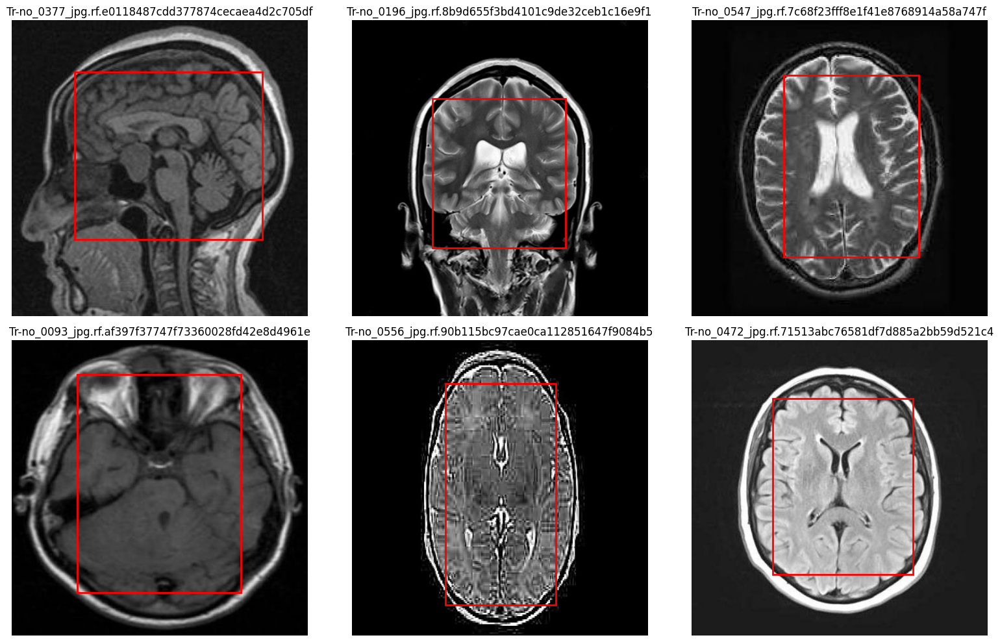

In [31]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
import random

# Load ground truth
gt = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

# Ambil data ground truth asli
gt_all = pd.read_csv(
    OUTPUT_DIR / "gt_df.csv"
)

# Class ID 2 = No Tumor
no_tumor = gt_all[
    gt_all["class_id"] == 2
].copy()

# Ambil 6 gambar secara acak
sample_images = (
    no_tumor["image"]
    .drop_duplicates()
    .sample(
        n=min(6, no_tumor["image"].nunique()),
        random_state=42
    )
    .tolist()
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, image_name in zip(axes, sample_images):

    image_path = IMAGE_DIR / f"{image_name}.jpg"

    if not image_path.exists():
        candidates = list(
            IMAGE_DIR.glob(f"{image_name}.*")
        )

        if not candidates:
            ax.set_title(f"Image not found: {image_name}")
            ax.axis("off")
            continue

        image_path = candidates[0]

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)

    boxes = no_tumor[
        no_tumor["image"] == image_name
    ]

    for _, row in boxes.iterrows():

        rect = patches.Rectangle(
            (row["x1"], row["y1"]),
            row["x2"] - row["x1"],
            row["y2"] - row["y1"],
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [32]:
import pandas as pd
import numpy as np

# Load regression dataset
df = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

# Class mapping
class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

df["class_name"] = df["class_id"].map(class_mapping)

# Pisahkan seluruh kelas dan kelas tumor
tumor_df = df[
    df["class_id"].isin([0, 1, 3])
].copy()

# Ringkasan dataset
print("SELURUH KELAS")
print("Jumlah pasangan:", len(df))
print("Jumlah gambar:", df["image"].nunique())

print("\nTUMOR-SPECIFIC")
print("Jumlah pasangan:", len(tumor_df))
print("Jumlah gambar:", tumor_df["image"].nunique())

print("\nDistribusi kelas:")
display(
    tumor_df.groupby("class_name")["IoU"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

# Simpan
tumor_df.to_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv",
    index=False
)

print("\nDataset tersimpan:", AUDIT_DIR)

SELURUH KELAS
Jumlah pasangan: 501
Jumlah gambar: 498

TUMOR-SPECIFIC
Jumlah pasangan: 404
Jumlah gambar: 401

Distribusi kelas:


,count,mean,median,std
class_name,,,,
Glioma,163,0.8315,0.8772,0.1476
Meningioma,123,0.7756,0.8023,0.1118
Pituitary,118,0.7520,0.7573,0.1033



Dataset tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [33]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load tumor-specific dataset
df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

feature_sets = {
    "M1": ["confidence"],
    "M2": ["confidence", "class_id"],
    "M3": ["confidence", "class_id", "norm_height"],
    "M4": [
        "confidence",
        "class_id",
        "norm_height",
        "aspect_ratio"
    ]
}

target = "IoU"
groups = df["image"]

gkf = GroupKFold(n_splits=5)

results = []
oof_predictions = {}

for model_name, features in feature_sets.items():

    predictions = np.zeros(len(df))

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(df, df[target], groups),
        start=1
    ):

        train_df = df.iloc[train_idx]
        test_df = df.iloc[test_idx]

        numerical_features = [
            col for col in features
            if col != "class_id"
        ]

        categorical_features = [
            col for col in features
            if col == "class_id"
        ]

        transformers = [
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                numerical_features
            )
        ]

        if categorical_features:
            transformers.append(
                (
                    "cat",
                    OneHotEncoder(handle_unknown="ignore"),
                    categorical_features
                )
            )

        preprocessor = ColumnTransformer(
            transformers=transformers
        )

        model = Pipeline([
            ("preprocessor", preprocessor),
            (
                "regressor",
                ExtraTreesRegressor(
                    n_estimators=300,
                    min_samples_leaf=3,
                    max_features=1.0,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        model.fit(
            train_df[features],
            train_df[target]
        )

        predictions[test_idx] = model.predict(
            test_df[features]
        )

    oof_predictions[model_name] = predictions

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(
            df[target], predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                df[target], predictions
            )
        ),
        "R2": r2_score(
            df[target], predictions
        )
    })

    print(f"{model_name} selesai.")

# Ringkasan hasil
tumor_results = pd.DataFrame(results)

print("\nHASIL M1-M4 TUMOR-SPECIFIC")
display(tumor_results.round(5))

# Simpan hasil
tumor_results.to_csv(
    AUDIT_DIR / "Tumor_Specific_M1_M4_Results.csv",
    index=False
)

# Simpan prediksi OOF untuk analisis berikutnya
oof_df = df[[
    "image", "class_id", "confidence", "IoU"
]].copy()

for model_name, predictions in oof_predictions.items():
    oof_df[f"Predicted_{model_name}"] = predictions

oof_df.to_csv(
    AUDIT_DIR / "Tumor_Specific_M1_M4_OOF.csv",
    index=False
)

print("\nHasil tersimpan:", AUDIT_DIR)

M1 selesai.
M2 selesai.
M3 selesai.
M4 selesai.

HASIL M1-M4 TUMOR-SPECIFIC


,Model,MAE,RMSE,R2
0,M1,0.08941,0.11752,0.17714
1,M2,0.08163,0.10977,0.28205
2,M3,0.07668,0.10554,0.33629
3,M4,0.07665,0.10418,0.35336



Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [34]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load tumor-specific dataset
df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height",
    "aspect_ratio"
]

target = "IoU"
groups = df["image"]

algorithms = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.05,
        l2_regularization=1.0,
        random_state=42
    )
}

gkf = GroupKFold(n_splits=5)

results = []

for algorithm_name, regressor in algorithms.items():

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(df, df[target], groups),
        start=1
    ):

        train_df = df.iloc[train_idx]
        test_df = df.iloc[test_idx]

        preprocessor = ColumnTransformer([
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                ["confidence", "norm_height", "aspect_ratio"]
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                ["class_id"]
            )
        ])

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", regressor)
        ])

        model.fit(
            train_df[features],
            train_df[target]
        )

        predictions = model.predict(
            test_df[features]
        )

        results.append({
            "Algorithm": algorithm_name,
            "Fold": fold,
            "MAE": mean_absolute_error(
                test_df[target], predictions
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    test_df[target], predictions
                )
            ),
            "R2": r2_score(
                test_df[target], predictions
            )
        })

        print(
            f"{algorithm_name} | Fold {fold} selesai."
        )

results_df = pd.DataFrame(results)

summary_df = (
    results_df.groupby("Algorithm")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "R2": ["mean", "std"]
    })
    .round(5)
)

print("\nPERBANDINGAN ALGORITMA M4 TUMOR-SPECIFIC")
display(summary_df)

results_df.to_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Algorithm_Comparison.csv",
    index=False
)

summary_df.to_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Algorithm_Summary.csv"
)

print("\nHasil tersimpan:", AUDIT_DIR)

Random Forest | Fold 1 selesai.
Random Forest | Fold 2 selesai.
Random Forest | Fold 3 selesai.
Random Forest | Fold 4 selesai.
Random Forest | Fold 5 selesai.
Extra Trees | Fold 1 selesai.
Extra Trees | Fold 2 selesai.
Extra Trees | Fold 3 selesai.
Extra Trees | Fold 4 selesai.
Extra Trees | Fold 5 selesai.
HistGradientBoosting | Fold 1 selesai.
HistGradientBoosting | Fold 2 selesai.
HistGradientBoosting | Fold 3 selesai.
HistGradientBoosting | Fold 4 selesai.
HistGradientBoosting | Fold 5 selesai.

PERBANDINGAN ALGORITMA M4 TUMOR-SPECIFIC


MAE              RMSE                R2         
                         mean      std     mean      std     mean      std
Algorithm                                                                 
Extra Trees           0.07667  0.00748  0.10301  0.01747  0.32558  0.10425
HistGradientBoosting  0.08252  0.00885  0.11259  0.01845  0.19622  0.08997
Random Forest         0.07823  0.00756  0.10710  0.01611  0.26832  0.10118


Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [35]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load tumor-specific data
df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height",
    "aspect_ratio"
]

target = "IoU"

X = df[features]
y = df[target]
groups = df["image"]

gkf = GroupKFold(n_splits=5)

predictions = {
    "Global Mean": np.zeros(len(df)),
    "Class Mean": np.zeros(len(df)),
    "Extra Trees M4": np.zeros(len(df))
}

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups),
    start=1
):

    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    # 1. Global Mean
    predictions["Global Mean"][test_idx] = (
        train_df[target].mean()
    )

    # 2. Class Mean
    class_means = (
        train_df.groupby("class_id")[target].mean()
    )

    predictions["Class Mean"][test_idx] = (
        test_df["class_id"]
        .map(class_means)
        .fillna(train_df[target].mean())
        .values
    )

    # 3. Extra Trees M4
    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["confidence", "norm_height", "aspect_ratio"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["class_id"]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        (
            "regressor",
            ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=3,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        train_df[features],
        train_df[target]
    )

    predictions["Extra Trees M4"][test_idx] = (
        model.predict(test_df[features])
    )

    print(f"Fold {fold} selesai.")

# Evaluasi OOF
comparison = []

for name, pred in predictions.items():

    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    })

comparison_df = pd.DataFrame(comparison)

print("\nTUMOR-SPECIFIC BASELINE COMPARISON")
display(comparison_df.round(5))

# Simpan hasil
comparison_df.to_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Baseline_Comparison.csv",
    index=False
)

# Simpan prediksi OOF
oof_df = df[["image", "class_id", "IoU"]].copy()

for name, pred in predictions.items():
    oof_df[f"Pred_{name.replace(' ', '_')}"] = pred

oof_df.to_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Baseline_OOF.csv",
    index=False
)

print("\nHasil tersimpan:", AUDIT_DIR)

Fold 1 selesai.
Fold 2 selesai.
Fold 3 selesai.
Fold 4 selesai.
Fold 5 selesai.

TUMOR-SPECIFIC BASELINE COMPARISON


,Model,MAE,RMSE,R2
0,Global Mean,0.09849,0.13007,-0.00798
1,Class Mean,0.09220,0.12603,0.05360
2,Extra Trees M4,0.07665,0.10418,0.35336



Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [36]:
import numpy as np
import pandas as pd

# Load OOF predictions
oof_df = pd.read_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Baseline_OOF.csv"
)

print("Jumlah pasangan:", len(oof_df))
print("Jumlah gambar:", oof_df["image"].nunique())

# Hitung absolute error
oof_df["Error_Class_Mean"] = (
    oof_df["IoU"] -
    oof_df["Pred_Class_Mean"]
).abs()

oof_df["Error_Extra_Trees"] = (
    oof_df["IoU"] -
    oof_df["Pred_Extra_Trees_M4"]
).abs()

# Agregasi berdasarkan gambar
image_errors = (
    oof_df.groupby("image")
    .agg(
        class_mean_error=("Error_Class_Mean", "mean"),
        extra_trees_error=("Error_Extra_Trees", "mean")
    )
)

image_errors["improvement"] = (
    image_errors["class_mean_error"] -
    image_errors["extra_trees_error"]
)

# Bootstrap berpasangan berdasarkan gambar
rng = np.random.default_rng(42)

n_bootstrap = 10000
n_images = len(image_errors)

boot_results = []

for _ in range(n_bootstrap):

    sampled_idx = rng.integers(
        0,
        n_images,
        size=n_images
    )

    sampled = image_errors.iloc[sampled_idx]

    mae_baseline = sampled["class_mean_error"].mean()
    mae_model = sampled["extra_trees_error"].mean()

    improvement = mae_baseline - mae_model

    relative_improvement = (
        improvement / mae_baseline * 100
    )

    boot_results.append([
        mae_baseline,
        mae_model,
        improvement,
        relative_improvement
    ])

boot_df = pd.DataFrame(
    boot_results,
    columns=[
        "MAE_Class_Mean",
        "MAE_Extra_Trees",
        "MAE_Improvement",
        "Improvement_Percent"
    ]
)

# Confidence interval 95%
bootstrap_summary = boot_df.quantile(
    [0.025, 0.50, 0.975]
).round(5)

print("TUMOR-SPECIFIC BOOTSTRAP 95% CI")
display(bootstrap_summary)

# Simpan
image_errors.to_csv(
    AUDIT_DIR / "Tumor_Specific_Image_Level_Errors.csv"
)

bootstrap_summary.to_csv(
    AUDIT_DIR / "Tumor_Specific_Paired_Bootstrap_CI.csv"
)

print("Hasil tersimpan:", AUDIT_DIR)

Jumlah pasangan: 404
Jumlah gambar: 401
TUMOR-SPECIFIC BOOTSTRAP 95% CI


,MAE_Class_Mean,MAE_Extra_Trees,MAE_Improvement,Improvement_Percent
0.025,0.08410,0.07020,0.00928,10.59871
0.500,0.09174,0.07665,0.01515,16.51354
0.975,0.10075,0.08380,0.02099,21.92941


Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [37]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load OOF prediction
oof_df = pd.read_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Baseline_OOF.csv"
)

# Nama kelas
class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    3: "Pituitary"
}

oof_df["Class_Name"] = (
    oof_df["class_id"].map(class_mapping)
)

# Evaluasi per kelas
class_results = []

for class_id, class_name in class_mapping.items():

    subset = oof_df[
        oof_df["class_id"] == class_id
    ]

    actual = subset["IoU"]

    predicted = subset["Pred_Extra_Trees_M4"]

    class_results.append({
        "Class": class_name,
        "N": len(subset),
        "MAE": mean_absolute_error(
            actual, predicted
        ),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),
        "Mean_Actual_IoU": actual.mean(),
        "Mean_Predicted_IoU": predicted.mean()
    })

class_results_df = pd.DataFrame(class_results)

print("TUMOR-SPECIFIC CLASS PERFORMANCE")
display(class_results_df.round(5))

class_results_df.to_csv(
    AUDIT_DIR / "Tumor_Specific_Class_Performance.csv",
    index=False
)

print("Hasil tersimpan:", AUDIT_DIR)

TUMOR-SPECIFIC CLASS PERFORMANCE


,Class,N,MAE,RMSE,R2,Mean_Actual_IoU,Mean_Predicted_IoU
0,Glioma,163,0.07781,0.11287,0.41199,0.83151,0.83431
1,Meningioma,123,0.07348,0.09357,0.29375,0.77563,0.77200
2,Pituitary,118,0.07835,0.10214,0.01338,0.75195,0.74886


Hasil tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited


In [39]:
oof_df = pd.read_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Baseline_OOF.csv"
)

print("Kolom yang tersedia:")
print(oof_df.columns.tolist())

display(oof_df.head())

Kolom yang tersedia:
['image', 'class_id', 'IoU', 'Pred_Global_Mean', 'Pred_Class_Mean', 'Pred_Extra_Trees_M4']


,image,class_id,IoU,Pred_Global_Mean,Pred_Class_Mean,Pred_Extra_Trees_M4
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.865741,0.795432,0.842017,0.813968
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.929962,0.784229,0.821282,0.892319
2,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.939502,0.790552,0.832241,0.843724
3,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,0,0.879508,0.795432,0.842017,0.834692
4,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,0,0.914690,0.792458,0.827838,0.900935


In [40]:
reg_df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

print("Kolom dataset regresi:")
print(reg_df.columns.tolist())

display(reg_df.head())

Kolom dataset regresi:
['image', 'class_id', 'confidence', 'IoU', 'pred_x1', 'pred_y1', 'pred_x2', 'pred_y2', 'gt_x1', 'gt_y1', 'gt_x2', 'gt_y2', 'box_width', 'box_height', 'norm_width', 'norm_height', 'norm_area', 'aspect_ratio', 'class_name']


,image,class_id,confidence,IoU,pred_x1,pred_y1,pred_x2,pred_y2,gt_x1,gt_y1,gt_x2,gt_y2,box_width,box_height,norm_width,norm_height,norm_area,aspect_ratio,class_name
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775954,0.865741,265.856995,324.595764,380.277649,367.769226,260.0,327.5,379.0,368.5,114.420654,43.173462,0.178782,0.067459,0.012060,2.650254,Glioma
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,319.180756,331.967041,387.229950,382.972290,318.5,332.5,387.5,385.5,68.049194,51.005249,0.106327,0.079696,0.008474,1.334161,Glioma
2,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,0.939502,313.616150,59.448212,357.638977,128.834167,314.5,61.0,357.5,130.0,44.022827,69.385956,0.068786,0.108416,0.007457,0.634463,Glioma
3,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,0,0.846112,0.879508,307.091980,289.495300,368.448059,372.983704,302.5,290.0,367.5,376.0,61.356079,83.488403,0.095869,0.130451,0.012506,0.734905,Glioma
4,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,0,0.905514,0.914690,345.142273,181.706390,480.131165,360.574615,344.5,186.0,487.5,359.0,134.988892,178.868225,0.210920,0.279482,0.058948,0.754683,Glioma


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

oof_df = pd.read_csv(
    AUDIT_DIR / "Tumor_Specific_M4_Baseline_OOF.csv"
)

reg_df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

# Periksa duplikasi
print("Jumlah baris OOF:", len(oof_df))
print(
    "Duplikasi OOF:",
    oof_df.duplicated(["image", "class_id"]).sum()
)

print("Jumlah baris regresi:", len(reg_df))
print(
    "Duplikasi regresi:",
    reg_df.duplicated(["image", "class_id"]).sum()
)

# Ambil confidence dari dataset regresi
confidence_df = reg_df[
    ["image", "class_id", "confidence"]
].copy()

# Pastikan satu pasangan image-class hanya memiliki satu confidence
confidence_df = confidence_df.drop_duplicates(
    subset=["image", "class_id"]
)

# Pertahankan semua baris OOF
df = oof_df.merge(
    confidence_df,
    on=["image", "class_id"],
    how="left",
    validate="many_to_one"
)

print("\nHasil penggabungan:")
print("Jumlah data:", len(df))
print("Confidence kosong:", df["confidence"].isna().sum())

# Nama kelas
class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    3: "Pituitary"
}

df["Class_Name"] = df["class_id"].map(class_mapping)

# Residual
df["Residual"] = (
    df["IoU"] - df["Pred_Extra_Trees_M4"]
)

df["Absolute_Error"] = df["Residual"].abs()

Jumlah baris OOF: 404
Duplikasi OOF: 3
Jumlah baris regresi: 404
Duplikasi regresi: 3

Hasil penggabungan:
Jumlah data: 404
Confidence kosong: 0


In [44]:
correlation_results = []

for class_id, class_name in class_mapping.items():

    subset = df[df["class_id"] == class_id]

    rho, p_value = spearmanr(
        subset["confidence"],
        subset["IoU"]
    )

    correlation_results.append({
        "Class": class_name,
        "N": len(subset),
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(5))

,Class,N,Spearman_Rho,P_Value
0,Glioma,163,0.51136,0.00000
1,Meningioma,123,0.47517,0.00000
2,Pituitary,118,0.33658,0.00019


In [44]:
# Periksa baris duplikat OOF
duplicate_rows = df[
    df.duplicated(
        subset=["image", "class_id"],
        keep=False
    )
].sort_values(["image", "class_id"])

display(duplicate_rows)

# Periksa apakah nilai IoU dan prediksi berbeda
display(
    duplicate_rows.groupby(
        ["image", "class_id"]
    ).agg(
        Count=("IoU", "size"),
        IoU_Unique=("IoU", "nunique"),
        Prediction_Unique=("Pred_Extra_Trees_M4", "nunique"),
        Confidence_Unique=("confidence", "nunique")
    )
)

In [45]:
duplicate_rows = df[
    df.duplicated(
        subset=["image", "class_id"],
        keep=False
    )
].sort_values(["image", "class_id"])

display(duplicate_rows[
    [
        "image",
        "class_id",
        "IoU",
        "Pred_Extra_Trees_M4",
        "confidence"
    ]
])

,image,class_id,IoU,Pred_Extra_Trees_M4,confidence
152,Tr-gl_0506_jpg.rf.51a4c03aff62f5c430ca9afaea83...,0,0.877165,0.929529,0.924412
153,Tr-gl_0506_jpg.rf.51a4c03aff62f5c430ca9afaea83...,0,0.466486,0.613414,0.924412
154,Tr-gl_0508_jpg.rf.d6ddd0bf5f12a46e268d1adf574b...,0,0.946189,0.918996,0.933614
155,Tr-gl_0508_jpg.rf.d6ddd0bf5f12a46e268d1adf574b...,0,0.938050,0.872910,0.933614
212,Tr-me_0252_jpg.rf.7730d0d8ad11ec2677b21d356c6d...,1,0.684016,0.742123,0.828434
213,Tr-me_0252_jpg.rf.7730d0d8ad11ec2677b21d356c6d...,1,0.846356,0.815695,0.828434


In [46]:
residual_summary = (
    df.groupby("Class_Name")
    .agg(
        N=("Residual", "count"),
        Mean_Residual=("Residual", "mean"),
        SD_Residual=("Residual", "std"),
        MAE=("Absolute_Error", "mean"),
        Max_Absolute_Error=("Absolute_Error", "max")
    )
)

display(residual_summary.round(5))

,N,Mean_Residual,SD_Residual,MAE,Max_Absolute_Error
Class_Name,,,,,
Glioma,163,-0.00280,0.11318,0.07781,0.60140
Meningioma,123,0.00363,0.09388,0.07348,0.28371
Pituitary,118,0.00309,0.10253,0.07835,0.39950


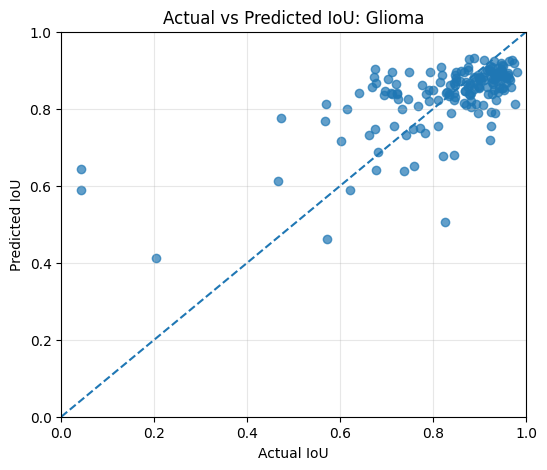

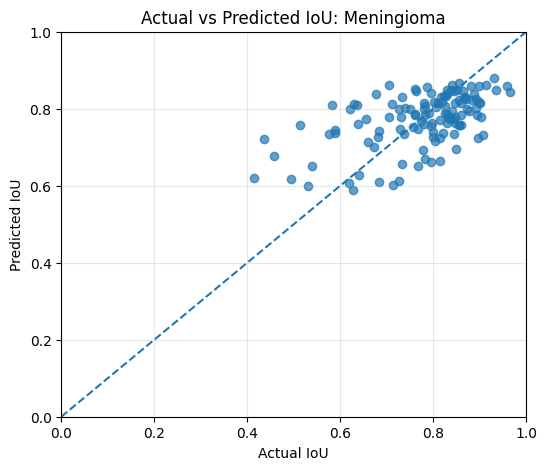

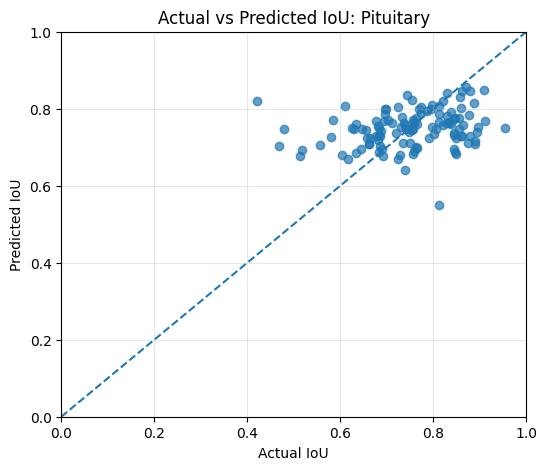

In [47]:
for class_name in ["Glioma", "Meningioma", "Pituitary"]:

    subset = df[df["Class_Name"] == class_name]

    plt.figure(figsize=(6, 5))

    plt.scatter(
        subset["IoU"],
        subset["Pred_Extra_Trees_M4"],
        alpha=0.7
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("Actual IoU")
    plt.ylabel("Predicted IoU")
    plt.title(f"Actual vs Predicted IoU: {class_name}")

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.show()

In [48]:
from pathlib import Path

TEST_IMAGE_DIR = DATASET / "test/images"
TEST_LABEL_DIR = DATASET / "test/labels"

print("TEST IMAGE DIRECTORY:", TEST_IMAGE_DIR)
print("TEST LABEL DIRECTORY:", TEST_LABEL_DIR)

test_images = []

for ext in ["*.jpg", "*.jpeg", "*.png"]:
    test_images.extend(TEST_IMAGE_DIR.glob(ext))

test_labels = list(TEST_LABEL_DIR.glob("*.txt"))

print("\nJumlah gambar test:", len(test_images))
print("Jumlah file label:", len(test_labels))

print("\nContoh gambar:")
for p in test_images[:5]:
    print(p.name)

print("\nContoh label:")
for p in test_labels[:5]:
    print(p.name)

TEST IMAGE DIRECTORY: /content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test/images
TEST LABEL DIRECTORY: /content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1/test/labels

Jumlah gambar test: 246
Jumlah file label: 246

Contoh gambar:
Tr-me_0380_jpg.rf.cee73c7527b07c233df8ed493e43a499.jpg
Tr-me_0321_jpg.rf.293afc9d48528f4b9ae3b550b4dd9edd.jpg
Tr-pi_0422_jpg.rf.d2ab544f99ae8e77800c3ec6f3d9835b.jpg
Tr-gl_0557_jpg.rf.fa1dac6024cf5c9375f14b1f152fab4f.jpg
Tr-no_0538_jpg.rf.8ce5df7bab7eafb82ed246d5d84c558b.jpg

Contoh label:
Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad3c08.txt
Tr-no_0043_jpg.rf.5224aefedc2bd0860814754ea61bb631.txt
Tr-gl_0301_jpg.rf.9e87b3d71315a64cc5b1d1562a430008.txt
Tr-no_0308_jpg.rf.e09b8408ed3772905a59c690ef227dde.txt
Tr-pi_0568_jpg.rf.71ddbc307577726d6a0b846fc72985e8.txt


In [49]:
image_stems = {p.stem for p in test_images}
label_stems = {p.stem for p in test_labels}

missing_labels = image_stems - label_stems
orphan_labels = label_stems - image_stems

print("Gambar tanpa label:", len(missing_labels))
print("Label tanpa gambar:", len(orphan_labels))

Gambar tanpa label: 0
Label tanpa gambar: 0


In [50]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import numpy as np

# Load model terbaik yang sudah dilatih
model = YOLO(str(BEST_MODEL))

# Direktori output
TEST_OUTPUT_DIR = OUTPUT_DIR / "Independent_Test"
TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Inferensi
results = model.predict(
    source=str(TEST_IMAGE_DIR),
    imgsz=640,
    conf=0.001,
    iou=0.7,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(TEST_OUTPUT_DIR),
    name="YOLOv8s_Test_Predictions",
    exist_ok=True,
    verbose=False
)

print("Jumlah gambar diproses:", len(results))
print("Lokasi hasil:", TEST_OUTPUT_DIR)

Results saved to /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/YOLOv8s_Test_Predictions
246 labels saved to /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/YOLOv8s_Test_Predictions/labels
Jumlah gambar diproses: 246
Lokasi hasil: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test


In [51]:
prediction_rows = []

for result in results:

    image_name = Path(result.path).name

    if result.boxes is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, confidence, class_id in zip(
        boxes, confidences, classes
    ):

        x1, y1, x2, y2 = box

        prediction_rows.append({
            "image": image_name,
            "class_id": class_id,
            "confidence": float(confidence),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2)
        })

test_pred_df = pd.DataFrame(prediction_rows)

pred_path = TEST_OUTPUT_DIR / "test_predictions.csv"
test_pred_df.to_csv(pred_path, index=False)

print("Total prediksi:", len(test_pred_df))
print("Jumlah gambar terdeteksi:",
      test_pred_df["image"].nunique())

display(test_pred_df.head())
print("\nFile tersimpan:", pred_path)

Total prediksi: 478
Jumlah gambar terdeteksi: 246


,image,class_id,confidence,x1,y1,x2,y2
0,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,0,0.686967,425.128448,294.455078,481.740753,335.962524
1,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,0,0.044609,462.929077,369.338654,511.028259,439.717438
2,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,1,0.002240,423.912903,293.881958,481.067200,337.751465
3,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a6...,0,0.841571,269.100769,291.455383,332.268127,370.291321
4,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a6...,0,0.002727,254.508499,250.652267,340.377991,293.160339



File tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/test_predictions.csv


In [52]:
gt_rows = []

for image_path in test_images:

    label_path = TEST_LABEL_DIR / f"{image_path.stem}.txt"

    from PIL import Image

    with Image.open(image_path) as im:
        image_width, image_height = im.size

    with open(label_path, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id, xc, yc, w, h = map(float, values)

            x1 = (xc - w / 2) * image_width
            y1 = (yc - h / 2) * image_height
            x2 = (xc + w / 2) * image_width
            y2 = (yc + h / 2) * image_height

            gt_rows.append({
                "image": image_path.name,
                "class_id": int(class_id),
                "xc": xc,
                "yc": yc,
                "w": w,
                "h": h,
                "image_width": image_width,
                "image_height": image_height,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2
            })

test_gt_df = pd.DataFrame(gt_rows)

gt_path = TEST_OUTPUT_DIR / "test_ground_truth.csv"
test_gt_df.to_csv(gt_path, index=False)

print("Total anotasi ground truth:", len(test_gt_df))
print("Jumlah kelas:")

display(
    test_gt_df["class_id"]
    .value_counts()
    .sort_index()
)

print("\nFile tersimpan:", gt_path)

Total anotasi ground truth: 250
Jumlah kelas:


,count
class_id,
0,84
1,63
2,49
3,54



File tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/test_ground_truth.csv


In [53]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import precision_score, recall_score, f1_score
from scipy.optimize import linear_sum_assignment

# Load data
TEST_OUTPUT_DIR = OUTPUT_DIR / "Independent_Test"

pred_df = pd.read_csv(
    TEST_OUTPUT_DIR / "test_predictions.csv"
)

gt_df = pd.read_csv(
    TEST_OUTPUT_DIR / "test_ground_truth.csv"
)

# IoU calculation
def calculate_iou(box1, box2):

    x_left = max(box1[0], box2[0])
    y_top = max(box1[1], box2[1])

    x_right = min(box1[2], box2[2])
    y_bottom = min(box1[3], box2[3])

    intersection = max(0, x_right - x_left) * \
                   max(0, y_bottom - y_top)

    area1 = max(0, box1[2] - box1[0]) * \
            max(0, box1[3] - box1[1])

    area2 = max(0, box2[2] - box2[0]) * \
            max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# Greedy matching per image and class
def evaluate_detection(predictions, ground_truth, iou_threshold):

    TP = FP = FN = 0

    for image in ground_truth["image"].unique():

        for class_id in sorted(ground_truth["class_id"].unique()):

            gt_subset = ground_truth[
                (ground_truth["image"] == image) &
                (ground_truth["class_id"] == class_id)
            ]

            pred_subset = predictions[
                (predictions["image"] == image) &
                (predictions["class_id"] == class_id)
            ].sort_values("confidence", ascending=False)

            gt_boxes = gt_subset[
                ["x1", "y1", "x2", "y2"]
            ].to_numpy()

            pred_boxes = pred_subset[
                ["x1", "y1", "x2", "y2"]
            ].to_numpy()

            matched_gt = set()

            for pred_box in pred_boxes:

                ious = [
                    calculate_iou(pred_box, gt_box)
                    for gt_box in gt_boxes
                ]

                if len(ious) == 0:
                    FP += 1
                    continue

                best_idx = int(np.argmax(ious))
                best_iou = ious[best_idx]

                if best_iou >= iou_threshold and best_idx not in matched_gt:
                    TP += 1
                    matched_gt.add(best_idx)
                else:
                    FP += 1

            FN += len(gt_boxes) - len(matched_gt)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "IoU_Threshold": iou_threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# Threshold fixed from validation
TEST_CONF_THRESHOLD = 0.60

test_pred_filtered = pred_df[
    pred_df["confidence"] >= TEST_CONF_THRESHOLD
].copy()

results = []

for threshold in [0.50, 0.75, 0.90]:

    results.append(
        evaluate_detection(
            test_pred_filtered,
            gt_df,
            threshold
        )
    )

detection_summary = pd.DataFrame(results)

display(detection_summary.round(5))

detection_summary.to_csv(
    TEST_OUTPUT_DIR / "Test_Detection_Evaluation.csv",
    index=False
)

print("Jumlah prediksi setelah confidence filtering:",
      len(test_pred_filtered))

,IoU_Threshold,TP,FP,FN,Precision,Recall,F1
0,0.50,228,7,22,0.97021,0.912,0.94021
1,0.75,181,54,69,0.77021,0.724,0.74639
2,0.90,72,163,178,0.30638,0.288,0.29691


Jumlah prediksi setelah confidence filtering: 235


In [54]:
pair_rows = []

for image in gt_df["image"].unique():

    for class_id in sorted(gt_df["class_id"].unique()):

        gt_subset = gt_df[
            (gt_df["image"] == image) &
            (gt_df["class_id"] == class_id)
        ].reset_index(drop=True)

        pred_subset = test_pred_filtered[
            (test_pred_filtered["image"] == image) &
            (test_pred_filtered["class_id"] == class_id)
        ].reset_index(drop=True)

        if len(gt_subset) == 0 or len(pred_subset) == 0:
            continue

        gt_boxes = gt_subset[
            ["x1", "y1", "x2", "y2"]
        ].to_numpy()

        pred_boxes = pred_subset[
            ["x1", "y1", "x2", "y2"]
        ].to_numpy()

        iou_matrix = np.zeros(
            (len(gt_boxes), len(pred_boxes))
        )

        for i, gt_box in enumerate(gt_boxes):
            for j, pred_box in enumerate(pred_boxes):
                iou_matrix[i, j] = calculate_iou(
                    gt_box, pred_box
                )

        row_ind, col_ind = linear_sum_assignment(
            -iou_matrix
        )

        for i, j in zip(row_ind, col_ind):

            iou_value = iou_matrix[i, j]

            if iou_value <= 0:
                continue

            pred = pred_subset.iloc[j]
            gt = gt_subset.iloc[i]

            width = pred["x2"] - pred["x1"]
            height = pred["y2"] - pred["y1"]

            pair_rows.append({
                "image": image,
                "class_id": int(class_id),
                "confidence": pred["confidence"],
                "IoU": iou_value,
                "norm_width": width / 640,
                "norm_height": height / 640,
                "norm_area": (width * height) / (640 * 640),
                "aspect_ratio": width / height if height > 0 else 0
            })

test_pairs_df = pd.DataFrame(pair_rows)

pair_path = TEST_OUTPUT_DIR / "test_localization_pairs.csv"

test_pairs_df.to_csv(pair_path, index=False)

print("Jumlah pasangan positif:", len(test_pairs_df))
print("Jumlah gambar dengan pasangan:",
      test_pairs_df["image"].nunique())

print("\nDistribusi pasangan per kelas:")
display(
    test_pairs_df["class_id"]
    .value_counts()
    .sort_index()
)

print("\nContoh pasangan:")
display(test_pairs_df.head())

Jumlah pasangan positif: 231
Jumlah gambar dengan pasangan: 227

Distribusi pasangan per kelas:


,count
class_id,
0,78
1,58
2,44
3,51



Contoh pasangan:


,image,class_id,confidence,IoU,norm_width,norm_height,norm_area,aspect_ratio
0,Tr-me_0380_jpg.rf.cee73c7527b07c233df8ed493e43...,1,0.867840,0.871392,0.256491,0.199200,0.051093,1.287604
1,Tr-me_0321_jpg.rf.293afc9d48528f4b9ae3b550b4dd...,1,0.875844,0.877515,0.170585,0.225992,0.038551,0.754826
2,Tr-pi_0422_jpg.rf.d2ab544f99ae8e77800c3ec6f3d9...,3,0.838983,0.615622,0.112529,0.138224,0.015554,0.814106
3,Tr-gl_0557_jpg.rf.fa1dac6024cf5c9375f14b1f152f...,0,0.877611,0.935646,0.114548,0.137253,0.015722,0.834575
4,Tr-no_0538_jpg.rf.8ce5df7bab7eafb82ed246d5d84c...,2,0.864605,0.755427,0.503185,0.564430,0.284013,0.891493


In [55]:
def evaluate_detection_corrected(predictions, ground_truth, iou_threshold):

    TP = FP = FN = 0

    for image in ground_truth["image"].unique():

        for class_id in sorted(ground_truth["class_id"].unique()):

            gt_subset = ground_truth[
                (ground_truth["image"] == image) &
                (ground_truth["class_id"] == class_id)
            ]

            pred_subset = predictions[
                (predictions["image"] == image) &
                (predictions["class_id"] == class_id)
            ].sort_values("confidence", ascending=False)

            gt_boxes = gt_subset[
                ["x1", "y1", "x2", "y2"]
            ].to_numpy()

            pred_boxes = pred_subset[
                ["x1", "y1", "x2", "y2"]
            ].to_numpy()

            matched_gt = set()

            for pred_box in pred_boxes:

                available = [
                    j for j in range(len(gt_boxes))
                    if j not in matched_gt
                ]

                if not available:
                    FP += 1
                    continue

                ious = [
                    calculate_iou(pred_box, gt_boxes[j])
                    for j in available
                ]

                best_position = int(np.argmax(ious))
                best_gt_idx = available[best_position]
                best_iou = ious[best_position]

                if best_iou >= iou_threshold:
                    TP += 1
                    matched_gt.add(best_gt_idx)
                else:
                    FP += 1

            FN += len(gt_boxes) - len(matched_gt)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "IoU_Threshold": iou_threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


corrected_results = []

for threshold in [0.50, 0.75, 0.90]:

    corrected_results.append(
        evaluate_detection_corrected(
            test_pred_filtered,
            gt_df,
            threshold
        )
    )

corrected_summary = pd.DataFrame(corrected_results)

display(corrected_summary.round(5))

corrected_summary.to_csv(
    TEST_OUTPUT_DIR / "Test_Detection_Evaluation_Corrected.csv",
    index=False
)

,IoU_Threshold,TP,FP,FN,Precision,Recall,F1
0,0.50,228,7,22,0.97021,0.912,0.94021
1,0.75,181,54,69,0.77021,0.724,0.74639
2,0.90,72,163,178,0.30638,0.288,0.29691


In [56]:
# Gunakan seluruh prediksi, tanpa filtering confidence 0.60
test_pred_all = pred_df.copy()

pair_rows_all = []

for image in gt_df["image"].unique():

    for class_id in sorted(gt_df["class_id"].unique()):

        gt_subset = gt_df[
            (gt_df["image"] == image) &
            (gt_df["class_id"] == class_id)
        ].reset_index(drop=True)

        pred_subset = test_pred_all[
            (test_pred_all["image"] == image) &
            (test_pred_all["class_id"] == class_id)
        ].reset_index(drop=True)

        if len(gt_subset) == 0 or len(pred_subset) == 0:
            continue

        gt_boxes = gt_subset[
            ["x1", "y1", "x2", "y2"]
        ].to_numpy()

        pred_boxes = pred_subset[
            ["x1", "y1", "x2", "y2"]
        ].to_numpy()

        iou_matrix = np.zeros(
            (len(gt_boxes), len(pred_boxes))
        )

        for i, gt_box in enumerate(gt_boxes):
            for j, pred_box in enumerate(pred_boxes):
                iou_matrix[i, j] = calculate_iou(
                    gt_box, pred_box
                )

        row_ind, col_ind = linear_sum_assignment(-iou_matrix)

        for i, j in zip(row_ind, col_ind):

            iou_value = iou_matrix[i, j]

            if iou_value <= 0:
                continue

            pred = pred_subset.iloc[j]

            width = pred["x2"] - pred["x1"]
            height = pred["y2"] - pred["y1"]

            pair_rows_all.append({
                "image": image,
                "class_id": int(class_id),
                "confidence": pred["confidence"],
                "IoU": iou_value,
                "norm_width": width / 640,
                "norm_height": height / 640,
                "norm_area": (width * height) / (640 * 640),
                "aspect_ratio": width / height if height > 0 else 0
            })

test_pairs_all_df = pd.DataFrame(pair_rows_all)

# Simpan semua kelas
test_pairs_all_df.to_csv(
    TEST_OUTPUT_DIR / "test_localization_pairs_all.csv",
    index=False
)

# Pisahkan tiga kelas tumor
test_tumor_pairs = test_pairs_all_df[
    test_pairs_all_df["class_id"].isin([0, 1, 3])
].copy()

test_tumor_pairs.to_csv(
    TEST_OUTPUT_DIR / "test_tumor_localization_pairs.csv",
    index=False
)

print("Total pasangan semua kelas:", len(test_pairs_all_df))
print("Total pasangan tumor:", len(test_tumor_pairs))

print("\nDistribusi pasangan tumor:")
display(
    test_tumor_pairs["class_id"]
    .value_counts()
    .sort_index()
)

print("\nStatistik confidence:")
display(
    test_tumor_pairs["confidence"].describe().round(4)
)

Total pasangan semua kelas: 245
Total pasangan tumor: 199

Distribusi pasangan tumor:


,count
class_id,
0,84
1,61
3,54



Statistik confidence:


,confidence
count,199.0000
mean,0.8047
std,0.1884
min,0.0011
25%,0.8268
50%,0.8649
75%,0.8827
max,0.9405


In [57]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =====================================
# 1. LOAD VALIDATION DATA
# =====================================

VAL_FILE = AUDIT_DIR / "tumor_specific_regression_dataset.csv"

val_df = pd.read_csv(VAL_FILE)

# =====================================
# 2. LOAD INDEPENDENT TEST DATA
# =====================================

TEST_FILE = TEST_OUTPUT_DIR / "test_tumor_localization_pairs.csv"

test_df = pd.read_csv(TEST_FILE)

# =====================================
# 3. FEATURE SELECTION
# =====================================

features = [
    "confidence",
    "class_id",
    "norm_height",
    "aspect_ratio"
]

target = "IoU"

X_train = val_df[features].copy()
y_train = val_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

# =====================================
# 4. TRAIN EXTRA TREES M4
# =====================================

model_final = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

model_final.fit(X_train, y_train)

# =====================================
# 5. PREDICTION
# =====================================

test_df["Pred_Extra_Trees_M4"] = model_final.predict(X_test)

# IoU prediction must be within [0,1]
test_df["Pred_Extra_Trees_M4"] = (
    test_df["Pred_Extra_Trees_M4"].clip(0, 1)
)

# =====================================
# 6. BASELINE COMPARISON
# =====================================

global_mean = y_train.mean()

class_means = (
    val_df.groupby("class_id")["IoU"].mean()
)

test_df["Pred_Global_Mean"] = global_mean

test_df["Pred_Class_Mean"] = (
    test_df["class_id"].map(class_means)
)

# =====================================
# 7. EVALUATION
# =====================================

def calculate_metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

models = {
    "Global Mean": "Pred_Global_Mean",
    "Class Mean": "Pred_Class_Mean",
    "Extra Trees M4": "Pred_Extra_Trees_M4"
}

results = []

for model_name, column in models.items():

    metrics = calculate_metrics(
        test_df["IoU"],
        test_df[column]
    )

    results.append({
        "Model": model_name,
        **metrics
    })

final_results = pd.DataFrame(results)

display(final_results.round(5))

# =====================================
# 8. SAVE RESULTS
# =====================================

final_results.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_RESULTS.csv",
    index=False
)

test_df.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv",
    index=False
)

print("Eksperimen final selesai.")
print("Jumlah training:", len(X_train))
print("Jumlah testing:", len(X_test))
print("Hasil tersimpan di:", TEST_OUTPUT_DIR)

,Model,MAE,RMSE,R2
0,Global Mean,0.09721,0.11516,-0.06145
1,Class Mean,0.08847,0.10509,0.11619
2,Extra Trees M4,0.07267,0.08980,0.35467


Eksperimen final selesai.
Jumlah training: 404
Jumlah testing: 199
Hasil tersimpan di: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test


In [58]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load final test predictions
test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    3: "Pituitary"
}

class_results = []

for class_id, class_name in class_mapping.items():

    subset = test_df[
        test_df["class_id"] == class_id
    ]

    y_true = subset["IoU"]
    y_pred = subset["Pred_Extra_Trees_M4"]

    class_results.append({
        "Class": class_name,
        "N": len(subset),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Mean_Actual_IoU": y_true.mean(),
        "Mean_Predicted_IoU": y_pred.mean()
    })

class_test_results = pd.DataFrame(class_results)

display(class_test_results.round(5))

class_test_results.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_CLASS_RESULTS.csv",
    index=False
)

print("Hasil evaluasi per kelas berhasil disimpan.")

,Class,N,MAE,RMSE,R2,Mean_Actual_IoU,Mean_Predicted_IoU
0,Glioma,84,0.06982,0.09028,0.14634,0.87217,0.83554
1,Meningioma,61,0.06840,0.08028,0.37208,0.80102,0.78935
2,Pituitary,54,0.08193,0.09878,0.10739,0.75649,0.74971


Hasil evaluasi per kelas berhasil disimpan.


In [59]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error

test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

# Hitung bootstrap berdasarkan image
rng = np.random.default_rng(42)

images = test_df["image"].unique()
n_bootstrap = 10000

bootstrap_results = []

for b in range(n_bootstrap):

    sampled_images = rng.choice(
        images,
        size=len(images),
        replace=True
    )

    sampled_df = pd.concat(
        [
            test_df[test_df["image"] == image]
            for image in sampled_images
        ],
        ignore_index=True
    )

    y_true = sampled_df["IoU"]

    mae_class = mean_absolute_error(
        y_true,
        sampled_df["Pred_Class_Mean"]
    )

    mae_et = mean_absolute_error(
        y_true,
        sampled_df["Pred_Extra_Trees_M4"]
    )

    rmse_class = np.sqrt(
        mean_squared_error(
            y_true,
            sampled_df["Pred_Class_Mean"]
        )
    )

    rmse_et = np.sqrt(
        mean_squared_error(
            y_true,
            sampled_df["Pred_Extra_Trees_M4"]
        )
    )

    bootstrap_results.append({
        "MAE_Improvement": mae_class - mae_et,
        "RMSE_Improvement": rmse_class - rmse_et
    })

boot_df = pd.DataFrame(bootstrap_results)

summary = pd.DataFrame({
    "Metric": ["MAE Improvement", "RMSE Improvement"],
    "Lower_95_CI": [
        boot_df["MAE_Improvement"].quantile(0.025),
        boot_df["RMSE_Improvement"].quantile(0.025)
    ],
    "Median": [
        boot_df["MAE_Improvement"].median(),
        boot_df["RMSE_Improvement"].median()
    ],
    "Upper_95_CI": [
        boot_df["MAE_Improvement"].quantile(0.975),
        boot_df["RMSE_Improvement"].quantile(0.975)
    ]
})

display(summary.round(5))

summary.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_BOOTSTRAP_CI.csv",
    index=False
)

print("Bootstrap selesai.")

,Metric,Lower_95_CI,Median,Upper_95_CI
0,MAE Improvement,0.00804,0.01582,0.02354
1,RMSE Improvement,0.00574,0.01523,0.02524


Bootstrap selesai.


OVERALL RESIDUAL ANALYSIS


,Residual
count,199.00000
mean,0.02088
std,0.08756
min,-0.21842
median,0.02930
max,0.28140


RESIDUAL PER CLASS


,N,Mean_Residual,SD_Residual,MAE,Max_Absolute_Error
Class_Name,,,,,
Glioma,84,0.03663,0.08301,0.06982,0.28140
Meningioma,61,0.01167,0.08008,0.06840,0.18694
Pituitary,54,0.00678,0.09947,0.08193,0.21842


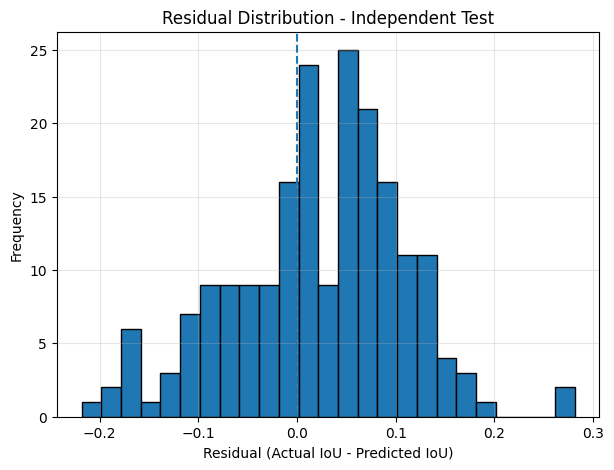

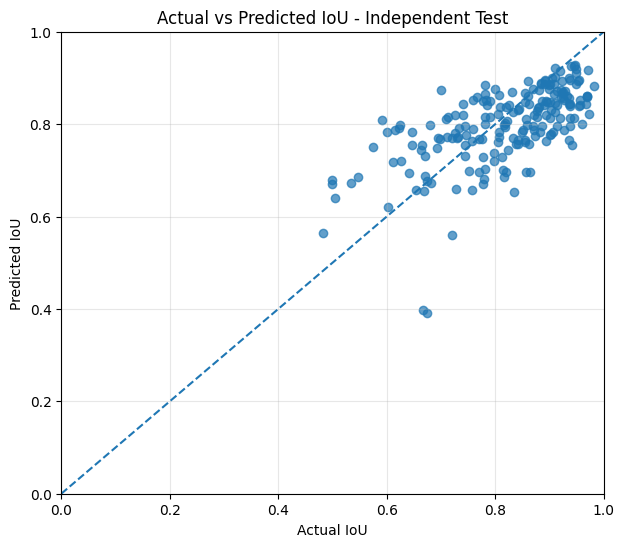

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

# Residual
test_df["Residual"] = (
    test_df["IoU"] - test_df["Pred_Extra_Trees_M4"]
)

test_df["Absolute_Error"] = (
    test_df["Residual"].abs()
)

# Statistik residual keseluruhan
print("OVERALL RESIDUAL ANALYSIS")

display(
    test_df["Residual"].agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ]).to_frame("Residual").round(5)
)

# Residual per kelas
class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    3: "Pituitary"
}

test_df["Class_Name"] = (
    test_df["class_id"].map(class_mapping)
)

print("RESIDUAL PER CLASS")

display(
    test_df.groupby("Class_Name").agg(
        N=("Residual", "count"),
        Mean_Residual=("Residual", "mean"),
        SD_Residual=("Residual", "std"),
        MAE=("Absolute_Error", "mean"),
        Max_Absolute_Error=("Absolute_Error", "max")
    ).round(5)
)

# Residual distribution
plt.figure(figsize=(7, 5))

plt.hist(
    test_df["Residual"],
    bins=25,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Residual (Actual IoU - Predicted IoU)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Independent Test")

plt.grid(alpha=0.3)
plt.show()

# Actual vs predicted
plt.figure(figsize=(7, 6))

plt.scatter(
    test_df["IoU"],
    test_df["Pred_Extra_Trees_M4"],
    alpha=0.7
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Actual IoU")
plt.ylabel("Predicted IoU")
plt.title("Actual vs Predicted IoU - Independent Test")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.show()

In [61]:
import pandas as pd
import numpy as np

from sklearn.inspection import permutation_importance
from sklearn.ensemble import ExtraTreesRegressor

# Load data validation
val_df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

# Load data test
test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

features = [
    "confidence",
    "class_id",
    "norm_height",
    "aspect_ratio"
]

# Model final
X_train = val_df[features]
y_train = val_df["IoU"]

X_test = test_df[features]
y_test = test_df["IoU"]

model_final = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

model_final.fit(X_train, y_train)

# Permutation importance
importance = permutation_importance(
    model_final,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance_Mean": importance.importances_mean,
    "Importance_SD": importance.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

display(importance_df.round(6))

importance_df.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_FEATURE_IMPORTANCE.csv",
    index=False
)

,Feature,Importance_Mean,Importance_SD
1,class_id,0.023545,0.003223
0,confidence,0.015069,0.002867
2,norm_height,0.009593,0.002785
3,aspect_ratio,-0.000304,0.000957


In [64]:
import pandas as pd
import numpy as np

# Load hasil independent test
test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

# Periksa nama kolom
print("Kolom tersedia:")
print(test_df.columns.tolist())

# Mapping kelas sesuai dataset
class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

# Tambahkan nama kelas
test_df["Class_Name"] = test_df["class_id"].map(class_mapping)

# Hitung residual
test_df["Residual"] = (
    test_df["IoU"] - test_df["Pred_Extra_Trees_M4"]
)

test_df["Absolute_Error"] = test_df["Residual"].abs()

# Analisis bias per kelas
bias_summary = test_df.groupby("Class_Name").agg(
    N=("IoU", "count"),
    Mean_Actual_IoU=("IoU", "mean"),
    Mean_Predicted_IoU=("Pred_Extra_Trees_M4", "mean"),
    Mean_Residual=("Residual", "mean"),
    MAE=("Absolute_Error", "mean"),
    SD_Residual=("Residual", "std")
).reset_index()

print("\n=== CLASS-WISE BIAS ANALYSIS ===")
display(bias_summary.round(5))

# Simpan hasil
bias_summary.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_CLASS_BIAS_ANALYSIS.csv",
    index=False
)

Kolom tersedia:
['image', 'class_id', 'confidence', 'IoU', 'norm_width', 'norm_height', 'norm_area', 'aspect_ratio', 'Pred_Extra_Trees_M4', 'Pred_Global_Mean', 'Pred_Class_Mean']

=== CLASS-WISE BIAS ANALYSIS ===


,Class_Name,N,Mean_Actual_IoU,Mean_Predicted_IoU,Mean_Residual,MAE,SD_Residual
0,Glioma,84,0.87217,0.83554,0.03663,0.06982,0.08301
1,Meningioma,61,0.80102,0.78935,0.01167,0.06840,0.08008
2,Pituitary,54,0.75649,0.74971,0.00678,0.08193,0.09947


In [65]:
import pandas as pd
from scipy.stats import spearmanr, pearsonr

test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

# Korelasi keseluruhan
rho, p_spearman = spearmanr(
    test_df["confidence"],
    test_df["IoU"]
)

r, p_pearson = pearsonr(
    test_df["confidence"],
    test_df["IoU"]
)

print("=== OVERALL CORRELATION ===")
print(f"Spearman rho : {rho:.5f}")
print(f"Spearman p   : {p_spearman:.6f}")
print(f"Pearson r    : {r:.5f}")
print(f"Pearson p    : {p_pearson:.6f}")

# Korelasi per kelas
class_mapping = {
    0: "Glioma",
    1: "Meningioma",
    3: "Pituitary"
}

test_df["Class_Name"] = test_df["class_id"].map(class_mapping)

results = []

for class_name, group in test_df.groupby("Class_Name"):
    rho, p_s = spearmanr(
        group["confidence"],
        group["IoU"]
    )

    r, p_p = pearsonr(
        group["confidence"],
        group["IoU"]
    )

    results.append({
        "Class": class_name,
        "N": len(group),
        "Spearman_Rho": rho,
        "Spearman_P": p_s,
        "Pearson_R": r,
        "Pearson_P": p_p
    })

correlation_df = pd.DataFrame(results)

print("\n=== CLASS-WISE CORRELATION ===")
display(correlation_df.round(5))

correlation_df.to_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_CONFIDENCE_IOU_CORRELATION.csv",
    index=False
)

=== OVERALL CORRELATION ===
Spearman rho : 0.46358
Spearman p   : 0.000000
Pearson r    : 0.39906
Pearson p    : 0.000000

=== CLASS-WISE CORRELATION ===


,Class,N,Spearman_Rho,Spearman_P,Pearson_R,Pearson_P
0,Glioma,84,0.55837,0.00000,0.65718,0.00000
1,Meningioma,61,0.38260,0.00234,0.25168,0.05039
2,Pituitary,54,0.33974,0.01196,0.31337,0.02103


In [66]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

y_true = test_df["IoU"]

predictions = {
    "YOLOv8 Confidence": test_df["confidence"],
    "Class Mean": test_df["Pred_Class_Mean"],
    "CC-GLQE": test_df["Pred_Extra_Trees_M4"]
}

results = []

for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Method": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(5))

comparison_df.to_csv(
    TEST_OUTPUT_DIR / "FINAL_METHOD_COMPARISON.csv",
    index=False
)

,Method,MAE,RMSE,R2
0,YOLOv8 Confidence,0.10699,0.17677,-1.50084
1,Class Mean,0.08847,0.10509,0.11619
2,CC-GLQE,0.07267,0.08980,0.35467


In [67]:
import numpy as np
import pandas as pd

test_df = pd.read_csv(
    TEST_OUTPUT_DIR / "FINAL_CC_GLQE_TEST_PREDICTIONS.csv"
)

test_df["Error_Confidence"] = (
    test_df["IoU"] - test_df["confidence"]
).abs()

test_df["Error_CC_GLQE"] = (
    test_df["IoU"] - test_df["Pred_Extra_Trees_M4"]
).abs()

# Hitung MAE per image
image_errors = test_df.groupby("image").agg(
    MAE_Confidence=("Error_Confidence", "mean"),
    MAE_CC_GLQE=("Error_CC_GLQE", "mean")
).reset_index()

# Paired bootstrap berdasarkan image
rng = np.random.default_rng(42)

n_bootstrap = 10000
improvements = []

for _ in range(n_bootstrap):
    sample_idx = rng.integers(
        0, len(image_errors), len(image_errors)
    )

    sample = image_errors.iloc[sample_idx]

    improvement = (
        sample["MAE_Confidence"].mean()
        - sample["MAE_CC_GLQE"].mean()
    )

    improvements.append(improvement)

improvements = np.array(improvements)

print("Number of images:", len(image_errors))
print(
    "Median MAE improvement:",
    round(np.median(improvements), 5)
)
print(
    "95% CI:",
    np.round(np.percentile(improvements, [2.5, 97.5]), 5)
)
print(
    "Probability improvement > 0:",
    round(np.mean(improvements > 0), 5)
)

Number of images: 195
Median MAE improvement: 0.0348
95% CI: [    0.01831      0.0537]
Probability improvement > 0: 1.0


In [68]:
import pandas as pd

# Baca dataset regresi validasi
val_df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

# Identifikasi pasangan image dan class yang berulang
duplicate_mask = val_df.duplicated(
    subset=["image", "class_id"],
    keep=False
)

duplicates = val_df.loc[duplicate_mask].sort_values(
    ["image", "class_id", "IoU"]
)

print("Jumlah seluruh baris:", len(val_df))
print("Jumlah baris duplikat:", len(duplicates))
print(
    "Jumlah kelompok image-class duplikat:",
    duplicates.groupby(["image", "class_id"]).ngroups
)

# Tampilkan informasi objek dan prediksinya
columns_to_check = [
    "image",
    "class_id",
    "confidence",
    "IoU",
    "pred_x1",
    "pred_y1",
    "pred_x2",
    "pred_y2",
    "gt_x1",
    "gt_y1",
    "gt_x2",
    "gt_y2"
]

display(
    duplicates[
        [c for c in columns_to_check if c in duplicates.columns]
    ].round(5)
)

Jumlah seluruh baris: 404
Jumlah baris duplikat: 6
Jumlah kelompok image-class duplikat: 3


,image,class_id,confidence,IoU,pred_x1,pred_y1,pred_x2,pred_y2,gt_x1,gt_y1,gt_x2,gt_y2
153,Tr-gl_0506_jpg.rf.51a4c03aff62f5c430ca9afaea83...,0,0.00592,0.46649,232.05930,362.59192,280.37454,435.87274,237.50,380.00,281.50,419.00
152,Tr-gl_0506_jpg.rf.51a4c03aff62f5c430ca9afaea83...,0,0.92441,0.87717,327.38245,233.37860,466.96735,408.27386,337.50,234.00,466.50,400.00
155,Tr-gl_0508_jpg.rf.d6ddd0bf5f12a46e268d1adf574b...,0,0.84181,0.93805,338.94806,374.94183,401.28290,435.48566,339.00,376.00,399.00,436.00
154,Tr-gl_0508_jpg.rf.d6ddd0bf5f12a46e268d1adf574b...,0,0.93361,0.94619,182.86362,255.28876,305.97983,419.70636,182.50,252.50,302.50,418.50
212,Tr-me_0252_jpg.rf.7730d0d8ad11ec2677b21d356c6d...,1,0.82843,0.68402,265.91727,70.99298,471.27054,207.05975,279.25,45.25,487.75,219.75
213,Tr-me_0252_jpg.rf.7730d0d8ad11ec2677b21d356c6d...,1,0.82709,0.84636,101.24041,319.60693,349.81085,531.08716,91.50,326.00,337.50,542.00


In [69]:
import pandas as pd

val_df = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

# Identifikasi prediksi berdasarkan koordinat bounding box
pred_key = [
    "image",
    "class_id",
    "pred_x1",
    "pred_y1",
    "pred_x2",
    "pred_y2"
]

duplicate_predictions = val_df[
    val_df.duplicated(subset=pred_key, keep=False)
].sort_values(["image", "class_id"])

print("Jumlah prediksi berulang:",
      len(duplicate_predictions))

if len(duplicate_predictions) > 0:
    display(duplicate_predictions[pred_key + ["confidence", "IoU"]])
else:
    print("Tidak ditemukan prediksi dengan koordinat identik.")

Jumlah prediksi berulang: 0
Tidak ditemukan prediksi dengan koordinat identik.


In [70]:
from pathlib import Path

print("AUDIT_DIR:", AUDIT_DIR)

for path in Path(AUDIT_DIR).rglob("*.csv"):
    print(path)

AUDIT_DIR: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/detection_evaluation_summary.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/matching_IoU_0.50.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/matching_IoU_0.75.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/matching_IoU_0.90.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/regression_pairs.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/unmatched_predictions.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/unmatched_ground_truth.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/regression_pairs_with_geometry.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIM

In [71]:
import pandas as pd

files_to_check = [
    "regression_pairs.csv",
    "regression_pairs_with_geometry.csv",
    "tumor_specific_regression_dataset.csv",
    "unmatched_predictions.csv",
    "unmatched_ground_truth.csv"
]

for filename in files_to_check:

    df = pd.read_csv(AUDIT_DIR / filename)

    print("\n" + "=" * 65)
    print("FILE:", filename)
    print("Jumlah baris:", len(df))
    print("Jumlah kolom:", len(df.columns))

    print("\nNama kolom:")
    print(df.columns.tolist())

    print("\nContoh data:")
    display(df.head(2))


FILE: regression_pairs.csv
Jumlah baris: 501
Jumlah kolom: 12

Nama kolom:
['image', 'class_id', 'confidence', 'IoU', 'pred_x1', 'pred_y1', 'pred_x2', 'pred_y2', 'gt_x1', 'gt_y1', 'gt_x2', 'gt_y2']

Contoh data:


,image,class_id,confidence,IoU,pred_x1,pred_y1,pred_x2,pred_y2,gt_x1,gt_y1,gt_x2,gt_y2
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775954,0.865741,265.856995,324.595764,380.277649,367.769226,260.0,327.5,379.0,368.5
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,319.180756,331.967041,387.229950,382.972290,318.5,332.5,387.5,385.5



FILE: regression_pairs_with_geometry.csv
Jumlah baris: 501
Jumlah kolom: 18

Nama kolom:
['image', 'class_id', 'confidence', 'IoU', 'pred_x1', 'pred_y1', 'pred_x2', 'pred_y2', 'gt_x1', 'gt_y1', 'gt_x2', 'gt_y2', 'box_width', 'box_height', 'norm_width', 'norm_height', 'norm_area', 'aspect_ratio']

Contoh data:


,image,class_id,confidence,IoU,pred_x1,pred_y1,pred_x2,pred_y2,gt_x1,gt_y1,gt_x2,gt_y2,box_width,box_height,norm_width,norm_height,norm_area,aspect_ratio
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775954,0.865741,265.856995,324.595764,380.277649,367.769226,260.0,327.5,379.0,368.5,114.420654,43.173462,0.178782,0.067459,0.012060,2.650254
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,319.180756,331.967041,387.229950,382.972290,318.5,332.5,387.5,385.5,68.049194,51.005249,0.106327,0.079696,0.008474,1.334161



FILE: tumor_specific_regression_dataset.csv
Jumlah baris: 404
Jumlah kolom: 19

Nama kolom:
['image', 'class_id', 'confidence', 'IoU', 'pred_x1', 'pred_y1', 'pred_x2', 'pred_y2', 'gt_x1', 'gt_y1', 'gt_x2', 'gt_y2', 'box_width', 'box_height', 'norm_width', 'norm_height', 'norm_area', 'aspect_ratio', 'class_name']

Contoh data:


,image,class_id,confidence,IoU,pred_x1,pred_y1,pred_x2,pred_y2,gt_x1,gt_y1,gt_x2,gt_y2,box_width,box_height,norm_width,norm_height,norm_area,aspect_ratio,class_name
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775954,0.865741,265.856995,324.595764,380.277649,367.769226,260.0,327.5,379.0,368.5,114.420654,43.173462,0.178782,0.067459,0.012060,2.650254,Glioma
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,319.180756,331.967041,387.229950,382.972290,318.5,332.5,387.5,385.5,68.049194,51.005249,0.106327,0.079696,0.008474,1.334161,Glioma



FILE: unmatched_predictions.csv
Jumlah baris: 518
Jumlah kolom: 7

Nama kolom:
['image', 'class_id', 'confidence', 'x1', 'y1', 'x2', 'y2']

Contoh data:


,image,class_id,confidence,x1,y1,x2,y2
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.003739,274.644775,318.023041,363.498535,360.908295
1,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.002380,309.320374,269.756561,359.607056,306.164825



FILE: unmatched_ground_truth.csv
Jumlah baris: 4
Jumlah kolom: 12

Nama kolom:
['image', 'class_id', 'xc', 'yc', 'w', 'h', 'image_width', 'image_height', 'x1', 'y1', 'x2', 'y2']

Contoh data:


,image,class_id,xc,yc,w,h,image_width,image_height,x1,y1,x2,y2
0,Tr-me_0188_jpg.rf.51d1fce5dda5ef0bf4055217915a...,1,0.433594,0.633594,0.153125,0.282813,640,640,228.50,315.00,326.50,496.00
1,Tr-me_0359_jpg.rf.5853939dbfd89bc00ae367d436ce...,1,0.541406,0.591406,0.464844,0.269531,640,640,197.75,292.25,495.25,464.75


In [72]:
import pandas as pd
import numpy as np

# Load seluruh file
pairs = pd.read_csv(AUDIT_DIR / "regression_pairs.csv")
geometry = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)
tumor = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)
unmatched_pred = pd.read_csv(
    AUDIT_DIR / "unmatched_predictions.csv"
)
unmatched_gt = pd.read_csv(
    AUDIT_DIR / "unmatched_ground_truth.csv"
)

# 1. Periksa distribusi kelas
print("=== DISTRIBUSI KELAS REGRESSION PAIRS ===")
print(pairs["class_id"].value_counts().sort_index())

print("\n=== DISTRIBUSI KELAS TUMOR DATASET ===")
print(tumor["class_id"].value_counts().sort_index())

print("\n=== UNMATCHED PREDICTIONS ===")
print(unmatched_pred["class_id"].value_counts().sort_index())

print("\n=== UNMATCHED GROUND TRUTH ===")
print(unmatched_gt["class_id"].value_counts().sort_index())

# 2. Periksa apakah dataset tumor benar-benar subset
# dari dataset regresi geometri
merge_check = tumor.merge(
    geometry,
    on=[
        "image", "class_id", "confidence", "IoU",
        "pred_x1", "pred_y1", "pred_x2", "pred_y2",
        "gt_x1", "gt_y1", "gt_x2", "gt_y2"
    ],
    how="left",
    indicator=True
)

print("\n=== SUBSET VALIDATION ===")
print(merge_check["_merge"].value_counts())

# 3. Periksa duplikasi pasangan prediksi-GT
pair_key = [
    "image", "class_id",
    "pred_x1", "pred_y1", "pred_x2", "pred_y2",
    "gt_x1", "gt_y1", "gt_x2", "gt_y2"
]

print(
    "\nDuplikasi pasangan:",
    pairs.duplicated(subset=pair_key).sum()
)

# 4. Periksa rentang IoU
print("\n=== IOU RANGE ===")
print(pairs["IoU"].describe())

=== DISTRIBUSI KELAS REGRESSION PAIRS ===
class_id
0    163
1    123
2     97
3    118
Name: count, dtype: int64

=== DISTRIBUSI KELAS TUMOR DATASET ===
class_id
0    163
1    123
3    118
Name: count, dtype: int64

=== UNMATCHED PREDICTIONS ===
class_id
0    253
1     51
2    153
3     61
Name: count, dtype: int64

=== UNMATCHED GROUND TRUTH ===
class_id
1    2
2    2
Name: count, dtype: int64

=== SUBSET VALIDATION ===
_merge
both          388
left_only      16
right_only      0
Name: count, dtype: int64

Duplikasi pasangan: 0

=== IOU RANGE ===
count    501.000000
mean       0.803429
std        0.123770
min        0.041718
25%        0.739384
50%        0.833195
75%        0.887952
max        0.980210
Name: IoU, dtype: float64


In [73]:
import pandas as pd
import numpy as np

pairs = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

tumor = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

key_cols = [
    "image", "class_id",
    "pred_x1", "pred_y1", "pred_x2", "pred_y2",
    "gt_x1", "gt_y1", "gt_x2", "gt_y2"
]

# Merge berdasarkan image dan class terlebih dahulu
comparison = tumor.merge(
    pairs,
    on=["image", "class_id"],
    how="left",
    suffixes=("_tumor", "_original")
)

# Hitung perbedaan nilai numerik
numeric_cols = [
    "confidence", "IoU",
    "pred_x1", "pred_y1", "pred_x2", "pred_y2",
    "gt_x1", "gt_y1", "gt_x2", "gt_y2"
]

for col in numeric_cols:
    comparison[f"diff_{col}"] = (
        comparison[f"{col}_tumor"]
        - comparison[f"{col}_original"]
    ).abs()

# Tampilkan baris yang tidak cocok persis
exact_check = tumor.merge(
    pairs[key_cols],
    on=key_cols,
    how="left",
    indicator=True
)

unmatched_rows = exact_check[
    exact_check["_merge"] == "left_only"
]

print("Jumlah baris tidak cocok:", len(unmatched_rows))

display(
    unmatched_rows[
        ["image", "class_id", "confidence", "IoU"]
    ]
)

print("\nJumlah image berbeda:")
print(unmatched_rows["image"].nunique())

Jumlah baris tidak cocok: 16


,image,class_id,confidence,IoU
4,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,0,0.905514,0.914690
44,Tr-gl_0123_jpg.rf.9d9f5d055b1e519033a08a4e6882...,0,0.924843,0.929866
66,Tr-gl_0200_jpg.rf.693cd511964a3a1887333638f40a...,0,0.282032,0.674612
68,Tr-gl_0203_jpg.rf.b32a14e793e3ad3c9356aa38f29a...,0,0.911052,0.921670
75,Tr-gl_0219_jpg.rf.6f887e27e4861d579f4e8601c83a...,0,0.851737,0.915405
80,Tr-gl_0245_jpg.rf.808e58cedd79711db379b4c5a21e...,0,0.904310,0.942716
86,Tr-gl_0252_jpg.rf.e4418068dc02dc02f209448b2632...,0,0.627862,0.772418
92,Tr-gl_0310_jpg.rf.55b2520296336ec2735cb44f5650...,0,0.849895,0.874951
124,Tr-gl_0406_jpg.rf.84338178fb782d538d8df645d48a...,0,0.765727,0.745494
125,Tr-gl_0411_jpg.rf.3c3b74fd8d205503162d1e740114...,0,0.845831,0.826553



Jumlah image berbeda:
16


In [74]:
import pandas as pd
import numpy as np

original = pd.read_csv(
    AUDIT_DIR / "regression_pairs_with_geometry.csv"
)

tumor = pd.read_csv(
    AUDIT_DIR / "tumor_specific_regression_dataset.csv"
)

coord_cols = [
    "pred_x1", "pred_y1",
    "pred_x2", "pred_y2",
    "gt_x1", "gt_y1",
    "gt_x2", "gt_y2"
]

results = []

for idx, row in tumor.iterrows():

    candidates = original[
        (original["image"] == row["image"]) &
        (original["class_id"] == row["class_id"])
    ]

    if candidates.empty:
        results.append({
            "Index": idx,
            "Image": row["image"],
            "Class": row["class_id"],
            "Max_Coord_Diff": np.nan,
            "Confidence_Diff": np.nan,
            "IoU_Diff": np.nan,
            "Status": "NO_CANDIDATE"
        })
        continue

    differences = (
        candidates[coord_cols]
        .sub(row[coord_cols])
        .abs()
    )

    # Pilih kandidat dengan total selisih koordinat terkecil
    best_idx = differences.sum(axis=1).idxmin()
    best = candidates.loc[best_idx]

    max_diff = differences.loc[best_idx].max()

    conf_diff = abs(
        row["confidence"] - best["confidence"]
    )

    iou_diff = abs(
        row["IoU"] - best["IoU"]
    )

    if (
        max_diff < 1e-4
        and conf_diff < 1e-6
        and iou_diff < 1e-6
    ):
        status = "MATCH_WITH_TOLERANCE"
    else:
        status = "REVIEW_REQUIRED"

    results.append({
        "Index": idx,
        "Image": row["image"],
        "Class": row["class_id"],
        "Max_Coord_Diff": max_diff,
        "Confidence_Diff": conf_diff,
        "IoU_Diff": iou_diff,
        "Status": status
    })

audit_df = pd.DataFrame(results)

print("=== AUDIT SUMMARY ===")
print(audit_df["Status"].value_counts())

print("\n=== ROWS REQUIRING REVIEW ===")
display(
    audit_df[
        audit_df["Status"] != "MATCH_WITH_TOLERANCE"
    ].round(8)
)

print("\n=== MAXIMUM DIFFERENCES ===")
print(
    audit_df[
        ["Max_Coord_Diff", "Confidence_Diff", "IoU_Diff"]
    ].max()
)

=== AUDIT SUMMARY ===
Status
MATCH_WITH_TOLERANCE    404
Name: count, dtype: int64

=== ROWS REQUIRING REVIEW ===


,Index,Image,Class,Max_Coord_Diff,Confidence_Diff,IoU_Diff,Status



=== MAXIMUM DIFFERENCES ===
Max_Coord_Diff     2.842171e-14
Confidence_Diff    0.000000e+00
IoU_Diff           0.000000e+00
dtype: float64


In [75]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/CLEAR-MRI")

keywords = [
    "prediction",
    "ground_truth",
    "groundtruth",
    "validation",
    "valid"
]

print("=== FILE TERKAIT VALIDATION ===")

for path in BASE.rglob("*"):
    if path.is_file() and path.suffix.lower() in [".csv", ".txt"]:
        if any(k in path.name.lower() for k in keywords):
            print(path)

=== FILE TERKAIT VALIDATION ===
/content/drive/MyDrive/CLEAR-MRI/OOF_Calibration_Predictions.csv
/content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Confidence_Calibration/Validation_Calibration_Raw.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/unmatched_predictions.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited/unmatched_ground_truth.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/test_predictions.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/test_ground_truth.csv
/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Independent_Test/FINAL_CC_GLQE_TEST_PREDICTIONS.csv


In [76]:
import pandas as pd

files = [
    "/content/drive/MyDrive/CLEAR-MRI/OOF_Calibration_Predictions.csv",
    "/content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Confidence_Calibration/Validation_Calibration_Raw.csv"
]

for file in files:
    df = pd.read_csv(file)

    print("\n" + "=" * 60)
    print("FILE:", file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(5))


FILE: /content/drive/MyDrive/CLEAR-MRI/OOF_Calibration_Predictions.csv
Shape: (3057, 9)
Columns: ['repetition', 'seed', 'fold', 'image', 'class_name', 'correct', 'confidence', 'global_pred', 'classwise_pred']


,repetition,seed,fold,image,class_name,correct,confidence,global_pred,classwise_pred
0,1,42,1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,1,0.775953,0.901239,0.918706
1,1,42,1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0,0.003739,0.000429,0.000361
2,1,42,1,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,Glioma,1,0.905514,0.975789,0.981440
3,1,42,1,Tr-gl_0051_jpg.rf.b04f3a9b9f83a6167a021b5cc846...,Glioma,1,0.895204,0.971491,0.977982
4,1,42,1,Tr-gl_0057_jpg.rf.00db06a404574ba14346d9a5416f...,Glioma,1,0.754020,0.884211,0.903769



FILE: /content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Confidence_Calibration/Validation_Calibration_Raw.csv
Shape: (1019, 5)
Columns: ['image', 'class_name', 'confidence', 'correct', 'IoU']


,image,class_name,confidence,correct,IoU
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.775953,1,0.865742
1,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,Glioma,0.003739,0,0.000000
2,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,Glioma,0.839568,1,0.929962
3,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.841803,1,0.939502
4,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,Glioma,0.002380,0,0.000000


In [77]:
import pandas as pd

raw_path = "/content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Confidence_Calibration/Validation_Calibration_Raw.csv"
raw = pd.read_csv(raw_path)

print("TOTAL PREDICTIONS:", len(raw))
print("\nDistribusi correct:")
print(raw["correct"].value_counts(dropna=False))

print("\nDistribusi class dan correct:")
print(pd.crosstab(raw["class_name"], raw["correct"], margins=True))

print("\nStatistik IoU:")
print(raw["IoU"].describe())

print("\nPemeriksaan konsistensi:")
print("correct = 1 tetapi IoU = 0:",
      ((raw["correct"] == 1) & (raw["IoU"] == 0)).sum())

print("correct = 0 tetapi IoU > 0:",
      ((raw["correct"] == 0) & (raw["IoU"] > 0)).sum())

print("Jumlah prediksi dengan IoU = 0:",
      (raw["IoU"] == 0).sum())

print("\nJumlah baris duplikat seluruh kolom:",
      raw.duplicated().sum())

TOTAL PREDICTIONS: 1019

Distribusi correct:
correct
0    530
1    489
Name: count, dtype: int64

Distribusi class dan correct:
correct       0    1   All
class_name                
Glioma      258  158   416
Meningioma   55  119   174
No Tumor    153   97   250
Pituitary    64  115   179
All         530  489  1019

Statistik IoU:
count    1019.000000
mean        0.396223
std         0.408024
min         0.000000
25%         0.000000
50%         0.041899
75%         0.829570
max         0.980210
Name: IoU, dtype: float64

Pemeriksaan konsistensi:
correct = 1 tetapi IoU = 0: 0
correct = 0 tetapi IoU > 0: 25
Jumlah prediksi dengan IoU = 0: 505

Jumlah baris duplikat seluruh kolom: 0


In [78]:
import pandas as pd
import numpy as np

raw_path = "/content/drive/MyDrive/CLEAR-MRI/06_ANALYSIS/Confidence_Calibration/Validation_Calibration_Raw.csv"
raw = pd.read_csv(raw_path)

print("DISTRIBUSI IoU PADA correct = 0")
print(raw.loc[raw["correct"] == 0, "IoU"].describe())

print("\nDISTRIBUSI IoU PADA correct = 1")
print(raw.loc[raw["correct"] == 1, "IoU"].describe())

print("\nJUMLAH PREDIKSI BERDASARKAN AMBANG IoU")
for threshold in [0, 0.1, 0.25, 0.5, 0.75]:
    count = (raw["IoU"] >= threshold).sum()
    print(f"IoU >= {threshold:.2f}: {count}")

print("\nPERBANDINGAN correct DENGAN AMBANG IoU")
for threshold in [0.25, 0.5, 0.75]:
    predicted_correct = raw["IoU"] >= threshold
    agreement = (predicted_correct == (raw["correct"] == 1)).mean()
    print(f"Threshold {threshold:.2f}: agreement = {agreement:.4f}")

print("\n25 PREDIKSI correct=0 DENGAN IoU POSITIF")
display(
    raw.loc[
        (raw["correct"] == 0) & (raw["IoU"] > 0)
    ].sort_values("IoU", ascending=False).head(30)
)

DISTRIBUSI IoU PADA correct = 0
count    530.000000
mean       0.014335
std        0.074617
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.493306
Name: IoU, dtype: float64

DISTRIBUSI IoU PADA correct = 1
count    489.000000
mean       0.810130
std        0.105836
min        0.512490
25%        0.739693
50%        0.834753
75%        0.888414
max        0.980210
Name: IoU, dtype: float64

JUMLAH PREDIKSI BERDASARKAN AMBANG IoU
IoU >= 0.00: 1019
IoU >= 0.10: 508
IoU >= 0.25: 504
IoU >= 0.50: 489
IoU >= 0.75: 358

PERBANDINGAN correct DENGAN AMBANG IoU
Threshold 0.25: agreement = 0.9853
Threshold 0.50: agreement = 1.0000
Threshold 0.75: agreement = 0.8714

25 PREDIKSI correct=0 DENGAN IoU POSITIF


,image,class_name,confidence,correct,IoU
532,Tr-me_0299_jpg.rf.1935ac6cce7fa6df2cbdf959fd16...,Meningioma,0.811495,0,0.493306
994,Tr-pi_0511_jpg.rf.8bfe8ab51759449a4c01f8d81831...,Pituitary,0.778671,0,0.479497
24,Tr-gl_0036_jpg.rf.d2c4e7f0d9af61e05f019c568bf7...,Glioma,0.741556,0,0.472959
878,Tr-pi_0087_jpg.rf.06fe1c2ccce4b65ae011f7a6c2ad...,Pituitary,0.797075,0,0.467925
375,Tr-gl_0506_jpg.rf.51a4c03aff62f5c430ca9afaea83...,Glioma,0.005921,0,0.466486
968,Tr-pi_0441_jpg.rf.bf11393e821366bec3daf6a65c22...,Pituitary,0.347169,0,0.464835
614,Tr-me_0496_jpg.rf.945d09ef257db9891d5f63a58ef0...,Meningioma,0.649884,0,0.457313
522,Tr-me_0284_jpg.rf.1cf74297cd54b5d975f56a89bd53...,Meningioma,0.732542,0,0.436875
744,Tr-no_0232_jpg.rf.7abd1c5305368f537e869f3049ce...,No Tumor,0.749708,0,0.436790
934,Tr-pi_0310_jpg.rf.6a7af3a7e47e29504b29815e7e25...,Pituitary,0.830363,0,0.421758


In [79]:
import pandas as pd
import numpy as np
from scipy.optimize import linear_sum_assignment

BASE = "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Baseline_Audited"

pairs = pd.read_csv(f"{BASE}/regression_pairs.csv")
unmatched_pred = pd.read_csv(f"{BASE}/unmatched_predictions.csv")
unmatched_gt = pd.read_csv(f"{BASE}/unmatched_ground_truth.csv")

# Rekonstruksi seluruh prediksi
matched_pred = pairs[
    ["image", "class_id", "confidence",
     "pred_x1", "pred_y1", "pred_x2", "pred_y2"]
].copy()

matched_pred.columns = [
    "image", "class_id", "confidence",
    "x1", "y1", "x2", "y2"
]

all_pred = pd.concat(
    [matched_pred, unmatched_pred],
    ignore_index=True
)

# Rekonstruksi seluruh ground truth
matched_gt = pairs[
    ["image", "class_id",
     "gt_x1", "gt_y1", "gt_x2", "gt_y2"]
].copy()

matched_gt.columns = [
    "image", "class_id", "x1", "y1", "x2", "y2"
]

all_gt = pd.concat(
    [
        matched_gt,
        unmatched_gt[
            ["image", "class_id", "x1", "y1", "x2", "y2"]
        ]
    ],
    ignore_index=True
)

print("Jumlah prediksi:", len(all_pred))
print("Jumlah ground truth:", len(all_gt))
print("Jumlah pasangan awal:", len(pairs))

# Fungsi IoU
def calculate_iou(box1, box2):
    xA = max(box1[0], box2[0])
    yA = max(box1[1], box2[1])
    xB = min(box1[2], box2[2])
    yB = min(box1[3], box2[3])

    inter = max(0, xB-xA) * max(0, yB-yA)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - inter
    return inter / union if union > 0 else 0

# Hungarian matching per image dan class
recomputed = []

for (image, cls), p in all_pred.groupby(["image", "class_id"]):
    g = all_gt[
        (all_gt["image"] == image) &
        (all_gt["class_id"] == cls)
    ]

    if len(g) == 0:
        continue

    p_boxes = p[["x1", "y1", "x2", "y2"]].to_numpy()
    g_boxes = g[["x1", "y1", "x2", "y2"]].to_numpy()

    iou_matrix = np.zeros((len(p_boxes), len(g_boxes)))

    for i in range(len(p_boxes)):
        for j in range(len(g_boxes)):
            iou_matrix[i, j] = calculate_iou(
                p_boxes[i], g_boxes[j]
            )

    row_ind, col_ind = linear_sum_assignment(-iou_matrix)

    for i, j in zip(row_ind, col_ind):
        if iou_matrix[i, j] > 0:
            recomputed.append({
                "image": image,
                "class_id": cls,
                "confidence": p.iloc[i]["confidence"],
                "IoU_recomputed": iou_matrix[i, j],
                "pred_x1": p.iloc[i]["x1"],
                "pred_y1": p.iloc[i]["y1"],
                "pred_x2": p.iloc[i]["x2"],
                "pred_y2": p.iloc[i]["y2"],
                "gt_x1": g.iloc[j]["x1"],
                "gt_y1": g.iloc[j]["y1"],
                "gt_x2": g.iloc[j]["x2"],
                "gt_y2": g.iloc[j]["y2"]
            })

recomputed = pd.DataFrame(recomputed)

print("\nHASIL REKONSTRUKSI")
print("Jumlah pasangan hasil Hungarian:", len(recomputed))
print("Jumlah pasangan awal:", len(pairs))

print("\nDistribusi IoU hasil rekonstruksi:")
print(recomputed["IoU_recomputed"].describe())

display(recomputed.head())

Jumlah prediksi: 1019
Jumlah ground truth: 505
Jumlah pasangan awal: 501

HASIL REKONSTRUKSI
Jumlah pasangan hasil Hungarian: 501
Jumlah pasangan awal: 501

Distribusi IoU hasil rekonstruksi:
count    501.000000
mean       0.803429
std        0.123770
min        0.041718
25%        0.739384
50%        0.833195
75%        0.887952
max        0.980210
Name: IoU_recomputed, dtype: float64


,image,class_id,confidence,IoU_recomputed,pred_x1,pred_y1,pred_x2,pred_y2,gt_x1,gt_y1,gt_x2,gt_y2
0,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,0,0.775954,0.865741,265.856995,324.595764,380.277649,367.769226,260.0,327.5,379.0,368.5
1,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,0,0.839568,0.929962,319.180756,331.967041,387.229950,382.972290,318.5,332.5,387.5,385.5
2,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,0,0.841803,0.939502,313.616150,59.448212,357.638977,128.834167,314.5,61.0,357.5,130.0
3,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,0,0.846112,0.879508,307.091980,289.495300,368.448059,372.983704,302.5,290.0,367.5,376.0
4,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,0,0.905514,0.914690,345.142273,181.706390,480.131165,360.574615,344.5,186.0,487.5,359.0


In [80]:
import numpy as np
import pandas as pd

original = pairs.copy()
new = recomputed.copy()

keys = [
    "image", "class_id",
    "pred_x1", "pred_y1", "pred_x2", "pred_y2",
    "gt_x1", "gt_y1", "gt_x2", "gt_y2"
]

# Urutkan agar pasangan dapat dibandingkan
original = original.sort_values(
    ["image", "class_id", "pred_x1", "pred_y1"]
).reset_index(drop=True)

new = new.sort_values(
    ["image", "class_id", "pred_x1", "pred_y1"]
).reset_index(drop=True)

print("Jumlah baris sama:", len(original) == len(new))

for col in keys:
    if col in ["image", "class_id"]:
        same = original[col].astype(str).equals(
            new[col].astype(str)
        )
    else:
        same = np.allclose(
            original[col].to_numpy(),
            new[col].to_numpy(),
            atol=1e-6
        )

    print(f"{col}: {'SAMA' if same else 'BERBEDA'}")

print(
    "\nIoU sama:",
    np.allclose(
        original["IoU"].to_numpy(),
        new["IoU_recomputed"].to_numpy(),
        atol=1e-6
    )
)

Jumlah baris sama: True
image: SAMA
class_id: SAMA
pred_x1: SAMA
pred_y1: SAMA
pred_x2: SAMA
pred_y2: SAMA
gt_x1: SAMA
gt_y1: SAMA
gt_x2: SAMA
gt_y2: SAMA

IoU sama: True


In [81]:
from pathlib import Path

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1"
)

splits = {
    "train": DATASET / "train/images",
    "valid": DATASET / "valid/images",
    "test": DATASET / "test/images"
}

image_sets = {}

for split, folder in splits.items():
    files = {
        p.name for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    }
    image_sets[split] = files
    print(f"{split}: {len(files)} gambar")

print("\nPEMERIKSAAN OVERLAP")
for a, b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    overlap = image_sets[a] & image_sets[b]
    print(f"{a} vs {b}: {len(overlap)} gambar sama")
    if overlap:
        print("Contoh:", list(overlap)[:5])

print("\nTOTAL GAMBAR UNIK:", len(set.union(*image_sets.values())))

train: 1695 gambar
valid: 502 gambar
test: 246 gambar

PEMERIKSAAN OVERLAP
train vs valid: 0 gambar sama
train vs test: 0 gambar sama
valid vs test: 0 gambar sama

TOTAL GAMBAR UNIK: 2443


In [82]:
# ============================================================
# NEAR-DUPLICATE AUDIT: PERCEPTUAL HASH (pHash)
# ============================================================

!pip -q install ImageHash

from pathlib import Path
from PIL import Image, ImageOps
import imagehash
import pandas as pd
import numpy as np
from itertools import combinations
from tqdm.auto import tqdm

# Lokasi dataset
DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/"
    "Labeled-MRI-Brain-Tumor-Dataset-1"
)

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/"
    "Near_Duplicate_Audit"
)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = {
    "train": DATASET / "train/images",
    "valid": DATASET / "valid/images",
    "test": DATASET / "test/images"
}

# ------------------------------------------------------------
# 1. Menghitung pHash seluruh gambar
# ------------------------------------------------------------

records = []

for split, folder in SPLITS.items():

    files = sorted([
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ])

    print(f"Memproses {split}: {len(files)} gambar")

    for path in tqdm(files, desc=split):

        try:
            with Image.open(path) as img:
                img = ImageOps.exif_transpose(img).convert("L")
                phash = imagehash.phash(img, hash_size=8)

            records.append({
                "split": split,
                "image": path.name,
                "path": str(path),
                "phash": int(str(phash), 16)
            })

        except Exception as e:
            print("Gagal:", path.name, str(e))

hash_df = pd.DataFrame(records)

print("\nTotal gambar berhasil diproses:", len(hash_df))

# ------------------------------------------------------------
# 2. Membandingkan pHash antar-split
# ------------------------------------------------------------

results = []

comparisons = [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]

for split_a, split_b in comparisons:

    A = hash_df[hash_df["split"] == split_a].reset_index(drop=True)
    B = hash_df[hash_df["split"] == split_b].reset_index(drop=True)

    print(f"\nMembandingkan {split_a} vs {split_b}")

    for i, row_a in tqdm(A.iterrows(), total=len(A)):

        hash_a = int(row_a["phash"])

        for j, row_b in B.iterrows():

            hash_b = int(row_b["phash"])
            distance = (hash_a ^ hash_b).bit_count()

            results.append({
                "split_a": split_a,
                "image_a": row_a["image"],
                "split_b": split_b,
                "image_b": row_b["image"],
                "hamming_distance": distance
            })

result_df = pd.DataFrame(results)

# Simpan seluruh hasil perbandingan
result_df.to_csv(
    AUDIT_DIR / "All_Cross_Split_pHash_Comparisons.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Ringkasan kandidat berdasarkan threshold
# ------------------------------------------------------------

print("\nRINGKASAN KANDIDAT NEAR-DUPLICATE")

for threshold in [0, 2, 4, 6, 8, 10]:

    print(f"\nHamming distance <= {threshold}")

    for split_a, split_b in comparisons:

        subset = result_df[
            (result_df["split_a"] == split_a) &
            (result_df["split_b"] == split_b) &
            (result_df["hamming_distance"] <= threshold)
        ]

        print(f"{split_a} vs {split_b}: {len(subset)} pasangan")

# Simpan kandidat dengan threshold <= 10
candidates = result_df[
    result_df["hamming_distance"] <= 10
].sort_values("hamming_distance")

candidates.to_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv",
    index=False
)

print("\nFile audit tersimpan di:", AUDIT_DIR)
print("\n10 kandidat paling mirip:")
display(candidates.head(10))

Memproses train: 1695 gambar


train:   0%|          | 0/1695 [00:00<?, ?it/s]

Memproses valid: 502 gambar


valid:   0%|          | 0/502 [00:00<?, ?it/s]

Memproses test: 246 gambar


test:   0%|          | 0/246 [00:00<?, ?it/s]

... (4 outputs left out)


Membandingkan valid vs test


  0%|          | 0/502 [00:00<?, ?it/s]


RINGKASAN KANDIDAT NEAR-DUPLICATE

Hamming distance <= 0
train vs valid: 32 pasangan
train vs test: 17 pasangan
valid vs test: 3 pasangan

Hamming distance <= 2
train vs valid: 84 pasangan
train vs test: 41 pasangan
valid vs test: 12 pasangan

Hamming distance <= 4
train vs valid: 210 pasangan
train vs test: 109 pasangan
valid vs test: 24 pasangan

Hamming distance <= 6
train vs valid: 420 pasangan
train vs test: 213 pasangan
valid vs test: 59 pasangan

Hamming distance <= 8
train vs valid: 802 pasangan
train vs test: 418 pasangan
valid vs test: 121 pasangan

Hamming distance <= 10
train vs valid: 1738 pasangan
train vs test: 842 pasangan
valid vs test: 256 pasangan

File audit tersimpan di: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit

10 kandidat paling mirip:


,split_a,image_a,split_b,image_b,hamming_distance
1346279,valid,Tr-no_0166_jpg.rf.7d3dabdbbdc50d7be0f2af7f43b2...,test,Tr-no_0550_jpg.rf.961727cb5c596daea01f27b939b7...,0
27658,train,Tr-gl_0062_jpg.rf.cba5b245f2bbf273efcd7f5b394a...,valid,Tr-gl_0138_jpg.rf.e8214f03282d69d7d7f0dfe48b89...,0
39720,train,Tr-gl_0086_jpg.rf.abf910f6581ceaf93a9bbea322ea...,valid,Tr-gl_0178_jpg.rf.5e171245ad03ef1fe2f563aaad85...,0
41821,train,Tr-gl_0088_jpg.rf.c10bd9703e67b944ce75cf6b933a...,valid,Tr-gl_0533_jpg.rf.2cd5068dcdaf73625fc5378335a6...,0
37761,train,Tr-gl_0082_jpg.rf.09bd70356dc06019c2393eccc461...,valid,Tr-gl_0375_jpg.rf.122db6215f7270b1c5ba89ee1e28...,0
558010,train,Tr-no_0340_jpg.rf.220686e46d6194124e32a9591976...,valid,Tr-no_0046_jpg.rf.79d003a8dae73cb11bf0be828f6a...,0
36754,train,Tr-gl_0078_jpg.rf.eabc2d473e3c783e6a50e5af730e...,valid,Tr-gl_0343_jpg.rf.b937fff65894b876e9bbaf7ca93e...,0
57368,train,Tr-gl_0115_jpg.rf.f449fe2b0bcc21ffa6439411af3e...,valid,Tr-gl_0469_jpg.rf.e16e21390b152a8e75885cb4842b...,0
564058,train,Tr-no_0367_jpg.rf.246a0dd0ef8df385ae5f3b8a420a...,valid,Tr-no_0134_jpg.rf.ffc56070a78f4c16226701f78713...,0
517373,train,Tr-no_0199_jpg.rf.65f27d1fb8acef7a857aeb4b8e1c...,valid,Tr-no_0142_jpg.rf.e799e05d5f2622e368b1d5da3379...,0


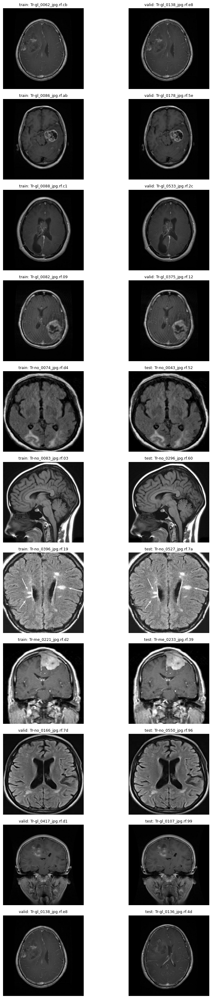

In [83]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/"
    "04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/"
    "01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

df = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv"
)

# Pilih pasangan pHash identik
identical_hash = df[df["hamming_distance"] == 0]

selected = []

for split_a, split_b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    subset = identical_hash[
        (identical_hash["split_a"] == split_a) &
        (identical_hash["split_b"] == split_b)
    ]

    selected.append(subset.head(4))

selected = pd.concat(selected, ignore_index=True)

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(10, 3 * len(selected))
)

for i, row in selected.iterrows():

    path_a = (
        DATASET / row["split_a"] /
        "images" / row["image_a"]
    )

    path_b = (
        DATASET / row["split_b"] /
        "images" / row["image_b"]
    )

    with Image.open(path_a) as img:
        axes[i, 0].imshow(img.convert("L"), cmap="gray")

    with Image.open(path_b) as img:
        axes[i, 1].imshow(img.convert("L"), cmap="gray")

    axes[i, 0].set_title(
        f'{row["split_a"]}: {row["image_a"][:20]}',
        fontsize=9
    )

    axes[i, 1].set_title(
        f'{row["split_b"]}: {row["image_b"][:20]}',
        fontsize=9
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [84]:
import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import math

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

df = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv"
)

# Ambil seluruh pasangan dengan pHash identik
df = df[df["hamming_distance"] == 0].copy()

print("Jumlah pasangan:", len(df))

# Membuat contact sheet
thumb_w = 240
thumb_h = 240
label_h = 65
columns = 2
rows_per_page = 6

for page in range(math.ceil(len(df) / rows_per_page)):

    subset = df.iloc[
        page * rows_per_page:
        (page + 1) * rows_per_page
    ]

    canvas = Image.new(
        "RGB",
        (columns * thumb_w, rows_per_page * (thumb_h + label_h)),
        "white"
    )

    draw = ImageDraw.Draw(canvas)

    for idx, (_, row) in enumerate(subset.iterrows()):

        path_a = (
            DATASET / row["split_a"] /
            "images" / row["image_a"]
        )

        path_b = (
            DATASET / row["split_b"] /
            "images" / row["image_b"]
        )

        img_a = Image.open(path_a).convert("L")
        img_b = Image.open(path_b).convert("L")

        img_a.thumbnail((thumb_w, thumb_h))
        img_b.thumbnail((thumb_w, thumb_h))

        y = idx * (thumb_h + label_h)

        x_a = 0
        x_b = thumb_w

        canvas.paste(img_a.convert("RGB"), (x_a, y))
        canvas.paste(img_b.convert("RGB"), (x_b, y))

        draw.text(
            (x_a + 5, y + thumb_h + 5),
            f'{row["split_a"]}: {row["image_a"][:28]}',
            fill="black"
        )

        draw.text(
            (x_b + 5, y + thumb_h + 5),
            f'{row["split_b"]}: {row["image_b"][:28]}',
            fill="black"
        )

    output = AUDIT_DIR / f"pHash_Identical_Page_{page+1}.jpg"
    canvas.save(output, quality=95)

    print("Tersimpan:", output)

Jumlah pasangan: 52
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_1.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_2.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_3.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_4.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_5.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_6.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical_Page_7.jpg
Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/pHash_Identical


HALAMAN 1


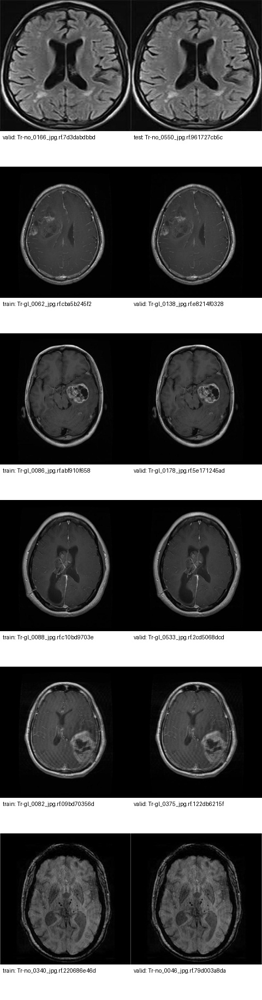


HALAMAN 2


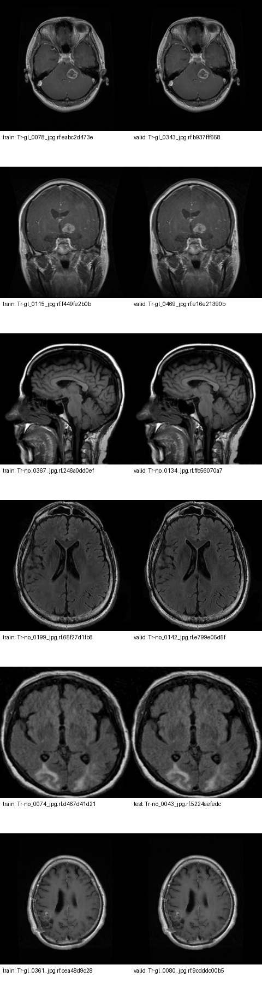


HALAMAN 3


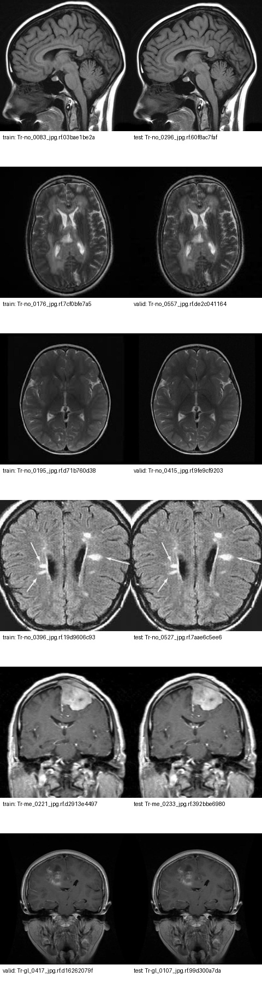

In [85]:
from PIL import Image
from IPython.display import display
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

for i in range(1, 4):
    path = AUDIT_DIR / f"pHash_Identical_Page_{i}.jpg"

    print(f"\nHALAMAN {i}")
    display(Image.open(path))

In [86]:
!pip -q install scikit-image

import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image, ImageOps
from skimage.metrics import structural_similarity as ssim

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

df = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv"
)

# Fokus pada pHash identik yang melibatkan test
df = df[
    (df["hamming_distance"] == 0) &
    (
        (df["split_a"] == "test") |
        (df["split_b"] == "test")
    )
].copy()

def load_image(path, size=(256, 256)):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img).convert("L")
    img = img.resize(size, Image.Resampling.LANCZOS)
    return np.asarray(img, dtype=np.uint8)

results = []

for _, row in df.iterrows():

    path_a = DATASET / row["split_a"] / "images" / row["image_a"]
    path_b = DATASET / row["split_b"] / "images" / row["image_b"]

    img_a = load_image(path_a)
    img_b = load_image(path_b)

    score = ssim(img_a, img_b, data_range=255)

    results.append({
        "split_a": row["split_a"],
        "image_a": row["image_a"],
        "split_b": row["split_b"],
        "image_b": row["image_b"],
        "pHash_distance": row["hamming_distance"],
        "SSIM": score
    })

ssim_df = pd.DataFrame(results)
ssim_df = ssim_df.sort_values("SSIM", ascending=False)

print("JUMLAH PASANGAN:", len(ssim_df))
print("\nHASIL SSIM:")
display(ssim_df)

print("\nKATEGORI SSIM:")
for threshold in [0.95, 0.98, 0.99]:
    print(
        f"SSIM >= {threshold}:",
        (ssim_df["SSIM"] >= threshold).sum()
    )

ssim_df.to_csv(
    AUDIT_DIR / "Test_Near_Duplicate_SSIM_Audit.csv",
    index=False
)

JUMLAH PASANGAN: 20

HASIL SSIM:


,split_a,image_a,split_b,image_b,pHash_distance,SSIM
19,train,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,test,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.994345
10,train,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,test,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.990722
14,train,Tr-gl_0107_jpg.rf.0b28a07528a965bb72803a204a02...,test,Tr-gl_0417_jpg.rf.5b07d6e9a8546e45afebaf7bc2bd...,0,0.990448
5,valid,Tr-gl_0417_jpg.rf.d16262079fa5b6f2fd62cd23d5b3...,test,Tr-gl_0107_jpg.rf.99d300a7dac557a867ea2f33c111...,0,0.990433
16,train,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,test,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.990017
12,train,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,test,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.989647
9,train,Tr-gl_0371_jpg.rf.9217e4b114a5ae55de8327fb8970...,test,Tr-gl_0081_jpg.rf.cd6ff4a250465f60361ab931fe2c...,0,0.989077
17,train,Tr-gl_0113_jpg.rf.0ba49df9ea54d80d0e6e740382e4...,test,Tr-gl_0450_jpg.rf.6f5fdffaede01c3b1d195b18bee7...,0,0.988866
11,train,Tr-gl_0063_jpg.rf.5406e15c3e54bd4d49d92eb52026...,test,Tr-gl_0154_jpg.rf.4b3cd239f7611bdc94efd7faa554...,0,0.988829
8,train,Tr-gl_0312_jpg.rf.1383439af0161e29a269769bdce2...,test,Tr-gl_0075_jpg.rf.687ed8298bed6c85cb35c9c8f3ec...,0,0.984323



KATEGORI SSIM:
SSIM >= 0.95: 15
SSIM >= 0.98: 12
SSIM >= 0.99: 5


In [87]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image, ImageOps
from skimage.metrics import structural_similarity
from skimage.metrics import normalized_root_mse

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

df = pd.read_csv(
    AUDIT_DIR / "Test_Near_Duplicate_SSIM_Audit.csv"
)

df = df[df["SSIM"] >= 0.98].copy()

results = []

for _, row in df.iterrows():

    path_a = DATASET / row["split_a"] / "images" / row["image_a"]
    path_b = DATASET / row["split_b"] / "images" / row["image_b"]

    with Image.open(path_a) as im:
        original_size_a = im.size
        a = ImageOps.exif_transpose(im).convert("L")

    with Image.open(path_b) as im:
        original_size_b = im.size
        b = ImageOps.exif_transpose(im).convert("L")

    # Samakan ukuran untuk pemeriksaan
    target_size = (512, 512)

    a = np.asarray(
        a.resize(target_size, Image.Resampling.LANCZOS),
        dtype=np.float32
    )

    b = np.asarray(
        b.resize(target_size, Image.Resampling.LANCZOS),
        dtype=np.float32
    )

    mae = np.mean(np.abs(a - b))

    corr = np.corrcoef(
        a.flatten(), b.flatten()
    )[0, 1]

    ssim_512 = structural_similarity(
        a, b, data_range=255
    )

    nrmse = normalized_root_mse(a, b)

    results.append({
        "split_a": row["split_a"],
        "image_a": row["image_a"],
        "split_b": row["split_b"],
        "image_b": row["image_b"],
        "size_a": str(original_size_a),
        "size_b": str(original_size_b),
        "SSIM_256": row["SSIM"],
        "SSIM_512": ssim_512,
        "MAE": mae,
        "NCC": corr,
        "NRMSE": nrmse
    })

audit_pixel = pd.DataFrame(results)

audit_pixel = audit_pixel.sort_values(
    "SSIM_512", ascending=False
)

display(audit_pixel)

audit_pixel.to_csv(
    AUDIT_DIR / "High_Similarity_Pixel_Audit.csv",
    index=False
)

print("\nFile tersimpan:", AUDIT_DIR / "High_Similarity_Pixel_Audit.csv")

,split_a,image_a,split_b,image_b,size_a,size_b,SSIM_256,SSIM_512,MAE,NCC,NRMSE
0,train,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,test,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,"(640, 640)","(640, 640)",0.994345,0.988959,1.235767,0.999678,0.018269
4,train,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,test,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,"(640, 640)","(640, 640)",0.990017,0.987036,0.611767,0.999588,0.024907
1,train,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,test,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,"(640, 640)","(640, 640)",0.990722,0.986638,0.674736,0.999475,0.027921
5,train,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,test,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,"(640, 640)","(640, 640)",0.989647,0.986021,0.659435,0.999235,0.032186
2,train,Tr-gl_0107_jpg.rf.0b28a07528a965bb72803a204a02...,test,Tr-gl_0417_jpg.rf.5b07d6e9a8546e45afebaf7bc2bd...,"(640, 640)","(640, 640)",0.990448,0.985701,0.789459,0.999518,0.024316
3,valid,Tr-gl_0417_jpg.rf.d16262079fa5b6f2fd62cd23d5b3...,test,Tr-gl_0107_jpg.rf.99d300a7dac557a867ea2f33c111...,"(640, 640)","(640, 640)",0.990433,0.985682,0.790531,0.999517,0.024484
8,train,Tr-gl_0063_jpg.rf.5406e15c3e54bd4d49d92eb52026...,test,Tr-gl_0154_jpg.rf.4b3cd239f7611bdc94efd7faa554...,"(640, 640)","(640, 640)",0.988829,0.985479,0.675976,0.999401,0.028542
6,train,Tr-gl_0371_jpg.rf.9217e4b114a5ae55de8327fb8970...,test,Tr-gl_0081_jpg.rf.cd6ff4a250465f60361ab931fe2c...,"(640, 640)","(640, 640)",0.989077,0.984821,0.706017,0.999488,0.027308
7,train,Tr-gl_0113_jpg.rf.0ba49df9ea54d80d0e6e740382e4...,test,Tr-gl_0450_jpg.rf.6f5fdffaede01c3b1d195b18bee7...,"(640, 640)","(640, 640)",0.988866,0.983586,0.863571,0.999426,0.025656
9,train,Tr-gl_0312_jpg.rf.1383439af0161e29a269769bdce2...,test,Tr-gl_0075_jpg.rf.687ed8298bed6c85cb35c9c8f3ec...,"(640, 640)","(640, 640)",0.984323,0.981083,0.640762,0.999538,0.027321



File tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/High_Similarity_Pixel_Audit.csv


In [88]:
import pandas as pd
import numpy as np
from PIL import Image, ImageOps
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

df = pd.read_csv(
    AUDIT_DIR / "High_Similarity_Pixel_Audit.csv"
)

results = []

for _, row in df.iterrows():

    path_a = DATASET / row["split_a"] / "images" / row["image_a"]
    path_b = DATASET / row["split_b"] / "images" / row["image_b"]

    with Image.open(path_a) as im:
        a = np.asarray(
            ImageOps.exif_transpose(im).convert("L")
        )

    with Image.open(path_b) as im:
        b = np.asarray(
            ImageOps.exif_transpose(im).convert("L")
        )

    if a.shape != b.shape:
        continue

    diff = np.abs(
        a.astype(np.int16) - b.astype(np.int16)
    )

    results.append({
        "image_a": row["image_a"],
        "image_b": row["image_b"],
        "split_a": row["split_a"],
        "split_b": row["split_b"],
        "pixel_identical_pct": np.mean(diff == 0) * 100,
        "MAE_original": np.mean(diff),
        "max_pixel_difference": np.max(diff),
        "NCC_original": np.corrcoef(
            a.flatten(), b.flatten()
        )[0, 1]
    })

original_audit = pd.DataFrame(results)

display(
    original_audit.sort_values(
        "pixel_identical_pct",
        ascending=False
    )
)

original_audit.to_csv(
    AUDIT_DIR / "Original_Pixel_Comparison.csv",
    index=False
)

print("\nTersimpan:", AUDIT_DIR / "Original_Pixel_Comparison.csv")

,image_a,image_b,split_a,split_b,pixel_identical_pct,MAE_original,max_pixel_difference,NCC_original
1,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,train,test,59.029785,0.613030,11,0.999583
2,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,train,test,56.843262,0.680125,14,0.999452
3,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,train,test,56.552979,0.661956,12,0.999213
6,Tr-gl_0063_jpg.rf.5406e15c3e54bd4d49d92eb52026...,Tr-gl_0154_jpg.rf.4b3cd239f7611bdc94efd7faa554...,train,test,56.068848,0.675034,10,0.999391
9,Tr-gl_0312_jpg.rf.1383439af0161e29a269769bdce2...,Tr-gl_0075_jpg.rf.687ed8298bed6c85cb35c9c8f3ec...,train,test,55.413086,0.642634,14,0.999524
7,Tr-gl_0371_jpg.rf.9217e4b114a5ae55de8327fb8970...,Tr-gl_0081_jpg.rf.cd6ff4a250465f60361ab931fe2c...,train,test,55.111328,0.708611,12,0.999473
4,Tr-gl_0107_jpg.rf.0b28a07528a965bb72803a204a02...,Tr-gl_0417_jpg.rf.5b07d6e9a8546e45afebaf7bc2bd...,train,test,48.982666,0.788540,11,0.999511
5,Tr-gl_0417_jpg.rf.d16262079fa5b6f2fd62cd23d5b3...,Tr-gl_0107_jpg.rf.99d300a7dac557a867ea2f33c111...,valid,test,48.920898,0.789443,11,0.999510
8,Tr-gl_0113_jpg.rf.0ba49df9ea54d80d0e6e740382e4...,Tr-gl_0450_jpg.rf.6f5fdffaede01c3b1d195b18bee7...,train,test,45.628662,0.859954,17,0.999416
10,Tr-no_0166_jpg.rf.7d3dabdbbdc50d7be0f2af7f43b2...,Tr-no_0550_jpg.rf.961727cb5c596daea01f27b939b7...,valid,test,19.684326,2.161570,25,0.998076



Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/Original_Pixel_Comparison.csv


In [89]:
import pandas as pd
import networkx as nx
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

df = pd.read_csv(
    AUDIT_DIR / "All_Cross_Split_pHash_Comparisons.csv"
)

# Kandidat dengan pHash <= 4
candidates = df[df["hamming_distance"] <= 4].copy()

G = nx.Graph()

for _, row in candidates.iterrows():

    node_a = f'{row["split_a"]}/{row["image_a"]}'
    node_b = f'{row["split_b"]}/{row["image_b"]}'

    G.add_edge(
        node_a,
        node_b,
        distance=row["hamming_distance"]
    )

# Membentuk connected components
components = [
    component for component in nx.connected_components(G)
    if len(component) > 1
]

groups = []

for group_id, component in enumerate(components, start=1):

    for node in component:

        split, image = node.split("/", 1)

        groups.append({
            "group_id": group_id,
            "split": split,
            "image": image
        })

groups_df = pd.DataFrame(groups)

groups_df.to_csv(
    AUDIT_DIR / "Near_Duplicate_Groups_pHash4.csv",
    index=False
)

print("Jumlah kelompok:", len(components))
print("Jumlah gambar dalam kelompok:", len(groups_df))

print("\nDistribusi gambar per split:")
print(pd.crosstab(groups_df["group_id"], groups_df["split"]))

print("\nAnggota kelompok:")
display(
    groups_df.sort_values(["group_id", "split"])
)

print("\nTersimpan:", AUDIT_DIR / "Near_Duplicate_Groups_pHash4.csv")

Jumlah kelompok: 208
Jumlah gambar dalam kelompok: 536

Distribusi gambar per split:
split     test  train  valid
group_id                    
1            0      1      1
2            3      8      1
3            1      6      1
4            0      2      1
5            0      1      1
...        ...    ...    ...
204          1      0      1
205          1      0      1
206          1      0      1
207          1      0      1
208          1      0      1

[208 rows x 3 columns]

Anggota kelompok:


,group_id,split,image
1,1,train,Tr-gl_0060_jpg.rf.196731c0214fbc9b0952087a00a6...
0,1,valid,Tr-gl_0123_jpg.rf.9d9f5d055b1e519033a08a4e6882...
3,2,test,Tr-no_0355_jpg.rf.5b2f13daeaaf08ae40f02be713a6...
8,2,test,Tr-me_0044_jpg.rf.0223369274dd825d3ff27ace105f...
13,2,test,Tr-me_0041_jpg.rf.fd18fa5bcabe05b6cdd3987743a4...
...,...,...,...
531,206,valid,Tr-no_0469_jpg.rf.46ce973d9b35dc9ac63f1bc4ab39...
532,207,test,Tr-pi_0134_jpg.rf.fe52bea9481b28a403f0436ab88d...
533,207,valid,Tr-pi_0123_jpg.rf.b5481d3e9afaa4986bddbf5a20c4...
534,208,test,Tr-pi_0287_jpg.rf.3b0aa682458a6c64747485ac8fb2...



Tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/Near_Duplicate_Groups_pHash4.csv


In [90]:
import pandas as pd
import networkx as nx
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

groups = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Groups_pHash4.csv"
)

edges = pd.read_csv(
    AUDIT_DIR / "All_Cross_Split_pHash_Comparisons.csv"
)

# Kandidat pHash <= 4
edges = edges[edges["hamming_distance"] <= 4].copy()

# Statistik ukuran kelompok
group_size = groups.groupby("group_id").agg(
    total_images=("image", "count"),
    total_splits=("split", "nunique"),
    splits=("split", lambda x: ", ".join(sorted(set(x)))),
    classes=("image", lambda x: ", ".join(
        sorted(set(i.split("_")[1] for i in x))
    ))
).reset_index()

print("DISTRIBUSI UKURAN KELOMPOK")
print(group_size["total_images"].value_counts().sort_index())

print("\nKELOMPOK DENGAN LEBIH DARI 5 GAMBAR")
display(
    group_size[group_size["total_images"] > 5]
    .sort_values("total_images", ascending=False)
)

print("\nKELOMPOK YANG MELIBATKAN KETIGA SPLIT")
display(
    group_size[group_size["total_splits"] == 3]
)

# Periksa distribusi jarak pHash dalam setiap kelompok
G = nx.Graph()

for _, row in edges.iterrows():
    a = f'{row["split_a"]}/{row["image_a"]}'
    b = f'{row["split_b"]}/{row["image_b"]}'
    G.add_edge(a, b, distance=row["hamming_distance"])

components = list(nx.connected_components(G))

edge_stats = []

for gid, component in enumerate(components, start=1):
    subgraph = G.subgraph(component)
    distances = [
        data["distance"]
        for _, _, data in subgraph.edges(data=True)
    ]

    edge_stats.append({
        "group_id": gid,
        "nodes": len(component),
        "edges": len(distances),
        "mean_hamming": sum(distances)/len(distances),
        "max_hamming": max(distances),
        "min_hamming": min(distances)
    })

edge_stats = pd.DataFrame(edge_stats)

print("\nSTATISTIK JARINGAN KEMIRIPAN")
display(
    edge_stats.sort_values("nodes", ascending=False).head(20)
)

group_size.to_csv(
    AUDIT_DIR / "Group_Size_Analysis.csv",
    index=False
)

edge_stats.to_csv(
    AUDIT_DIR / "Group_Edge_Analysis.csv",
    index=False
)

DISTRIBUSI UKURAN KELOMPOK
total_images
2     136
3      48
4      15
5       3
6       3
7       1
8       1
12      1
Name: count, dtype: int64

KELOMPOK DENGAN LEBIH DARI 5 GAMBAR


,group_id,total_images,total_splits,splits,classes
1,2,12,3,"test, train, valid","0040, 0041, 0042, 0044, 0045, 0062, 0134, 0136..."
2,3,8,3,"test, train, valid","0062, 0134, 0135, 0136, 0137, 0138, 0139, 0389"
27,28,7,2,"train, valid","0066, 0213, 0214, 0215, 0216, 0217, 0218"
115,116,6,2,"train, valid","0173, 0174, 0175, 0176, 0179, 0180"
117,118,6,3,"test, train, valid","0190, 0191, 0192, 0193, 0194, 0195"
185,186,6,2,"test, train","0207, 0208, 0209, 0210, 0391, 0538"



KELOMPOK YANG MELIBATKAN KETIGA SPLIT


,group_id,total_images,total_splits,splits,classes
1,2,12,3,"test, train, valid","0040, 0041, 0042, 0044, 0045, 0062, 0134, 0136..."
2,3,8,3,"test, train, valid","0062, 0134, 0135, 0136, 0137, 0138, 0139, 0389"
24,25,5,3,"test, train, valid","0199, 0204, 0205, 0414, 0415"
31,32,4,3,"test, train, valid","0258, 0259, 0260, 0261"
36,37,4,3,"test, train, valid","0313, 0314, 0315, 0316"
46,47,4,3,"test, train, valid","0084, 0119, 0165, 0416"
74,75,4,3,"test, train, valid","0161, 0162, 0355, 0356"
91,92,3,3,"test, train, valid","0055, 0080, 0313"
117,118,6,3,"test, train, valid","0190, 0191, 0192, 0193, 0194, 0195"
122,123,3,3,"test, train, valid","0313, 0314, 0315"



STATISTIK JARINGAN KEMIRIPAN


,group_id,nodes,edges,mean_hamming,max_hamming,min_hamming
1,2,12,12,3.500000,4,2
2,3,8,13,2.461538,4,0
27,28,7,7,3.428571,4,2
117,118,6,7,4.000000,4,4
115,116,6,5,4.000000,4,4
185,186,6,5,3.600000,4,2
24,25,5,4,4.000000,4,4
8,9,5,4,2.500000,4,0
84,85,5,4,2.000000,4,0
36,37,4,5,3.200000,4,2



GROUP 1: 2 gambar


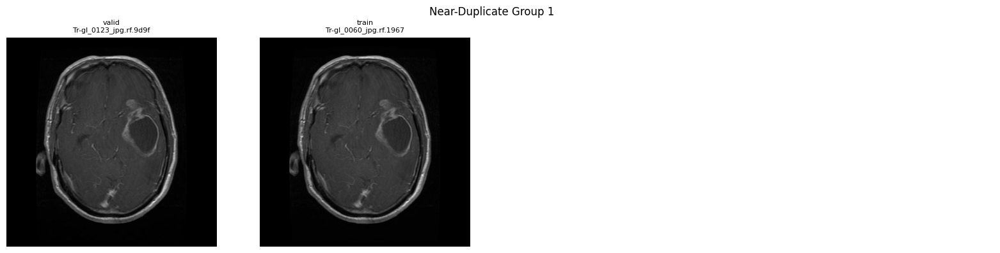


GROUP 2: 12 gambar


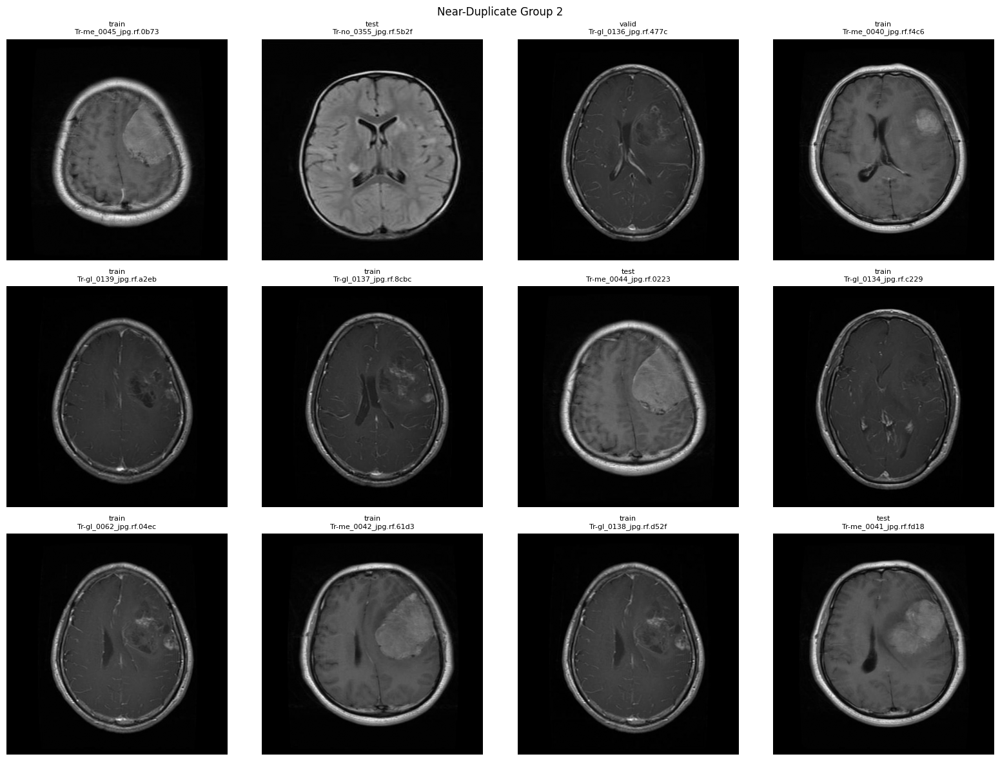


GROUP 117: 3 gambar


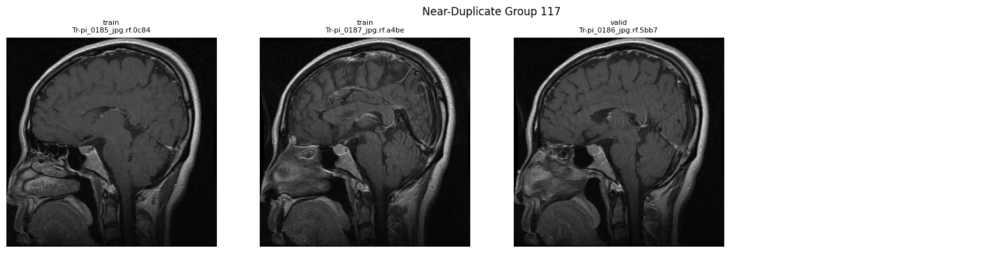


GROUP 186: 6 gambar


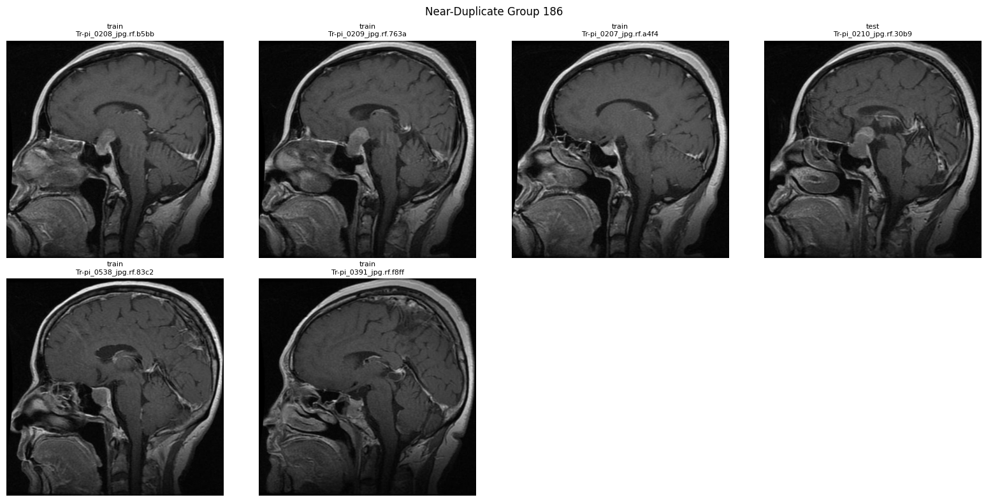


GROUP 28: 7 gambar


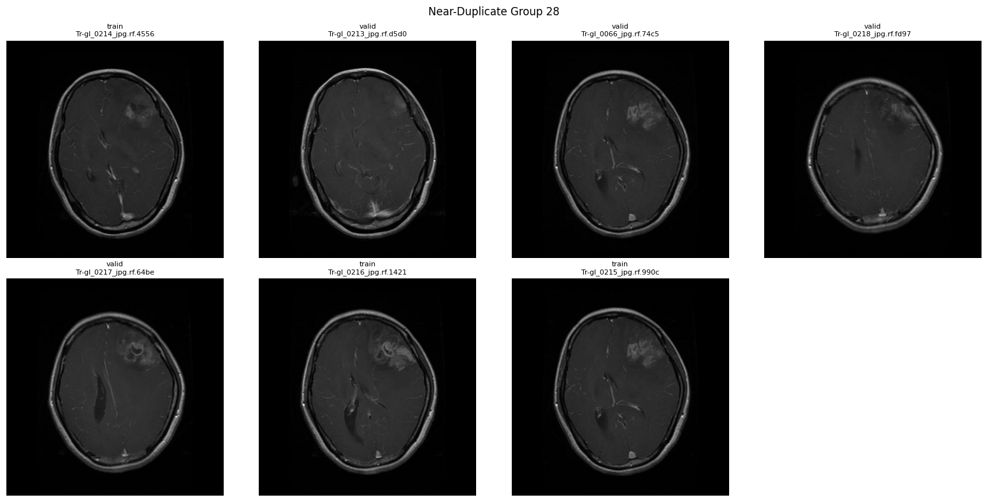


GROUP 116: 6 gambar


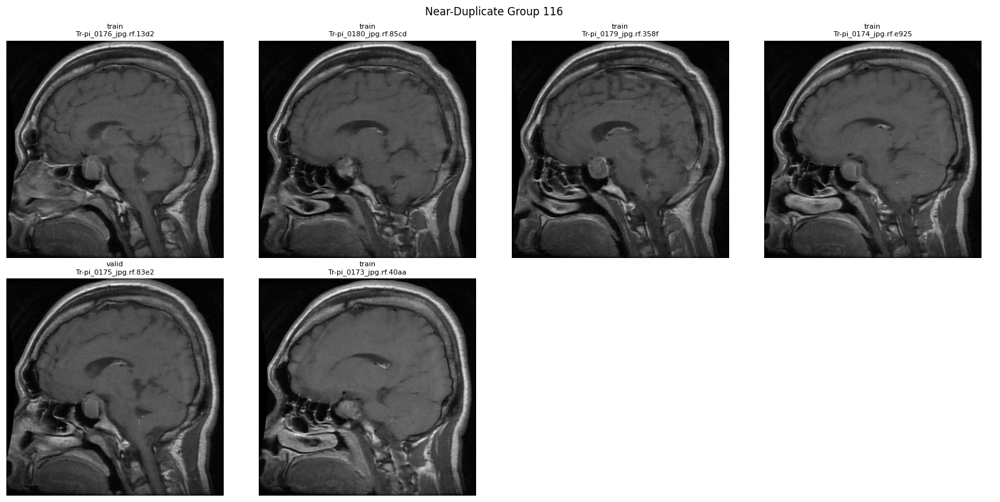

In [91]:
import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
import math

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

groups = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Groups_pHash4.csv"
)

# Kelompok besar yang diprioritaskan
target_groups = [1, 2, 117, 186, 28, 116]

for gid in target_groups:

    subset = groups[groups["group_id"] == gid]

    print(f"\nGROUP {gid}: {len(subset)} gambar")

    n = len(subset)
    cols = 4
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(16, 4 * rows)
    )

    axes = axes.flatten()

    for ax, (_, row) in zip(axes, subset.iterrows()):

        path = (
            DATASET / row["split"] /
            "images" / row["image"]
        )

        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img).convert("L")
            ax.imshow(img, cmap="gray")

        ax.set_title(
            f'{row["split"]}\n{row["image"][:22]}',
            fontsize=8
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.suptitle(f"Near-Duplicate Group {gid}")
    plt.tight_layout()
    plt.show()

In [92]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image, ImageOps
from skimage.metrics import structural_similarity as ssim

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

edges = pd.read_csv(
    AUDIT_DIR / "All_Cross_Split_pHash_Comparisons.csv"
)

# Fokus Train-Test
pairs = edges[
    (edges["split_a"] == "train") &
    (edges["split_b"] == "test") &
    (edges["hamming_distance"] <= 4)
].copy()

results = []

for _, row in pairs.iterrows():

    path_a = DATASET / "train/images" / row["image_a"]
    path_b = DATASET / "test/images" / row["image_b"]

    with Image.open(path_a) as im:
        a = np.asarray(
            ImageOps.exif_transpose(im).convert("L"),
            dtype=np.uint8
        )

    with Image.open(path_b) as im:
        b = np.asarray(
            ImageOps.exif_transpose(im).convert("L"),
            dtype=np.uint8
        )

    if a.shape != b.shape:
        b_img = Image.fromarray(b).resize(
            (a.shape[1], a.shape[0]),
            Image.Resampling.LANCZOS
        )
        b = np.asarray(b_img)

    ssim_value = ssim(a, b, data_range=255)

    ncc = np.corrcoef(
        a.flatten().astype(float),
        b.flatten().astype(float)
    )[0, 1]

    mae = np.mean(
        np.abs(a.astype(float) - b.astype(float))
    )

    results.append({
        "train_image": row["image_a"],
        "test_image": row["image_b"],
        "pHash_distance": row["hamming_distance"],
        "SSIM": ssim_value,
        "NCC": ncc,
        "MAE": mae
    })

audit = pd.DataFrame(results).sort_values(
    ["SSIM", "NCC"],
    ascending=False
)

display(audit.head(30))

print("\nJumlah pasangan diperiksa:", len(audit))
print("SSIM >= 0.98:", (audit["SSIM"] >= 0.98).sum())
print("SSIM >= 0.95:", (audit["SSIM"] >= 0.95).sum())

audit.to_csv(
    AUDIT_DIR / "Direct_Train_Test_Pair_Audit.csv",
    index=False
)

,train_image,test_image,pHash_distance,SSIM,NCC,MAE
70,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.987295,0.999624,1.277068
19,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.986288,0.999583,0.613030
23,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.985612,0.999452,0.680125
3,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.985319,0.999213,0.661956
7,Tr-gl_0120_jpg.rf.a649cdc38ba8e9dc4be7e7150f56...,Tr-gl_0517_jpg.rf.2297fd67191bb4fe70145cb9dab1...,4,0.984990,0.999313,0.722068
2,Tr-gl_0063_jpg.rf.5406e15c3e54bd4d49d92eb52026...,Tr-gl_0154_jpg.rf.4b3cd239f7611bdc94efd7faa554...,0,0.984710,0.999391,0.675034
5,Tr-gl_0107_jpg.rf.0b28a07528a965bb72803a204a02...,Tr-gl_0417_jpg.rf.5b07d6e9a8546e45afebaf7bc2bd...,0,0.984483,0.999511,0.788540
36,Tr-gl_0371_jpg.rf.9217e4b114a5ae55de8327fb8970...,Tr-gl_0081_jpg.rf.cd6ff4a250465f60361ab931fe2c...,0,0.983771,0.999473,0.708611
6,Tr-gl_0113_jpg.rf.0ba49df9ea54d80d0e6e740382e4...,Tr-gl_0450_jpg.rf.6f5fdffaede01c3b1d195b18bee7...,0,0.982417,0.999416,0.859954
33,Tr-gl_0312_jpg.rf.1383439af0161e29a269769bdce2...,Tr-gl_0075_jpg.rf.687ed8298bed6c85cb35c9c8f3ec...,0,0.980161,0.999524,0.642634



Jumlah pasangan diperiksa: 109
SSIM >= 0.98: 10
SSIM >= 0.95: 12


Jumlah kandidat: 12


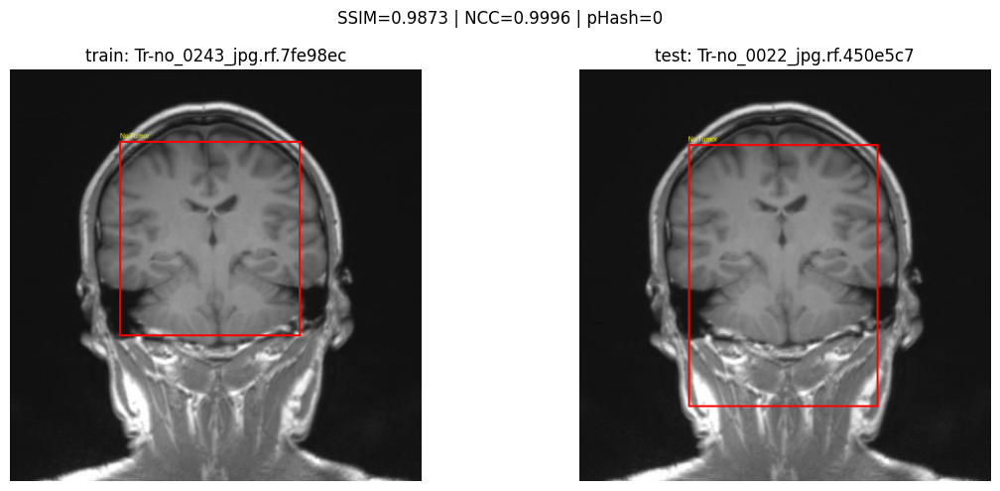

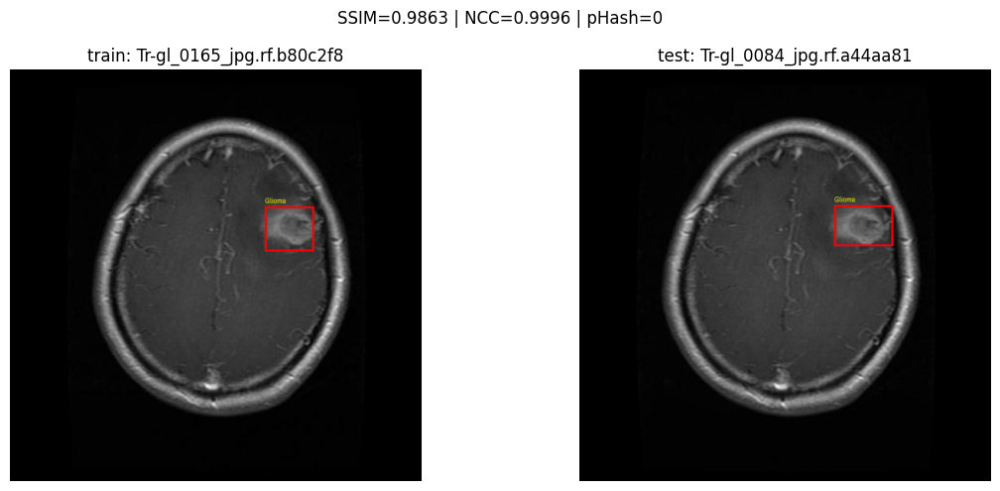

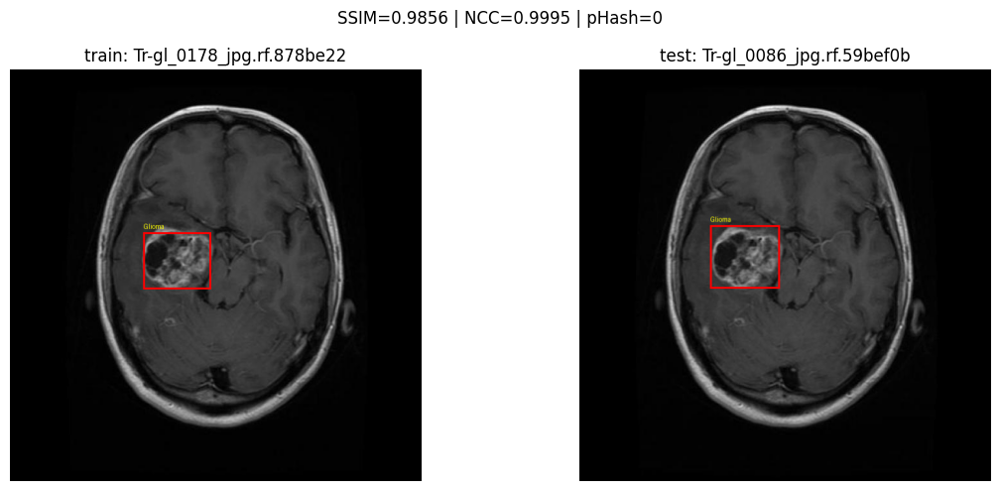

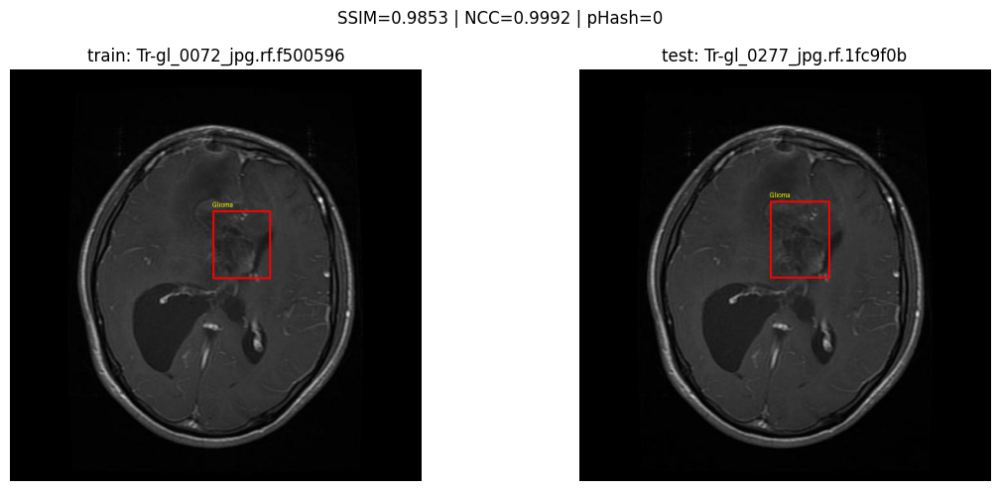

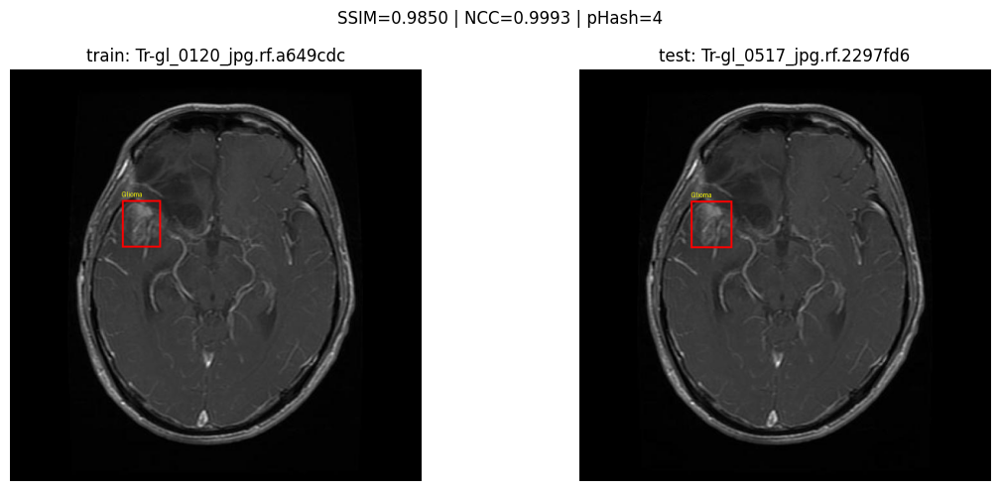

...

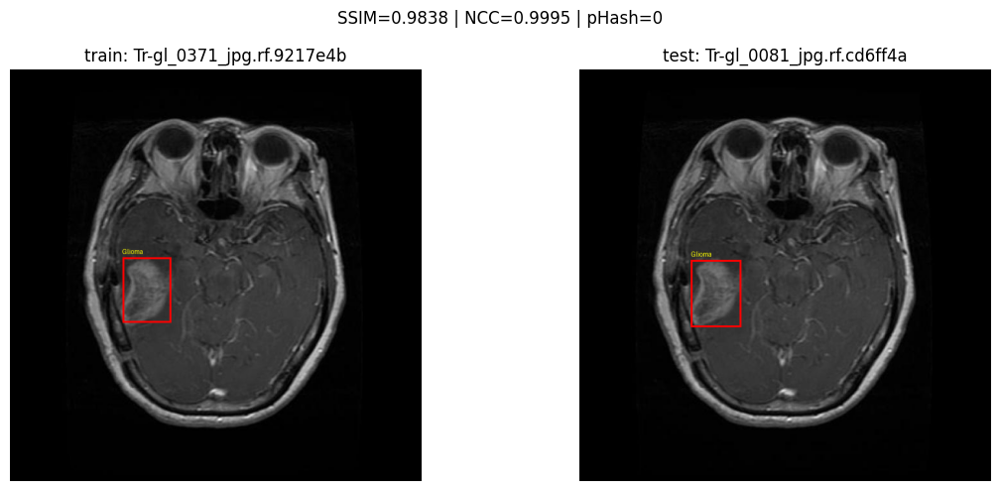

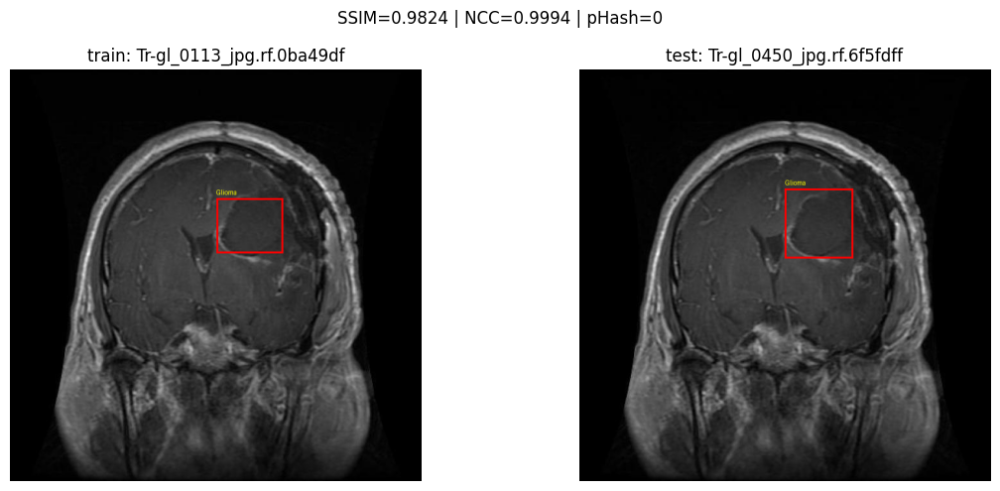

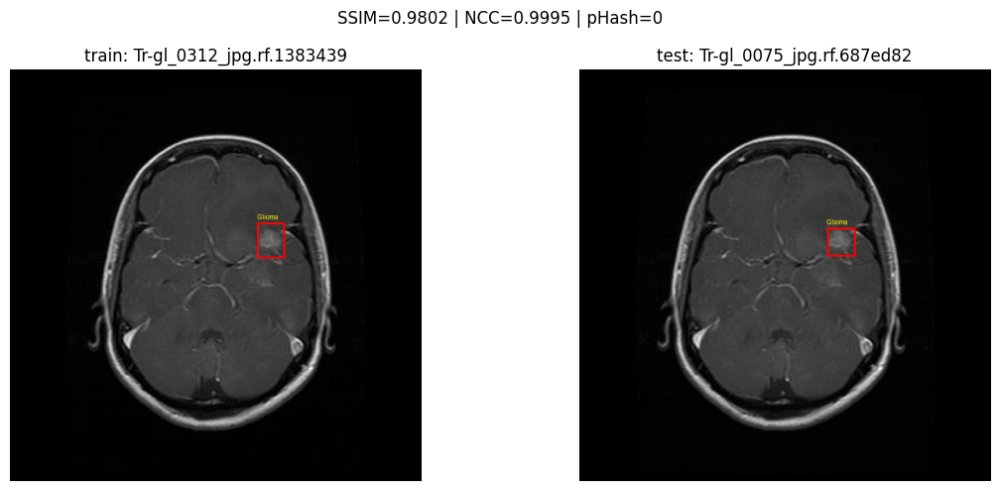

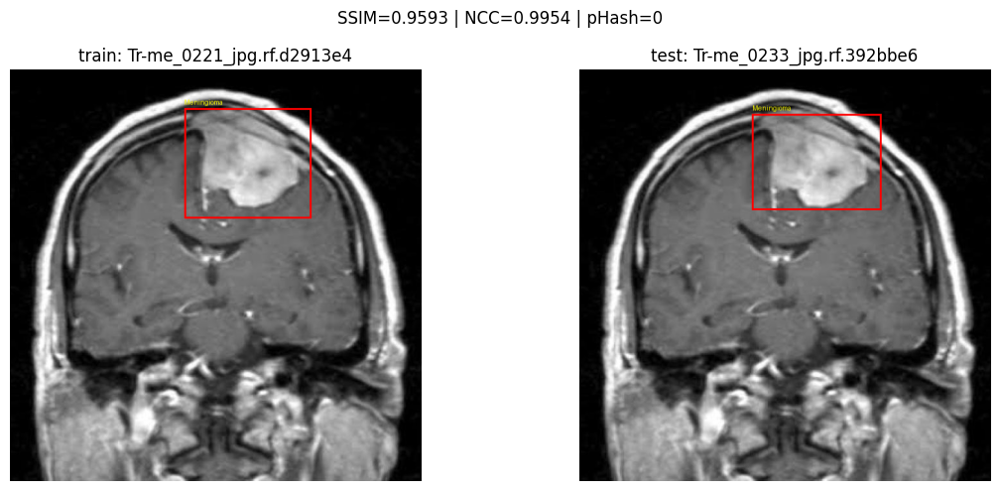

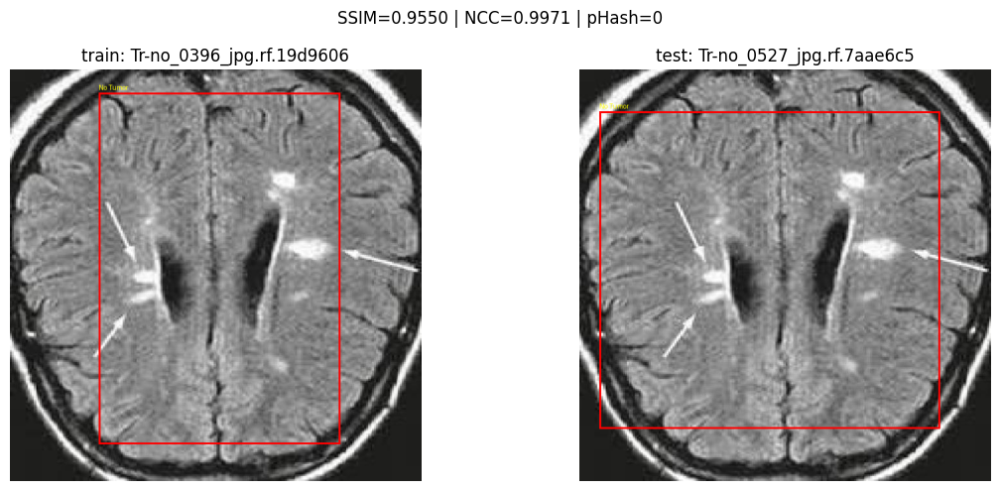

In [93]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

df = pd.read_csv(
    AUDIT_DIR / "Direct_Train_Test_Pair_Audit.csv"
)

candidates = df[df["SSIM"] >= 0.95].copy()
print("Jumlah kandidat:", len(candidates))

CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

def draw_boxes(image, label_path):
    image = ImageOps.exif_transpose(image).convert("RGB")
    draw = ImageDraw.Draw(image)
    w, h = image.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, parts)

            x1 = (xc - bw/2) * w
            y1 = (yc - bh/2) * h
            x2 = (xc + bw/2) * w
            y2 = (yc + bh/2) * h

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )

            draw.text(
                (x1, max(0, y1-15)),
                CLASS_NAMES.get(int(cls), str(int(cls))),
                fill="yellow"
            )

    return image

for i, row in candidates.iterrows():

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, split, filename in [
        (axes[0], "train", row["train_image"]),
        (axes[1], "test", row["test_image"])
    ]:

        image_path = DATASET / split / "images" / filename
        label_path = DATASET / split / "labels" / (
            Path(filename).stem + ".txt"
        )

        with Image.open(image_path) as im:
            image = draw_boxes(im, label_path)

        ax.imshow(image)
        ax.set_title(f"{split}: {filename[:25]}")
        ax.axis("off")

    plt.suptitle(
        f'SSIM={row["SSIM"]:.4f} | '
        f'NCC={row["NCC"]:.4f} | '
        f'pHash={row["pHash_distance"]}'
    )
    plt.tight_layout()
    plt.show()

In [94]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

df = pd.read_csv(
    AUDIT_DIR / "Direct_Train_Test_Pair_Audit.csv"
)

# Kandidat kuat berdasarkan hasil audit numerik
confirmed = df[
    (df["pHash_distance"] <= 4) &
    (df["SSIM"] >= 0.95) &
    (df["NCC"] >= 0.99)
].copy()

confirmed["audit_status"] = "VISUAL_REVIEW_REQUIRED"

# Daftar seluruh file yang terlibat
files = pd.concat([
    confirmed[["train_image"]].rename(
        columns={"train_image": "image"}
    ).assign(split="train"),

    confirmed[["test_image"]].rename(
        columns={"test_image": "image"}
    ).assign(split="test")
], ignore_index=True)

print("Jumlah pasangan kandidat:", len(confirmed))
print("Jumlah file unik:", files["image"].nunique())

print("\nDaftar pasangan:")
display(confirmed)

confirmed.to_csv(
    AUDIT_DIR / "Confirmed_Train_Test_Candidates.csv",
    index=False
)

files.drop_duplicates().to_csv(
    AUDIT_DIR / "Affected_Train_Test_Images.csv",
    index=False
)

print("\nFile audit berhasil disimpan.")

Jumlah pasangan kandidat: 12
Jumlah file unik: 24

Daftar pasangan:


,train_image,test_image,pHash_distance,SSIM,NCC,MAE,audit_status
0,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.987295,0.999624,1.277068,VISUAL_REVIEW_REQUIRED
1,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.986288,0.999583,0.613030,VISUAL_REVIEW_REQUIRED
2,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.985612,0.999452,0.680125,VISUAL_REVIEW_REQUIRED
3,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.985319,0.999213,0.661956,VISUAL_REVIEW_REQUIRED
4,Tr-gl_0120_jpg.rf.a649cdc38ba8e9dc4be7e7150f56...,Tr-gl_0517_jpg.rf.2297fd67191bb4fe70145cb9dab1...,4,0.984990,0.999313,0.722068,VISUAL_REVIEW_REQUIRED
5,Tr-gl_0063_jpg.rf.5406e15c3e54bd4d49d92eb52026...,Tr-gl_0154_jpg.rf.4b3cd239f7611bdc94efd7faa554...,0,0.984710,0.999391,0.675034,VISUAL_REVIEW_REQUIRED
6,Tr-gl_0107_jpg.rf.0b28a07528a965bb72803a204a02...,Tr-gl_0417_jpg.rf.5b07d6e9a8546e45afebaf7bc2bd...,0,0.984483,0.999511,0.788540,VISUAL_REVIEW_REQUIRED
7,Tr-gl_0371_jpg.rf.9217e4b114a5ae55de8327fb8970...,Tr-gl_0081_jpg.rf.cd6ff4a250465f60361ab931fe2c...,0,0.983771,0.999473,0.708611,VISUAL_REVIEW_REQUIRED
8,Tr-gl_0113_jpg.rf.0ba49df9ea54d80d0e6e740382e4...,Tr-gl_0450_jpg.rf.6f5fdffaede01c3b1d195b18bee7...,0,0.982417,0.999416,0.859954,VISUAL_REVIEW_REQUIRED
9,Tr-gl_0312_jpg.rf.1383439af0161e29a269769bdce2...,Tr-gl_0075_jpg.rf.687ed8298bed6c85cb35c9c8f3ec...,0,0.980161,0.999524,0.642634,VISUAL_REVIEW_REQUIRED



File audit berhasil disimpan.


In [95]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

# Cari file audit kemiripan lintas-split
for f in AUDIT_DIR.glob("*.csv"):
    print(f.name)

All_Cross_Split_pHash_Comparisons.csv
Near_Duplicate_Candidates.csv
Test_Near_Duplicate_SSIM_Audit.csv
High_Similarity_Pixel_Audit.csv
Original_Pixel_Comparison.csv
Near_Duplicate_Groups_pHash4.csv
Group_Size_Analysis.csv
Group_Edge_Analysis.csv
Direct_Train_Test_Pair_Audit.csv
Confirmed_Train_Test_Candidates.csv
Affected_Train_Test_Images.csv


In [96]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

files = [
    "All_Cross_Split_pHash_Comparisons.csv",
    "Near_Duplicate_Candidates.csv",
    "Confirmed_Train_Test_Candidates.csv",
    "Direct_Train_Test_Pair_Audit.csv",
    "Near_Duplicate_Groups_pHash4.csv"
]

for filename in files:
    path = AUDIT_DIR / filename
    df = pd.read_csv(path)

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("Jumlah baris:", len(df))
    print("Kolom:", df.columns.tolist())
    display(df.head(5))


FILE: All_Cross_Split_pHash_Comparisons.csv
Jumlah baris: 1391352
Kolom: ['split_a', 'image_a', 'split_b', 'image_b', 'hamming_distance']


,split_a,image_a,split_b,image_b,hamming_distance
0,train,Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c...,valid,Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88f...,32
1,train,Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c...,valid,Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d7...,22
2,train,Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c...,valid,Tr-gl_0015_jpg.rf.f19712315a693c8362217ca98084...,26
3,train,Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c...,valid,Tr-gl_0018_jpg.rf.32814a3e780f52883d520898eced...,26
4,train,Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c...,valid,Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd0...,26



FILE: Near_Duplicate_Candidates.csv
Jumlah baris: 2836
Kolom: ['split_a', 'image_a', 'split_b', 'image_b', 'hamming_distance']


,split_a,image_a,split_b,image_b,hamming_distance
0,valid,Tr-no_0166_jpg.rf.7d3dabdbbdc50d7be0f2af7f43b2...,test,Tr-no_0550_jpg.rf.961727cb5c596daea01f27b939b7...,0
1,train,Tr-gl_0062_jpg.rf.cba5b245f2bbf273efcd7f5b394a...,valid,Tr-gl_0138_jpg.rf.e8214f03282d69d7d7f0dfe48b89...,0
2,train,Tr-gl_0086_jpg.rf.abf910f6581ceaf93a9bbea322ea...,valid,Tr-gl_0178_jpg.rf.5e171245ad03ef1fe2f563aaad85...,0
3,train,Tr-gl_0088_jpg.rf.c10bd9703e67b944ce75cf6b933a...,valid,Tr-gl_0533_jpg.rf.2cd5068dcdaf73625fc5378335a6...,0
4,train,Tr-gl_0082_jpg.rf.09bd70356dc06019c2393eccc461...,valid,Tr-gl_0375_jpg.rf.122db6215f7270b1c5ba89ee1e28...,0



FILE: Confirmed_Train_Test_Candidates.csv
Jumlah baris: 12
Kolom: ['train_image', 'test_image', 'pHash_distance', 'SSIM', 'NCC', 'MAE', 'audit_status']


,train_image,test_image,pHash_distance,SSIM,NCC,MAE,audit_status
0,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.987295,0.999624,1.277068,VISUAL_REVIEW_REQUIRED
1,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.986288,0.999583,0.613030,VISUAL_REVIEW_REQUIRED
2,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.985612,0.999452,0.680125,VISUAL_REVIEW_REQUIRED
3,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.985319,0.999213,0.661956,VISUAL_REVIEW_REQUIRED
4,Tr-gl_0120_jpg.rf.a649cdc38ba8e9dc4be7e7150f56...,Tr-gl_0517_jpg.rf.2297fd67191bb4fe70145cb9dab1...,4,0.984990,0.999313,0.722068,VISUAL_REVIEW_REQUIRED



FILE: Direct_Train_Test_Pair_Audit.csv
Jumlah baris: 109
Kolom: ['train_image', 'test_image', 'pHash_distance', 'SSIM', 'NCC', 'MAE']


,train_image,test_image,pHash_distance,SSIM,NCC,MAE
0,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.987295,0.999624,1.277068
1,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.986288,0.999583,0.613030
2,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.985612,0.999452,0.680125
3,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.985319,0.999213,0.661956
4,Tr-gl_0120_jpg.rf.a649cdc38ba8e9dc4be7e7150f56...,Tr-gl_0517_jpg.rf.2297fd67191bb4fe70145cb9dab1...,4,0.984990,0.999313,0.722068



FILE: Near_Duplicate_Groups_pHash4.csv
Jumlah baris: 536
Kolom: ['group_id', 'split', 'image']


,group_id,split,image
0,1,valid,Tr-gl_0123_jpg.rf.9d9f5d055b1e519033a08a4e6882...
1,1,train,Tr-gl_0060_jpg.rf.196731c0214fbc9b0952087a00a6...
2,2,train,Tr-me_0045_jpg.rf.0b7396eec6d29b8c30bf3a6f2948...
3,2,test,Tr-no_0355_jpg.rf.5b2f13daeaaf08ae40f02be713a6...
4,2,valid,Tr-gl_0136_jpg.rf.477caffa816bf58d20ad8de068f9...


In [97]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

# 1. Distribusi jarak Hamming
df = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv"
)

print("DISTRIBUSI JARAK HAMMING")
display(
    df["hamming_distance"]
    .value_counts()
    .sort_index()
    .rename_axis("Hamming distance")
    .reset_index(name="Jumlah pasangan")
)

# 2. Distribusi pasangan antar-split
df["split_pair"] = (
    df["split_a"].astype(str) + " - " +
    df["split_b"].astype(str)
)

print("\nDISTRIBUSI PASANGAN ANTAR-SPLIT")
display(
    df["split_pair"]
    .value_counts()
    .rename_axis("Kombinasi split")
    .reset_index(name="Jumlah kandidat")
)

# 3. Jumlah gambar unik yang terlibat
images = pd.concat([
    df[["split_a", "image_a"]].rename(
        columns={"split_a": "split", "image_a": "image"}
    ),
    df[["split_b", "image_b"]].rename(
        columns={"split_b": "split", "image_b": "image"}
    )
]).drop_duplicates()

print("\nJUMLAH GAMBAR UNIK TERLIBAT")
display(
    images.groupby("split")["image"]
    .nunique()
    .reset_index(name="Jumlah gambar")
)

print("\nTOTAL GAMBAR UNIK:", len(images))

DISTRIBUSI JARAK HAMMING


,Hamming distance,Jumlah pasangan
0,0,52
1,2,85
2,4,206
3,6,349
4,8,649
5,10,1495



DISTRIBUSI PASANGAN ANTAR-SPLIT


,Kombinasi split,Jumlah kandidat
0,train - valid,1738
1,train - test,842
2,valid - test,256



JUMLAH GAMBAR UNIK TERLIBAT


,split,Jumlah gambar
0,test,202
1,train,977
2,valid,398



TOTAL GAMBAR UNIK: 1577


In [98]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

df = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv"
)

# Kelompokkan berdasarkan kombinasi split dan jarak
summary = (
    df.pivot_table(
        index=["split_a", "split_b"],
        columns="hamming_distance",
        values="image_a",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

print("DISTRIBUSI HAMMING DISTANCE PER SPLIT")
display(summary)

# Hitung kandidat kuat dengan distance <= 4
strong = df[df["hamming_distance"] <= 4]

print("\nKANDIDAT KUAT (HAMMING DISTANCE <= 4)")
display(
    strong.groupby(["split_a", "split_b"])
    .size()
    .reset_index(name="Jumlah pasangan")
)

print("\nTotal kandidat kuat:", len(strong))

DISTRIBUSI HAMMING DISTANCE PER SPLIT


hamming_distance,split_a,split_b,0,2,4,6,8,10
0,train,test,17,24,68,104,205,424
1,train,valid,32,52,126,210,382,936
2,valid,test,3,9,12,35,62,135



KANDIDAT KUAT (HAMMING DISTANCE <= 4)


,split_a,split_b,Jumlah pasangan
0,train,test,109
1,train,valid,210
2,valid,test,24



Total kandidat kuat: 343


In [99]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image, ImageOps
from skimage.metrics import structural_similarity as ssim
from tqdm.auto import tqdm

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/"
    "Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/"
    "Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

pairs = pd.read_csv(
    AUDIT_DIR / "Near_Duplicate_Candidates.csv"
)

pairs = pairs[
    pairs["hamming_distance"] <= 4
].copy()

results = []

for _, row in tqdm(pairs.iterrows(), total=len(pairs)):

    path_a = (
        DATASET / row["split_a"] /
        "images" / row["image_a"]
    )

    path_b = (
        DATASET / row["split_b"] /
        "images" / row["image_b"]
    )

    with Image.open(path_a) as im:
        a = np.asarray(
            ImageOps.exif_transpose(im).convert("L"),
            dtype=np.uint8
        )

    with Image.open(path_b) as im:
        b = np.asarray(
            ImageOps.exif_transpose(im).convert("L"),
            dtype=np.uint8
        )

    # Samakan dimensi jika berbeda
    if a.shape != b.shape:
        b_img = Image.fromarray(b).resize(
            (a.shape[1], a.shape[0]),
            Image.Resampling.LANCZOS
        )
        b = np.asarray(b_img)

    ssim_value = ssim(a, b, data_range=255)

    ncc = np.corrcoef(
        a.astype(float).ravel(),
        b.astype(float).ravel()
    )[0, 1]

    mae = np.mean(
        np.abs(a.astype(float) - b.astype(float))
    )

    results.append({
        "split_a": row["split_a"],
        "image_a": row["image_a"],
        "split_b": row["split_b"],
        "image_b": row["image_b"],
        "pHash_distance": row["hamming_distance"],
        "SSIM": ssim_value,
        "NCC": ncc,
        "MAE": mae
    })

audit_343 = pd.DataFrame(results)

audit_343.to_csv(
    AUDIT_DIR / "Complete_343_Pair_SSIM_NCC_Audit.csv",
    index=False
)

print("Jumlah pasangan diperiksa:", len(audit_343))

print("\nDistribusi kandidat berdasarkan SSIM:")
for threshold in [0.95, 0.97, 0.98, 0.99]:
    print(
        f"SSIM >= {threshold}:",
        (audit_343["SSIM"] >= threshold).sum()
    )

print("\nRingkasan per kombinasi split:")
display(
    audit_343.groupby(["split_a", "split_b"]).agg(
        jumlah=("SSIM", "count"),
        ssim_median=("SSIM", "median"),
        ssim_max=("SSIM", "max"),
        ncc_median=("NCC", "median"),
        mae_median=("MAE", "median")
    ).reset_index()
)

print("\n10 pasangan dengan SSIM tertinggi:")
display(
    audit_343.sort_values("SSIM", ascending=False).head(10)
)

  0%|          | 0/343 [00:00<?, ?it/s]

Jumlah pasangan diperiksa: 343

Distribusi kandidat berdasarkan SSIM:
SSIM >= 0.95: 40
SSIM >= 0.97: 36
SSIM >= 0.98: 35
SSIM >= 0.99: 0

Ringkasan per kombinasi split:


,split_a,split_b,jumlah,ssim_median,ssim_max,ncc_median,mae_median
0,train,test,109,0.746121,0.987295,0.871247,10.664180
1,train,valid,210,0.759177,0.986623,0.880211,9.860922
2,valid,test,24,0.751965,0.984463,0.863047,9.808477



10 pasangan dengan SSIM tertinggi:


,split_a,image_a,split_b,image_b,pHash_distance,SSIM,NCC,MAE
50,train,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,test,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.987295,0.999624,1.277068
90,train,Tr-gl_0160_jpg.rf.b042ea51ad817e525a5ef505f856...,valid,Tr-gl_0064_jpg.rf.0fc8033323aca695bf9aaf8a7ff9...,2,0.986623,0.999481,0.686697
25,train,Tr-gl_0160_jpg.rf.952a1cbdad4ef5654967ca6d7c3b...,valid,Tr-gl_0064_jpg.rf.fe67bb78e6a3f3599250212676f8...,0,0.986608,0.999481,0.686882
26,train,Tr-gl_0165_jpg.rf.34190c0d5ea41ccc6610363f8369...,valid,Tr-gl_0084_jpg.rf.d86ea7c99a8c0936600e2897a5d6...,0,0.986302,0.999583,0.612893
44,train,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,test,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.986288,0.999583,0.613030
27,train,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,test,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.985612,0.999452,0.680125
2,train,Tr-gl_0086_jpg.rf.abf910f6581ceaf93a9bbea322ea...,valid,Tr-gl_0178_jpg.rf.5e171245ad03ef1fe2f563aaad85...,0,0.985606,0.999452,0.680396
31,train,Tr-gl_0484_jpg.rf.7b7ad9cfe210affe779ed3f433c1...,valid,Tr-gl_0117_jpg.rf.08caca5908346413eddf860329e8...,0,0.985565,0.999375,0.920430
48,train,Tr-gl_0277_jpg.rf.32321fa232a1fb1b7f6c2a180e62...,valid,Tr-gl_0072_jpg.rf.317d736b2daced96c4bb766c0ed1...,0,0.985336,0.999215,0.661343
33,train,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,test,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.985319,0.999213,0.661956


In [100]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit"
)

df = pd.read_csv(
    AUDIT_DIR / "Complete_343_Pair_SSIM_NCC_Audit.csv"
)

# Ambil kandidat dengan SSIM minimal 0.95
priority = df[df["SSIM"] >= 0.95].copy()

# Urutkan dari kemiripan tertinggi
priority = priority.sort_values(
    ["SSIM", "NCC"],
    ascending=False
)

# Tambahkan kolom keputusan manual
priority["visual_status"] = "BELUM DIPERIKSA"
priority["catatan"] = ""

output = AUDIT_DIR / "Priority_40_Visual_Review.csv"
priority.to_csv(output, index=False)

print("Jumlah kandidat prioritas:", len(priority))
print("File tersimpan:", output)

display(
    priority[
        [
            "split_a",
            "image_a",
            "split_b",
            "image_b",
            "pHash_distance",
            "SSIM",
            "NCC",
            "MAE",
            "visual_status"
        ]
    ].reset_index(drop=True)
)

Jumlah kandidat prioritas: 40
File tersimpan: /content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit/Priority_40_Visual_Review.csv


,split_a,image_a,split_b,image_b,pHash_distance,SSIM,NCC,MAE,visual_status
0,train,Tr-no_0243_jpg.rf.7fe98ecc436d30ca927aeb59abd3...,test,Tr-no_0022_jpg.rf.450e5c79c994c8f3ccfd6e41b451...,0,0.987295,0.999624,1.277068,BELUM DIPERIKSA
1,train,Tr-gl_0160_jpg.rf.b042ea51ad817e525a5ef505f856...,valid,Tr-gl_0064_jpg.rf.0fc8033323aca695bf9aaf8a7ff9...,2,0.986623,0.999481,0.686697,BELUM DIPERIKSA
2,train,Tr-gl_0160_jpg.rf.952a1cbdad4ef5654967ca6d7c3b...,valid,Tr-gl_0064_jpg.rf.fe67bb78e6a3f3599250212676f8...,0,0.986608,0.999481,0.686882,BELUM DIPERIKSA
3,train,Tr-gl_0165_jpg.rf.34190c0d5ea41ccc6610363f8369...,valid,Tr-gl_0084_jpg.rf.d86ea7c99a8c0936600e2897a5d6...,0,0.986302,0.999583,0.612893,BELUM DIPERIKSA
4,train,Tr-gl_0165_jpg.rf.b80c2f8f10b500b3cf4b8fb6ebfc...,test,Tr-gl_0084_jpg.rf.a44aa8130cb9e42053acb60cbc60...,0,0.986288,0.999583,0.613030,BELUM DIPERIKSA
5,train,Tr-gl_0178_jpg.rf.878be22f8fa5f1824fb906fb0396...,test,Tr-gl_0086_jpg.rf.59bef0b3cef3bf10bfa5f3c2ae2c...,0,0.985612,0.999452,0.680125,BELUM DIPERIKSA
6,train,Tr-gl_0086_jpg.rf.abf910f6581ceaf93a9bbea322ea...,valid,Tr-gl_0178_jpg.rf.5e171245ad03ef1fe2f563aaad85...,0,0.985606,0.999452,0.680396,BELUM DIPERIKSA
7,train,Tr-gl_0484_jpg.rf.7b7ad9cfe210affe779ed3f433c1...,valid,Tr-gl_0117_jpg.rf.08caca5908346413eddf860329e8...,0,0.985565,0.999375,0.920430,BELUM DIPERIKSA
8,train,Tr-gl_0277_jpg.rf.32321fa232a1fb1b7f6c2a180e62...,valid,Tr-gl_0072_jpg.rf.317d736b2daced96c4bb766c0ed1...,0,0.985336,0.999215,0.661343,BELUM DIPERIKSA
9,train,Tr-gl_0072_jpg.rf.f5005968794aa3da98ce004f59e4...,test,Tr-gl_0277_jpg.rf.1fc9f0b20b9a7a81fecd80c7a499...,0,0.985319,0.999213,0.661956,BELUM DIPERIKSA


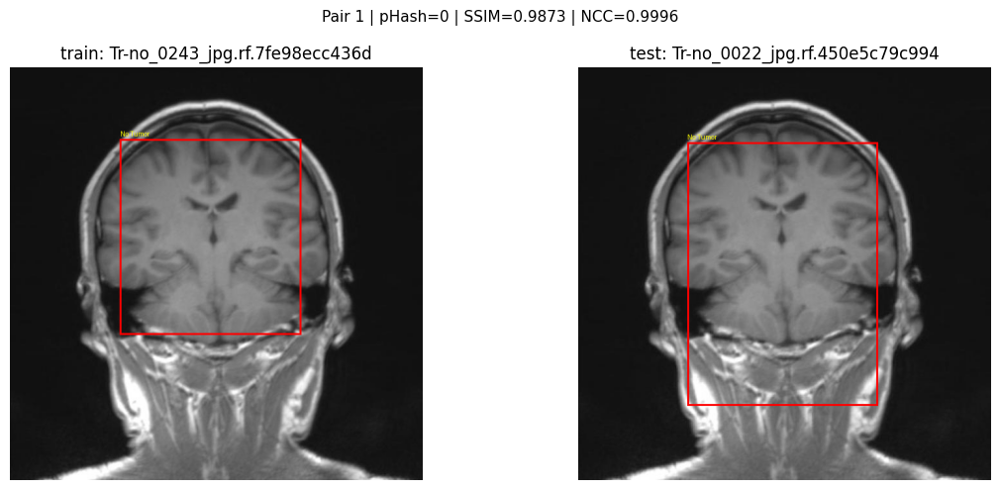

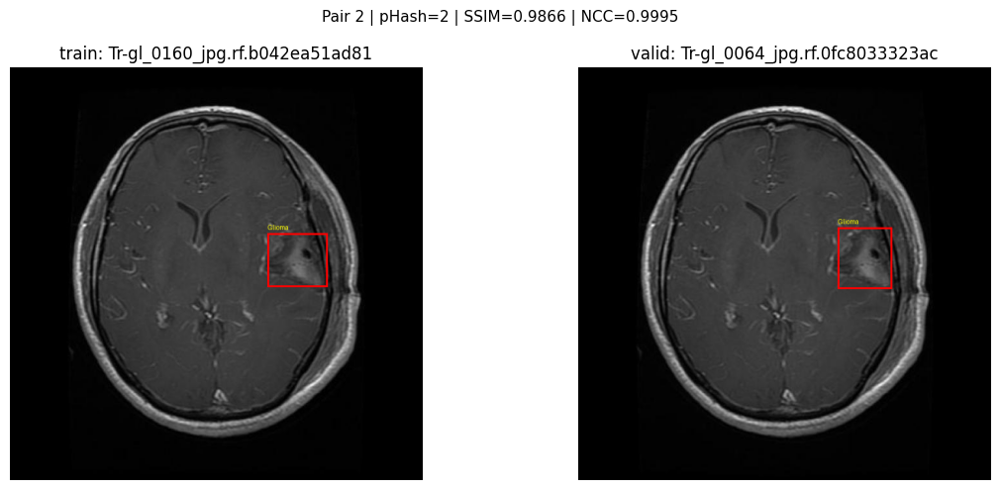

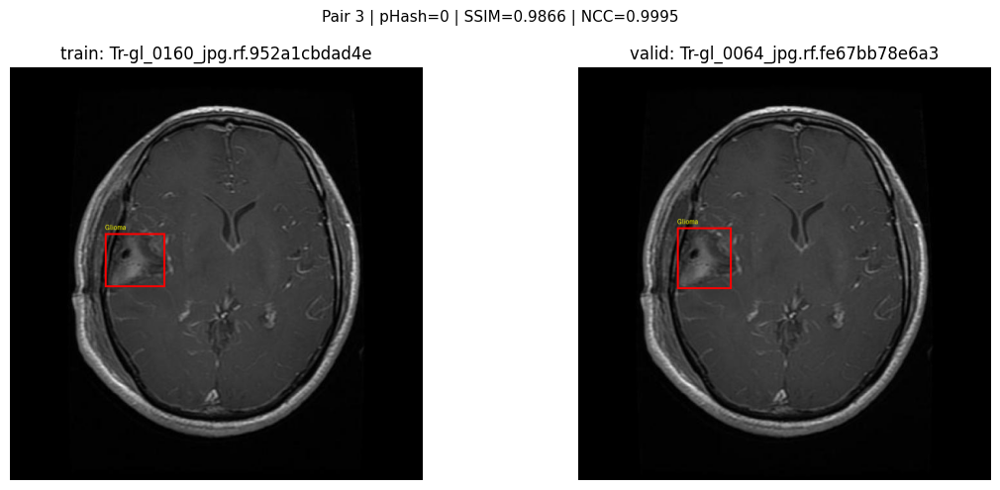

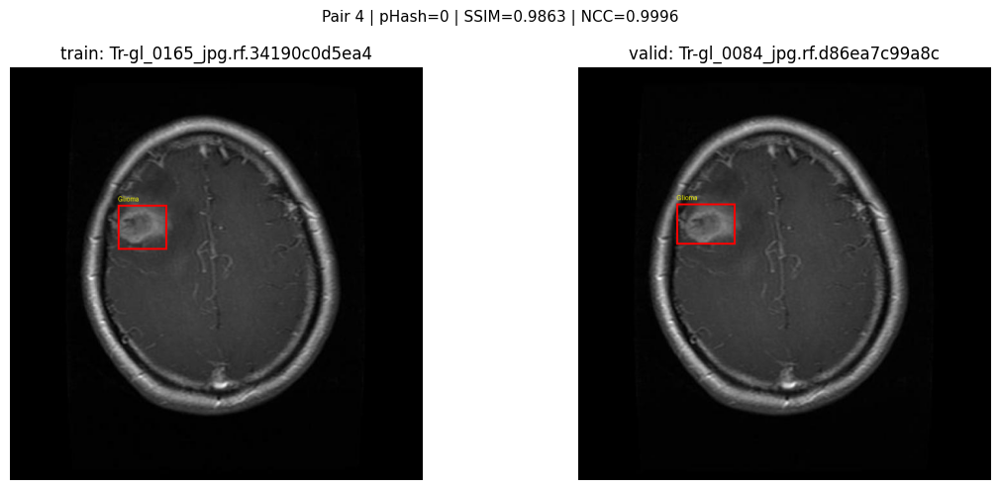

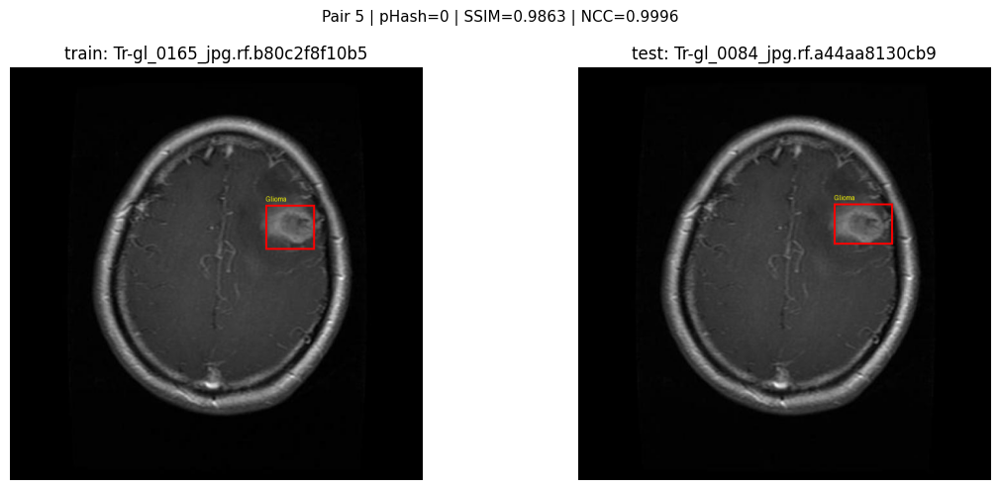

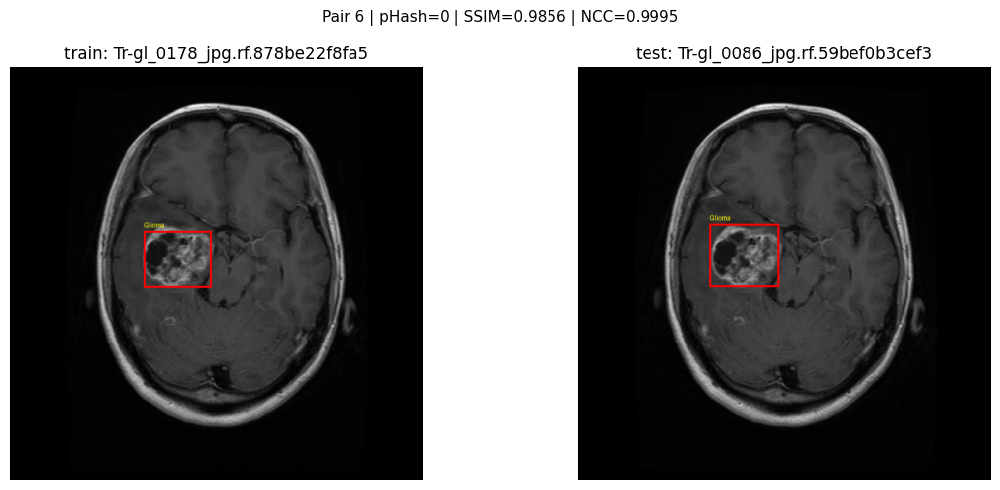

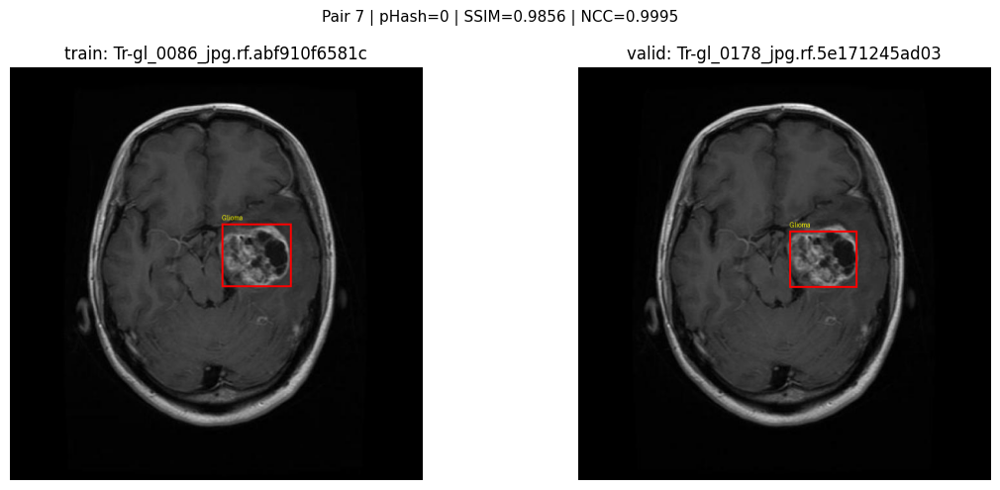

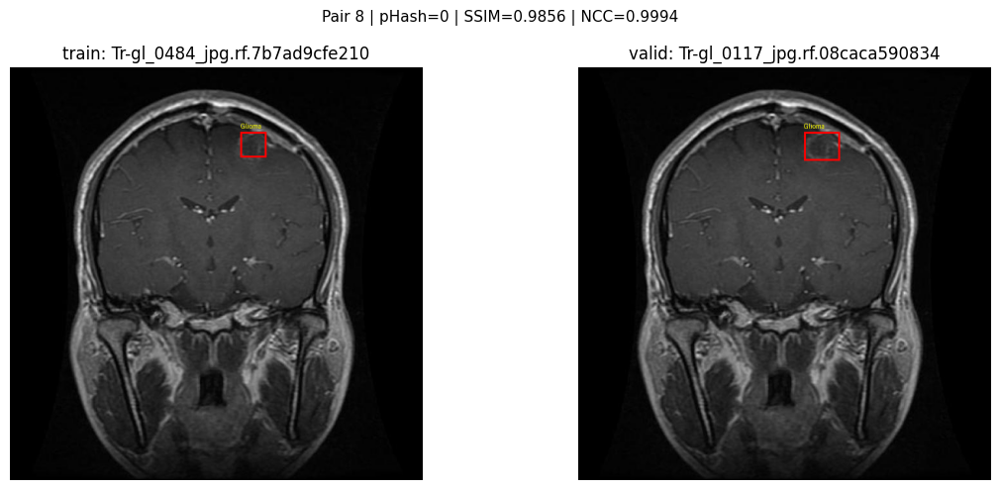

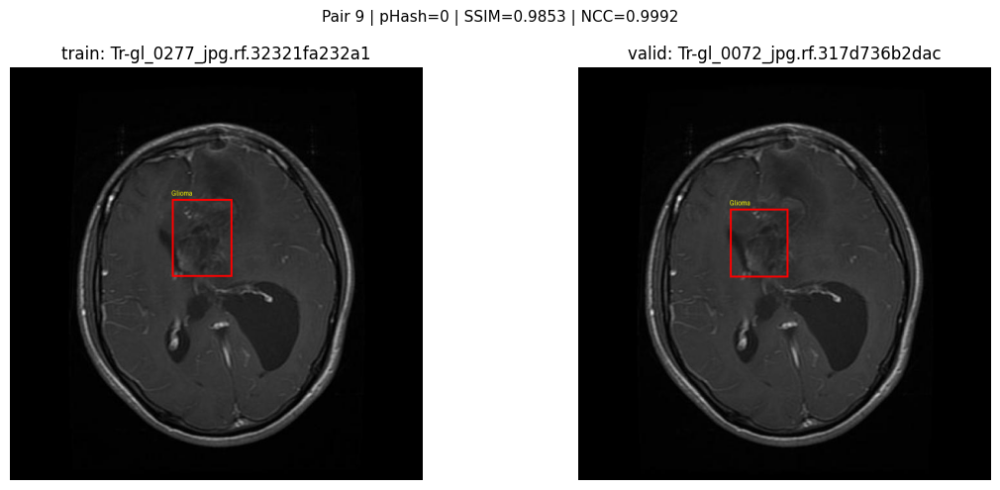

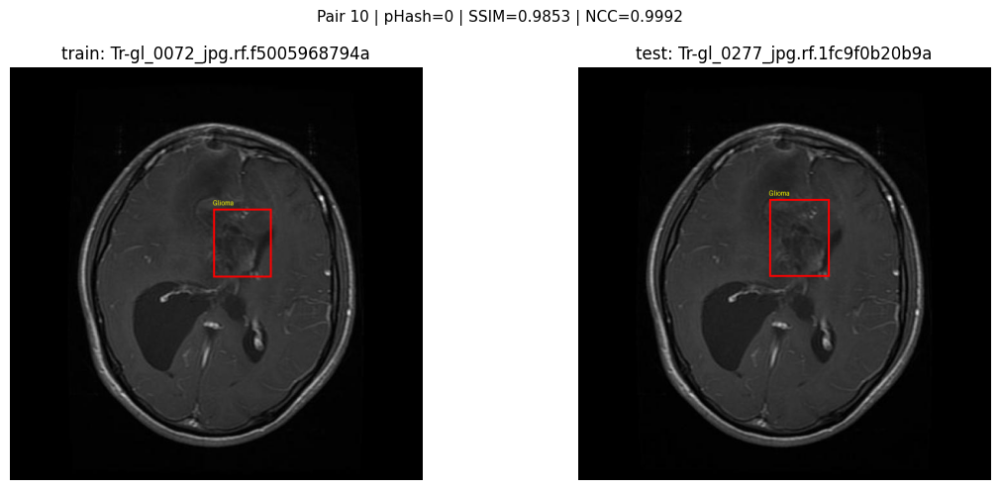

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw
import yaml

AUDIT_DIR = Path(
    "/content/drive/MyDrive/CLEAR-MRI/04_EXPERIMENT/Recovered_Results/Near_Duplicate_Audit"
)

DATASET = Path(
    "/content/drive/MyDrive/CLEAR-MRI/01_DATASET/Original/Labeled-MRI-Brain-Tumor-Dataset-1"
)

priority = pd.read_csv(
    AUDIT_DIR / "Priority_40_Visual_Review.csv"
)

# Nama kelas dari data.yaml
with open(DATASET / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

def draw_boxes(image_path, label_path):
    img = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(img)

    if label_path.exists():
        lines = label_path.read_text().strip().splitlines()

        for line in lines:
            if not line.strip():
                continue

            cls, xc, yc, w, h = map(float, line.split())

            W, H = img.size
            x1 = (xc - w/2) * W
            y1 = (yc - h/2) * H
            x2 = (xc + w/2) * W
            y2 = (yc + h/2) * H

            draw.rectangle((x1, y1, x2, y2), outline="red", width=3)
            draw.text((x1, max(0, y1-15)), names[int(cls)], fill="yellow")

    return img

for idx, row in priority.head(10).iterrows():

    path_a = DATASET / row["split_a"] / "images" / row["image_a"]
    path_b = DATASET / row["split_b"] / "images" / row["image_b"]

    label_a = DATASET / row["split_a"] / "labels" / (
        Path(row["image_a"]).stem + ".txt"
    )
    label_b = DATASET / row["split_b"] / "labels" / (
        Path(row["image_b"]).stem + ".txt"
    )

    img_a = draw_boxes(path_a, label_a)
    img_b = draw_boxes(path_b, label_b)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(img_a)
    axes[0].set_title(f'{row["split_a"]}: {row["image_a"][:30]}')
    axes[0].axis("off")

    axes[1].imshow(img_b)
    axes[1].set_title(f'{row["split_b"]}: {row["image_b"][:30]}')
    axes[1].axis("off")

    fig.suptitle(
        f'Pair {idx+1} | pHash={row["pHash_distance"]} | '
        f'SSIM={row["SSIM"]:.4f} | NCC={row["NCC"]:.4f}',
        fontsize=11
    )

    plt.tight_layout()
    plt.show()